# Example 7.4 — PAINS triage: 5-lipoxygenase inhibitors

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:56:18Z
- **Contents:** 3 exchanges · 27 tool calls · 1 figure · 1 code cell

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/7.4-pains-triage-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 7.4-pains-triage-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 7.4-pains-triage-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/7.4-pains-triage-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 7.4-pains-triage-notebook-rerun.ipynb 7.4-pains-triage-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

5-lipoxygenase has a long literature of natural-product inhibitors and I don't trust much of it. How many of its reported inhibitors carry PAINS alerts, which alerts, and does that track with potency?

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:56:16 UTC
await replay.call(1, 'search_targets', {'query': '5-lipoxygenase'},
                  sha256='fcb899a12a3c3a144ab7441d0749b5bb0d42c20eb2a6519e75f0528fec84f47f')

**Call 1** · `search_targets` · recorded result · sha256 `fcb899a12a3c…`

_20 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 50002716 | 5-lipoxygenase |  |  | Bos taurus | PROTEIN | 235 | 210 | 5-lipoxygenase |
| polymer | 50002672 | Polyunsaturated fatty acid 5-lipoxygenase | P48999 | P48999 | Mus musculus | PROTEIN | 66 | 61 | 5-lipoxygenase |
| polymer | 2263 | Lipoxygenase |  |  | Solanum tuberosum | Enzyme | 37 | 36 | 5-Lipoxygenase |
| polymer | 2259 | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | P09917 | Homo sapiens | Enzyme | 4164 | 2740 | 5-lipoxygenase/FLAP |
| polymer | 5743 | Arachidonate 5-lipoxygenase-activating protein | P20292 | P20292 | Homo sapiens | Enzyme | 4007 | 2380 | 5-lipoxygenase/FLAP |
| polymer | 50001968 | Polyunsaturated fatty acid 5-lipoxygenase | P12527 | P12527 | Rattus norvegicus | PROTEIN | 2113 | 1625 | Arachidonate 5-lipoxygenase |
| polymer | 5790 | Polyunsaturated fatty acid lipoxygenase ALOX15 | P16050 | P16050 | Homo sapiens | Protein | 807 | 655 | 15-Lipoxygenase-1 (15-LOX-1) |
| polymer | 6837 | Arachidonate 5-lipoxygenase-activating protein | A0A087WW23 | A0A087WW23 | Homo sapiens | Protein | 190 | 175 | 5-lipoxygenase-activating protein (FLAP) |
| polymer | 2258 | Polyunsaturated fatty acid lipoxygenase ALOX15 | P12530 | P12530 | Oryctolagus cuniculus | Enzyme | 178 | 143 | 15-Lipoxygenase |
| polymer | 5791 | Polyunsaturated fatty acid lipoxygenase ALOX15B | O15296 | O15296 | Homo sapiens | Protein | 165 | 124 | 15-lipoxygenase 2 |
| polymer | 50001608 | Polyunsaturated fatty acid lipoxygenase ALOX15 | P16469 | P16469 | Sus scrofa | PROTEIN | 115 | 113 | 12/15-lipoxygenase |
| polymer | 50002118 | Polyunsaturated fatty acid lipoxygenase ALOX15B | Q8K4F2 | Q8K4F2 | Rattus norvegicus | PROTEIN | 59 | 58 | Arachidonate 15-lipoxygenase, type II |
| complex | 50000159 | Arachidonate 5-lipoxygenase-activating protein/Polyunsaturated fatty acid 5-lipoxygenase |  |  |  |  | 37 | 20 | 5-Lipoxygenase/5-lipoxygenase activating protein |
| polymer | 50001908 | Polyunsaturated fatty acid lipoxygenase ALOX15 | Q02759 | Q02759 | Rattus norvegicus | PROTEIN | 36 | 35 | 12/15-lipoxygenase |
| polymer | 10054 | Seed linoleate 9S-lipoxygenase-3 | P09186 | P09186 | Glycine max | Enzyme | 23 | 13 | 15-Lipoxygenase (SLO) |
| polymer | 8021 | Arachidonate 15-lipoxygenase | Q9I4G8 | Q9I4G8 | Pseudomonas aeruginosa | Protein | 15 | 15 | 15-Lipoxygenase (LoxA) |
| polymer | 8130 | Lipoxygenase |  |  | Glycine max | Protein | 5 | 5 | 5-Lipoxygenase (5-LOX) |
| polymer | 50004881 | Arachidonate 5-lipoxygenase-activating protein | P20291 | P20291 | Rattus norvegicus | PROTEIN | 4 | 2 | Arachidonate 5-lipoxygenase-activating protein |
| polymer | 50001052 | Polyunsaturated fatty acid lipoxygenase ALOX8 | O35936 | O35936 | Mus musculus | PROTEIN | 3 | 3 | 15-lipoxygenase 2 |
| polymer | 50004806 | Polyunsaturated fatty acid lipoxygenase ALOX15 | P39654 | P39654 | Mus musculus | PROTEIN | 3 | 3 | Arachidonate 15-lipoxygenase |


In [ ]:
# Call 2 · search_targets · ran 2026-11-24 04:56:16 UTC
await replay.call(2, 'search_targets', {'query': 'ALOX5'},
                  sha256='516705c65dc7543a4701fd49d7c770086fa84052f7f070e83570329c76e6d266')

**Call 2** · `search_targets` · recorded result · sha256 `516705c65dc7…`

_8 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 2259 | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | P09917 | Homo sapiens | Enzyme | 4164 | 2740 | ALOX5 |
| polymer | 50001968 | Polyunsaturated fatty acid 5-lipoxygenase | P12527 | P12527 | Rattus norvegicus | PROTEIN | 2113 | 1625 | Alox5 |
| polymer | 50002672 | Polyunsaturated fatty acid 5-lipoxygenase | P48999 | P48999 | Mus musculus | PROTEIN | 66 | 61 | Alox5 |
| polymer | 50007210 | Arachidonate 5-lipoxygenase |  |  | Sus scrofa | PROTEIN | 1 | 1 | ALOX5 |
| polymer | 5743 | Arachidonate 5-lipoxygenase-activating protein | P20292 | P20292 | Homo sapiens | Enzyme | 4007 | 2380 | ALOX5AP |
| polymer | 6837 | Arachidonate 5-lipoxygenase-activating protein | A0A087WW23 | A0A087WW23 | Homo sapiens | Protein | 190 | 175 | ALOX5AP |
| polymer | 50004881 | Arachidonate 5-lipoxygenase-activating protein | P20291 | P20291 | Rattus norvegicus | PROTEIN | 4 | 2 | Alox5ap |
| polymer | 50006851 | Arachidonate 5-lipoxygenase-activating protein | P30355 | P30355 | Mus musculus | PROTEIN | 2 | 2 | Alox5ap |


In [ ]:
# Call 3 · get_target · ran 2026-11-24 04:56:16 UTC
await replay.call(3, 'get_target', {'target_id': 2259},
                  sha256='c6deb2d041908d69184bb9306cd61069a2ef5d780daa6c990fa612dab900760c')

**Call 3** · `get_target` · recorded result · sha256 `c6deb2d04190…`

```json
{
  "target": {
    "target_kind": "polymer",
    "target_id": 2259,
    "name": "Polyunsaturated fatty acid 5-lipoxygenase",
    "uniprot": "P09917",
    "uniprot_raw": "P09917",
    "organism": "Homo sapiens",
    "taxid": "9606",
    "type": "Enzyme",
    "res_count": 674,
    "n_pdb_ids": 9,
    "chembl_id": "CHEMBL215",
    "n_activities": 4164,
    "n_compounds": 2740,
    "unpid2": null,
    "common_name": "HUMAN",
    "topology": "null",
    "weight": "77972.74",
    "pdb_ids": "7TTL,7TTK,7TTJ,6NCF,6N2W,3O8Y,3V92,3V99,3V98"
  },
  "synonyms": [
    "5-LO",
    "LOG5",
    "ALOX5",
    "LOX5_HUMAN",
    "5-Lipoygenase",
    "5-lipoxygenase/FLAP",
    "5-Lipoxygenase (LOX)",
    "5-Lipoxygenase (5-LO)",
    "5-Lipo-oxygenase (5-LOX)",
    "Arachidonate 5-lipoxygenase",
    "Polyunsaturated fatty acid 5-lipoxygenase"
  ]
}
```

**measurements_by_type**: 3 rows

| affinity_type | n_measurements | n_compounds | best_p_affinity |
| --- | --- | --- | --- |
| IC50 | 4036 | 2684 | 9.3 |
| EC50 | 112 | 110 | 8.52 |
| Ki | 16 | 15 | 8.08 |


In [ ]:
# Call 4 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    SELECT COUNT(*) AS n_cpd, SUM(CASE WHEN len(pains) > 0 THEN 1 ELSE 0 END) AS n_pains,
     ROUND(100.0*SUM(CASE WHEN len(pains) > 0 THEN 1 ELSE 0 END)/COUNT(*),2) AS pct
    FROM compound_property
    
"""
await replay.call(4, 'run_sql', {'sql': sql},
                  sha256='ee12bd5acf07fa876e2dd82b5316a18caf46c64cd17a121c4e7d53039f0bdbfc')

**Call 4** · `run_sql` · recorded result · sha256 `ee12bd5acf07…`

_1 row_

| n_cpd | n_pains | pct |
| --- | --- | --- |
| 1466457 | 61904 | 4.22 |


In [ ]:
# Call 5 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    WITH best AS (
      SELECT monomerid, MIN(value) AS best_nm, COUNT(DISTINCT source_id) AS n_sources
      FROM activity
      WHERE polymerid = 2259 AND relation = '=' AND value IS NOT NULL AND affinity_type IN ('IC50','Ki','Kd','EC50')
      GROUP BY monomerid)
    SELECT COUNT(*) AS n_cpd, SUM(CASE WHEN len(p.pains)>0 THEN 1 ELSE 0 END) AS n_pains,
     ROUND(100.0*SUM(CASE WHEN len(p.pains)>0 THEN 1 ELSE 0 END)/COUNT(*),1) AS pct
    FROM best b JOIN compound_property p USING (monomerid)
    
"""
await replay.call(5, 'run_sql', {'sql': sql},
                  sha256='3f91893700a3cfd4c8cde47ffdf79b6a5ed0c87cafa1f56e6c827cf8b136efce')

**Call 5** · `run_sql` · recorded result · sha256 `3f91893700a3…`

_1 row_

| n_cpd | n_pains | pct |
| --- | --- | --- |
| 2411 | 416 | 17.3 |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    WITH best AS (
      SELECT DISTINCT monomerid FROM activity
      WHERE polymerid = 2259 AND relation = '=' AND value IS NOT NULL AND affinity_type IN ('IC50','Ki','Kd','EC50'))
    SELECT a AS alert, COUNT(*) AS n_cpd
    FROM best b JOIN compound_property p USING (monomerid), UNNEST(p.pains) AS t(a)
    GROUP BY a ORDER BY n_cpd DESC, a LIMIT 14
    
"""
await replay.call(6, 'run_sql', {'sql': sql},
                  sha256='e503c6aaa5da0d6721918fdcdf18df8964cddd64bed620b4811d3180c235ac05')

**Call 6** · `run_sql` · recorded result · sha256 `e503c6aaa5da…`

_14 rows_

| alert | n_cpd |
| --- | --- |
| catechol\_A(92) | 128 |
| ene\_five\_het\_B(90) | 89 |
| quinone\_A(370) | 45 |
| anil\_di\_alk\_A(478) | 22 |
| imine\_one\_A(321) | 20 |
| het\_65\_B(7) | 19 |
| quinone\_D(2) | 14 |
| ene\_rhod\_A(235) | 12 |
| mannich\_A(296) | 10 |
| azo\_A(324) | 9 |
| indol\_3yl\_alk(461) | 8 |
| keto\_keto\_beta\_C(7) | 8 |
| anil\_no\_alk(40) | 7 |
| hzone\_phenol\_A(479) | 7 |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    WITH best AS (
      SELECT monomerid, MIN(value) AS best_nm FROM activity
      WHERE polymerid = 2259 AND relation = '=' AND value IS NOT NULL AND affinity_type IN ('IC50','Ki','Kd','EC50')
      GROUP BY monomerid)
    SELECT CASE WHEN best_nm<=10 THEN '1: <=10 nM' WHEN best_nm<=100 THEN '2: 10-100 nM' WHEN best_nm<=1000 THEN '3: 0.1-1 uM' ELSE '4: >1 uM' END AS band,
     COUNT(*) AS n_cpd, SUM(CASE WHEN len(p.pains)>0 THEN 1 ELSE 0 END) AS n_pains,
     ROUND(100.0*SUM(CASE WHEN len(p.pains)>0 THEN 1 ELSE 0 END)/COUNT(*),1) AS pct
    FROM best b JOIN compound_property p USING (monomerid) GROUP BY band ORDER BY band
    
"""
await replay.call(7, 'run_sql', {'sql': sql},
                  sha256='7c2f9af525d50c0dd39c323583708e644b563838ec7bd290c73582ea8a27f0e5')

**Call 7** · `run_sql` · recorded result · sha256 `7c2f9af525d5…`

_4 rows_

| band | n_cpd | n_pains | pct |
| --- | --- | --- | --- |
| 1: \<=10 nM | 42 | 5 | 11.9 |
| 2: 10-100 nM | 415 | 54 | 13 |
| 3: 0.1-1 uM | 958 | 197 | 20.6 |
| 4: \>1 uM | 996 | 160 | 16.1 |


In [ ]:
# Call 8 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    WITH pot AS (
      SELECT monomerid FROM activity WHERE polymerid = 2259 AND relation='=' AND value IS NOT NULL AND affinity_type IN ('IC50','Ki','Kd','EC50')
      GROUP BY monomerid HAVING MIN(value) <= 1000),
    nt AS (
      SELECT monomerid, COUNT(DISTINCT polymerid) AS n_targets FROM activity WHERE monomerid IN (SELECT monomerid FROM pot) GROUP BY monomerid)
    SELECT len(p.pains)>0 AS flagged, COUNT(*) AS n_cpd, ROUND(AVG(n_targets),2) AS mean_targets, MEDIAN(n_targets) AS median_targets
    FROM nt JOIN compound_property p USING (monomerid) GROUP BY 1 ORDER BY 1
    
"""
await replay.call(8, 'run_sql', {'sql': sql},
                  sha256='387db283e1b074f1c8c79a1159ee182f90054bcd11fb24a8645530c72bb61c21')

**Call 8** · `run_sql` · recorded result · sha256 `387db283e1b0…`

_2 rows_

| flagged | n_cpd | mean_targets | median_targets |
| --- | --- | --- | --- |
| False | 1159 | 2.44 | 1 |
| True | 256 | 2.91 | 1 |


**🧠 Assistant**

A lot of them, and the alerts all tell the same story. But the alert does **not** track potency, so the alert count on its own will not triage this target.

## How many

Of the 2,411 ALOX5 compounds (polymerid 2259, P09917) with an exact `=` IC50/Ki/Kd/EC50 value, **416 carry at least one PAINS alert, 17.3%**. The database-wide rate is 61,904 of 1,466,457 compounds, **4.22%**. 5-LOX is enriched about four-fold.

```sql
-- database-wide baseline
SELECT COUNT(*) AS n_cpd,
       SUM(CASE WHEN len(pains) > 0 THEN 1 ELSE 0 END) AS n_pains
FROM compound_property;
```

Note that `compound_property.pains` is an **empty list**, not NULL, for a compound with no alert: `WHERE pains IS NOT NULL` silently matches everything. Use `len(pains) > 0`.

## Which alerts

| PAINS alert | compounds |
|---|---|
| catechol_A(92) | 128 |
| ene_five_het_B(90) | 89 |
| quinone_A(370) | 45 |
| anil_di_alk_A(478) | 22 |
| imine_one_A(321) | 20 |
| het_65_B(7) | 19 |
| quinone_D(2) | 14 |
| ene_rhod_A(235) | 12 |
| mannich_A(296) | 10 |
| azo_A(324) | 9 |
| indol_3yl_alk(461) | 8 |
| keto_keto_beta_C(7) | 8 |

(A compound can carry more than one alert, so the counts add up to more than 416.)

This is not an assortment of unrelated filters. Catechols and quinones lead, followed by rhodanine-like and other five-membered-ring enes, imine-ones, Mannich bases and azo dyes: redox-active or reactive chemotypes, almost to the exclusion of everything else.

That is the part worth pausing on, because it is mechanistically specific to this target. 5-LOX is a non-heme **iron** dioxygenase: the resting enzyme is Fe(III) and has to be oxidised to turn over. The standard assay reads the conjugated-diene product by absorbance around 234 nm, or measures 5-HETE/LTB4 formation. A compound that reduces Fe(III) to Fe(II) switches the enzyme off without occupying any pocket, and a coloured or UV-absorbing compound interferes with the readout directly. (That is background chemistry, not something BindingDB records; the data show which chemotypes are flagged, not why they inhibit.)

So the alert list is, in effect, naming the two ways you can get a potent-looking number out of this assay without having an inhibitor. That is a more useful thing to know than "17% are flagged".

## Does it track potency?

No.

| best measured value | compounds | with a PAINS alert | % |
|---|---|---|---|
| ≤ 10 nM | 42 | 5 | 11.9 |
| 10-100 nM | 415 | 54 | 13.0 |
| 0.1-1 µM | 958 | 197 | 20.6 |
| > 1 µM | 996 | 160 | 16.1 |

If PAINS alerts marked artefactually potent compounds, the flagged fraction would climb towards the potent end. It does the opposite: the peak is in the 0.1-1 µM band, and the **most potent band is the least flagged of all four**. Flagged compounds are spread through the whole dataset rather than concentrated at the top.

Promiscuity does not separate them either. Among the 1,415 compounds with a ≤1 µM value, the 256 flagged ones are measured against a mean of 2.91 targets and the 1,159 clean ones against 2.44, and both medians are 1.

So neither "it has an alert" nor "it is suspiciously potent" nor "it hits everything" sorts this set by itself. The next turn is where the evidence actually is.

## Exchange 2

**👤 User**

Then take the potent end seriously. Which of the potent ones should I actually distrust, and on what evidence?

In [ ]:
# Call 9 · find_ligands_for_target · ran 2026-11-24 04:56:16 UTC
await replay.call(9, 'find_ligands_for_target', {'target_id': 2259, 'max_value_nm': 30, 'limit': 100},
                  sha256='9ea971e6181c53c2da6297b3eefb82d70efa0662fdd77774d88f347f92d69780')

**Call 9** · `find_ligands_for_target` · recorded result · sha256 `9ea971e6181c…`

_100 rows, truncated at the limit_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 51002612 | IC50 | = | 0.5 | nM | 9.3 | 50182303 | 6-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.35 | 2.1 |  | 2 |
| 51002619 | IC50 | = | 0.5 | nM | 9.3 | 50182306 | 7-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-4-phenyl-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.36 | 2.24 |  | 2 |
| 51517804 | IC50 | = | 0.75 | nM | 9.12 | 50610906 | CHEMBL5267320 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282337 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.38 | 3.61 |  | 1 |
| 51517803 | IC50 | = | 0.77 | nM | 9.11 | 50610905 | CHEMBL5267685 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282337 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.46 | 4.15 |  | 1 |
| 51002614 | IC50 | = | 0.8 | nM | 9.1 | 50182308 | 7-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.37 | 2.44 |  | 2 |
| 51517805 | IC50 | = | 0.8 | nM | 9.1 | 50610907 | CHEMBL5270325 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282337 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.57 | 6.87 |  | 1 |
| 51002620 | IC50 | = | 0.9 | nM | 9.05 | 50182304 | 7-((3-fluoro-5-(3-hydroxypentan-3-yl)phenoxy)methyl)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.4 | 3.27 |  | 2 |
| 51090514 | IC50 | = | 1.6 | nM | 8.8 | 50029559 | MK-591 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290927 (CHEMBL3118900) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.29 | -0.21 |  | 1 |
| 51002621 | IC50 | = | 1.9 | nM | 8.72 | 50182302 | 7-((3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenoxy)methyl)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.32 | 2.09 |  | 1 |
| 51002616 | IC50 | = | 2.3 | nM | 8.64 | 50182300 | L-746530 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.34 | 3.83 |  | 2 |
| 51002613 | IC50 | = | 2.7 | nM | 8.57 | 50182305 | 7-((3-fluoro-5-(1-hydroxy-1-(thiazol-2-yl)propyl)phenoxy)methyl)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.33 | 2.15 |  | 1 |
| 50073146 | IC50 | = | 3 | nM | 8.52 | 50045643 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(quinolin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.29 | 0.36 |  | 1 |
| 50073191 | IC50 | = | 3 | nM | 8.52 | 50045673 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-\[2-(5-phenyl-pyridin-2-yl)-ethyl\]-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.03 |  | 1 |
| 50200285 | IC50 | = | 3 | nM | 8.52 | 50110484 | 3-((3-fluoro-5-(1-methoxycyclohexyl)phenoxy)methyl)-1-(4-(methylsulfonyl)phenyl)-5-phenyl-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3813 | 11859001 | 10.1016/s0960-894x(02)00013-6 | 2002 | 0.31 | 3.21 |  | 2 |
| 50832809 | EC50 | = | 3 | nM | 8.52 | 50172379 | (8E,10E)-(5S,9R)-20,20,20-Trifluoro-5,12-dihydroxy-icosa-6,8,10,14-tetraenoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_321097 (CHEMBL882067) | 16134928 | 10.1021/jm050524f | 2005 | 0.43 | 3.82 |  | 2 |
| 51002622 | IC50 | = | 3 | nM | 8.52 | 50182307 | 7-((3-fluoro-5-((1S,3S,5R)-3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]octan-3-yl)phenoxy)methyl)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.34 | 4.03 |  | 1 |
| 51002615 | IC50 | = | 3.7 | nM | 8.43 | 50182299 | 7-((3-fluoro-5-(1-hydroxy-1-(pyridin-2-yl)propyl)phenoxy)methyl)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.33 | 2.62 |  | 1 |
| 51002623 | IC50 | = | 3.7 | nM | 8.43 | 50182298 | 7-((3-fluoro-5-((1S,3S,5R)-3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]octan-3-yl)phenoxy)methyl)-4-phenyl-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.33 | 3.53 |  | 1 |
| 50082254 | IC50 | = | 4 | nM | 8.4 | 50004424 | CHEMBL3238463 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.46 | 4.49 |  | 1 |
| 51002611 | IC50 | = | 4.3 | nM | 8.37 | 50182301 | 4-(4-chlorophenyl)-7-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.32 | 0.65 |  | 1 |
| 50082255 | IC50 | = | 6 | nM | 8.22 | 50004425 | CHEMBL3238207 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.51 | 5.19 |  | 1 |
| 50024406 | IC50 | = | 7 | nM | 8.15 | 50016991 | 7-Fluoro-2-(4-methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.47 | 3.01 |  | 1 |
| 50799688 | IC50 | = | 7 | nM | 8.15 | 50085160 | L-674636 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 0.8 |  | 1 |
| 51553352 | IC50 | = | 7 | nM | 8.15 | 50624927 | CHEMBL5398068 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.62 | 4.23 | catechol\_A(92) | 1 |
| 51553356 | IC50 | = | 7 | nM | 8.15 | 50624931 | CHEMBL5421129 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.53 | 3.02 | catechol\_A(92) | 1 |
| 50610952 | IC50 | = | 7.9 | nM | 8.1 | 50331806 | methyl 3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxylate | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.95 |  | 1 |
| 50073123 | IC50 | = | 8 | nM | 8.1 | 50041161 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(2H-tetrazol-5-yl)-propyl\]-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.25 |  | 1 |
| 50799750 | IC50 | = | 8 | nM | 8.1 | 50052018 | MK-591 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.27 | 0.42 |  | 1 |
| 50997309 | IC50 | = | 8 | nM | 8.1 | 50409117 | CHEMBL2093045 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.35 | 2.19 |  | 1 |
| 51090513 | IC50 | = | 8 | nM | 8.1 | 50446686 | CHEMBL3113612 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290926 (CHEMBL3118899) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.38 | 6.44 |  | 3 |
| 51553354 | IC50 | = | 8 | nM | 8.1 | 50624929 | CHEMBL5395696 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.5 | 3.27 | catechol\_A(92) | 1 |
| 51090503 | Ki | = | 8.4 | nM | 8.08 | 50446681 | CHEMBL3113617 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290921 (CHEMBL3118894) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.4 | 6.51 |  | 2 |
| 50799732 | IC50 | = | 9 | nM | 8.05 | 50085202 | 2-{4-(4-Fluoro-phenyl)-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-butoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.56 |  | 1 |
| 51090502 | Ki | = | 9.9 | nM | 8 | 50446680 | CHEMBL3113618 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290921 (CHEMBL3118894) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.29 | 4.34 |  | 2 |
| 50047277 | IC50 | = | 10 | nM | 8 | 50031153 | \[1-{4-\[4-((S)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-eth-(E)-ylideneaminooxy\]-acetonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.41 | 2.84 |  | 1 |
| 50064442 | IC50 | = | 10 | nM | 8 | 50000845 | 4-Methoxy-4-\[3-(naphthalen-2-ylmethoxy)-phenyl\]-tetrahydro-pyran | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.42 | 2.93 |  | 1 |
| 50082256 | IC50 | = | 10 | nM | 8 | 50004426 | CHEMBL3238465 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.5 | 4.94 |  | 1 |
| 50258023 | IC50 | = | 10 | nM | 8 | 50038460 | CHEMBL3353726 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432944 (CHEMBL3383919) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.52 | 3.16 |  | 1 |
| 50799763 | IC50 | = | 10 | nM | 8 | 50085229 | {3-Methyl-3-phenyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-butoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.69 |  | 1 |
| 50799770 | IC50 | = | 10 | nM | 8 | 50085231 | {2-Butyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-hexyloxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.06 |  | 1 |
| 51553353 | IC50 | = | 10 | nM | 8 | 50624928 | CHEMBL5413117 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.52 | 3.68 | catechol\_A(92) | 1 |
| 51553355 | IC50 | = | 10 | nM | 8 | 50624930 | CHEMBL5401317 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.5 | 2.93 | catechol\_A(92) | 1 |
| 50024413 | IC50 | = | 11 | nM | 7.96 | 50016986 | 7-Chloro-2-(4-methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.31 |  | 1 |
| 50073122 | IC50 | = | 11 | nM | 7.96 | 50045654 | N-{4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-3,3-dimethyl-butyryl}-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -0.1 |  | 1 |
| 50073177 | IC50 | = | 11 | nM | 7.96 | 50045679 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-(5-phenyl-pyridin-2-ylmethylsulfanyl)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.1 |  | 1 |
| 50610958 | IC50 | = | 11 | nM | 7.96 | 50331797 | 1-(3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophen-2-yl)ethanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.39 |  | 1 |
| 51002617 | IC50 | = | 11.6 | nM | 7.94 | 50182310 | 7-((3-fluoro-5-((1S,3S,5R)-3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]octan-3-yl)phenoxy)methyl)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.3 | 2.9 |  | 1 |
| 50024404 | IC50 | = | 12 | nM | 7.92 | 50016990 | 2-(4-Methoxy-benzyl)-3,7-dimethyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.61 |  | 1 |
| 50073180 | IC50 | = | 12 | nM | 7.92 | 50045663 | 4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-3,3-dimethyl-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.14 |  | 1 |
| 50073183 | IC50 | = | 12 | nM | 7.92 | 50045640 | 3-\[1-(4-Chloro-benzyl)-6-(5-methoxy-pyridin-2-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.29 | 0.9 |  | 1 |
| 50024427 | IC50 | = | 13 | nM | 7.89 | 50017001 | 7-Chloro-2-(2,4-dimethoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.42 | 2.23 |  | 1 |
| 50038732 | IC50 | = | 13 | nM | 7.89 | 50029577 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.25 | -0.55 |  | 3 |
| 50107404 | IC50 | = | 13 | nM | 7.89 | 50163748 | (E)-3,5-Bis\[beta-(4-Hydroxy-3-methoxyphenyl)-ethenyl\]-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.4 | 3.71 |  | 3 |
| 50107405 | IC50 | = | 13 | nM | 7.89 | 50020584 | CHEMBL2413471 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.43 | 4.21 |  | 3 |
| 50107406 | IC50 | = | 13 | nM | 7.89 | 50020589 | CHEMBL3290441 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.29 | 0.69 |  | 3 |
| 50107407 | IC50 | = | 13 | nM | 7.89 | 22334 | BW4C | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.51 | 4.16 |  | 4 |
| 50799698 | IC50 | = | 13 | nM | 7.89 | 50085170 | 2-{Cycloheptyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.59 |  | 1 |
| 51517797 | IC50 | = | 13 | nM | 7.89 | 50610902 | CHEMBL5290007 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.47 | 3.52 |  | 1 |
| 50064441 | IC50 | = | 14 | nM | 7.85 | 50040423 | 7-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.3 | 1.44 |  | 2 |
| 50799764 | IC50 | = | 14 | nM | 7.85 | 50085227 | 2-{\[2-Chloro-4-(quinolin-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.28 |  | 1 |
| 50799766 | IC50 | = | 14 | nM | 7.85 | 50085226 | {\[2-Chloro-4-(5-fluoro-benzothiazol-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 1.47 |  | 1 |
| 50799769 | IC50 | = | 14 | nM | 7.85 | 50085230 | 2-{2-Butyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-hexyloxyimino}-propionic acid (2H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 0.52 |  | 1 |
| 51090512 | IC50 | = | 14 | nM | 7.85 | 50446685 | CHEMBL3113613 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290926 (CHEMBL3118899) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.28 | 4.1 |  | 1 |
| 51517798 | IC50 | = | 14 | nM | 7.85 | 50610903 | CHEMBL5284118 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.47 | 3.48 |  | 1 |
| 50781867 | IC50 | = | 15 | nM | 7.82 | 50059717 | 4-(furan-3-yl)-7-((6-(4-hydroxytetrahydro-2H-pyran-4-yl)pyridin-2-yl)methoxy)-2-naphthonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3794 (CHEMBL619869) | 9288168 | 10.1021/jm970046b | 1997 | 0.33 | 2.88 |  | 2 |
| 50799731 | IC50 | = | 15 | nM | 7.82 | 50085159 | 2-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.91 |  | 2 |
| 50073140 | IC50 | = | 16 | nM | 7.8 | 50045657 | 2,2-Dimethyl-3-\[4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-1-(5-phenyl-pyridin-2-ylmethyl)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -1.28 |  | 1 |
| 50799691 | IC50 | = | 16 | nM | 7.8 | 50085163 | 2-{Cyclopentyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 2.28 |  | 1 |
| 50799711 | IC50 | = | 17 | nM | 7.77 | 50085181 | {Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 2.25 |  | 1 |
| 50799725 | IC50 | = | 17 | nM | 7.77 | 50085182 | (E)-4-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-pentanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.08 |  | 1 |
| 50799760 | IC50 | = | 17 | nM | 7.77 | 50085232 | 7-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-octanoic acid (0.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | -0.09 |  | 1 |
| 51517799 | IC50 | = | 17 | nM | 7.77 | 50610904 | CHEMBL5267222 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.44 | 4.43 |  | 1 |
| 50799728 | IC50 | = | 18 | nM | 7.74 | 50085196 | {Cycloheptyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.83 |  | 1 |
| 50073119 | IC50 | = | 19 | nM | 7.72 | 50045647 | 5-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-4,4-dimethyl-pentanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.73 |  | 1 |
| 50610955 | IC50 | = | 19 | nM | 7.72 | 50331794 | 1,1,1-trifluoro-2-(1-((2-(hydroxymethyl)-3-phenylbenzo\[b\]thiophen-6-yl)methyl)-1H-1,2,3-triazol-4-yl)butan-2-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.86 |  | 1 |
| 50024401 | IC50 | = | 20 | nM | 7.7 | 50016987 | 7-Chloro-2-(4-methoxy-benzyl)-3,5-dipropyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.41 | 1.4 |  | 1 |
| 50024424 | IC50 | = | 20 | nM | 7.7 | 50017000 | 5-Allyl-7-chloro-2-(4-methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.44 | 2.27 |  | 1 |
| 50047252 | IC50 | = | 20 | nM | 7.7 | 50031128 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.35 | 3.48 |  | 1 |
| 50047260 | IC50 | = | 20 | nM | 7.7 | 50031136 | 1-{4-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 1.94 |  | 1 |
| 50047273 | IC50 | = | 20 | nM | 7.7 | 50031149 | 6-\[4-(4-Methoxy-tetrahydro-pyran-4-yl)-5-methyl-thiophen-2-ylsulfanyl\]-1-methyl-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 2.93 |  | 1 |
| 50064436 | IC50 | = | 20 | nM | 7.7 | 50040419 | 7-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.29 | 1.29 |  | 1 |
| 50065539 | IC50 | = | 20 | nM | 7.7 | 50041156 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.25 | -0.35 |  | 1 |
| 50065553 | IC50 | = | 20 | nM | 7.7 | 50041160 | N-(2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-butyryl)-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | 0.27 |  | 1 |
| 50073172 | IC50 | = | 20 | nM | 7.7 | 50045664 | 3-\[1-(4-Chloro-benzyl)-6-(isoquinolin-3-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.46 |  | 1 |
| 50121388 | IC50 | = | 20 | nM | 7.7 | 50059715 | 4-Furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.31 | 3.03 |  | 3 |
| 50462622 | IC50 | = | 20 | nM | 7.7 | 50012827 | PHENOXAZINE | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4044 |  | 10.1016/S0960-894X(00)80241-3 | 1991 | 0.75 | 4.16 |  | 1 |
| 50760052 | IC50 | = | 20 | nM | 7.7 | 50006807 | 4-({(3-Fluoro-benzyl)-\[4-(quinolin-2-ylmethoxy)-phenyl\]-amino}-methyl)-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3834 (CHEMBL875087) | 1635053 | 10.1021/jm00092a001 | 1992 | 0.29 | 0.84 | anil\_di\_alk\_C(246) | 1 |
| 50760188 | IC50 | = | 20 | nM | 7.7 | 50000829 | ZD-2138 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.36 | 3.79 |  | 3 |
| 50760669 | EC50 | = | 20 | nM | 7.7 | 50001176 | 2-(5-Chloro-benzothiazol-2-ylsulfanyl)-ethylamine-N-hydroxy-N-methyl carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.56 | 4.63 |  | 1 |
| 50760681 | EC50 | = | 20 | nM | 7.7 | 50001187 | 3-(5-Chloro-benzothiazol-2-ylsulfanyl)-N-hydroxy-N-methyl-propionamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.59 | 4.42 |  | 1 |
| 50799689 | IC50 | = | 20 | nM | 7.7 | 50085161 | {Cyclohexyl-\[3-methyl-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid (0.4H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.87 |  | 1 |
| 50799702 | IC50 | = | 20 | nM | 7.7 | 50085173 | 2-{Adamantan-2-yl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 1.3 |  | 1 |
| 50799710 | IC50 | = | 20 | nM | 7.7 | 50085179 | {Cyclohexyl-\[2-methoxy-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 2.17 |  | 1 |
| 50799724 | IC50 | = | 20 | nM | 7.7 | 50085194 | 2-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-4-phenyl-butyric acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.27 | 0.17 |  | 1 |
| 50799726 | IC50 | = | 20 | nM | 7.7 | 50085192 | 2-{Cyclohexyl-\[4-(6-fluoro-quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.65 |  | 1 |
| 50799727 | IC50 | = | 20 | nM | 7.7 | 50085195 | 2-{Cyclohexyl-\[4-(4-phenyl-thiazol-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.21 |  | 1 |
| 50799741 | IC50 | = | 20 | nM | 7.7 | 50085203 | 2-{Cyclohexyl-\[3-methyl-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid (0.1H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.48 |  | 1 |
| 50799745 | IC50 | = | 20 | nM | 7.7 | 50085217 | 2-{2-Cyclohexyl-2-\[4-(quinolin-2-ylmethoxy)-phenyl\]-ethoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.75 |  | 1 |
| 50997308 | IC50 | = | 20 | nM | 7.7 | 50409116 | CHEMBL2110176 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.01 |  | 1 |
| 51517773 | IC50 | = | 20 | nM | 7.7 | 50610884 | CHEMBL5280920 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282321 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.3 | 0.72 | ene\_five\_het\_G(10) | 1 |


In [ ]:
# Call 10 · find_ligands_for_target · ran 2026-11-24 04:56:16 UTC
arguments = {
    'target_id': 2259,
    'max_value_nm': 30,
    'limit': 100,
    'properties': {'exclude_alerts': ['pains']},
}
await replay.call(10, 'find_ligands_for_target', arguments,
                  sha256='3713cf14bd9ac0f83b40ef98bb911bc39602a00c8088561b1ea4bb870379c7f5')

**Call 10** · `find_ligands_for_target` · recorded result · sha256 `3713cf14bd9a…`

_100 rows, truncated at the limit_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 51002612 | IC50 | = | 0.5 | nM | 9.3 | 50182303 | 6-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.35 | 2.1 |  | 2 |
| 51002619 | IC50 | = | 0.5 | nM | 9.3 | 50182306 | 7-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-4-phenyl-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.36 | 2.24 |  | 2 |
| 51517804 | IC50 | = | 0.75 | nM | 9.12 | 50610906 | CHEMBL5267320 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282337 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.38 | 3.61 |  | 1 |
| 51517803 | IC50 | = | 0.77 | nM | 9.11 | 50610905 | CHEMBL5267685 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282337 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.46 | 4.15 |  | 1 |
| 51002614 | IC50 | = | 0.8 | nM | 9.1 | 50182308 | 7-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.37 | 2.44 |  | 2 |
| 51517805 | IC50 | = | 0.8 | nM | 9.1 | 50610907 | CHEMBL5270325 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282337 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.57 | 6.87 |  | 1 |
| 51002620 | IC50 | = | 0.9 | nM | 9.05 | 50182304 | 7-((3-fluoro-5-(3-hydroxypentan-3-yl)phenoxy)methyl)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.4 | 3.27 |  | 2 |
| 51090514 | IC50 | = | 1.6 | nM | 8.8 | 50029559 | MK-591 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290927 (CHEMBL3118900) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.29 | -0.21 |  | 1 |
| 51002621 | IC50 | = | 1.9 | nM | 8.72 | 50182302 | 7-((3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenoxy)methyl)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.32 | 2.09 |  | 1 |
| 51002616 | IC50 | = | 2.3 | nM | 8.64 | 50182300 | L-746530 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.34 | 3.83 |  | 2 |
| 51002613 | IC50 | = | 2.7 | nM | 8.57 | 50182305 | 7-((3-fluoro-5-(1-hydroxy-1-(thiazol-2-yl)propyl)phenoxy)methyl)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.33 | 2.15 |  | 1 |
| 50073146 | IC50 | = | 3 | nM | 8.52 | 50045643 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(quinolin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.29 | 0.36 |  | 1 |
| 50073191 | IC50 | = | 3 | nM | 8.52 | 50045673 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-\[2-(5-phenyl-pyridin-2-yl)-ethyl\]-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.03 |  | 1 |
| 50200285 | IC50 | = | 3 | nM | 8.52 | 50110484 | 3-((3-fluoro-5-(1-methoxycyclohexyl)phenoxy)methyl)-1-(4-(methylsulfonyl)phenyl)-5-phenyl-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3813 | 11859001 | 10.1016/s0960-894x(02)00013-6 | 2002 | 0.31 | 3.21 |  | 2 |
| 50832809 | EC50 | = | 3 | nM | 8.52 | 50172379 | (8E,10E)-(5S,9R)-20,20,20-Trifluoro-5,12-dihydroxy-icosa-6,8,10,14-tetraenoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_321097 (CHEMBL882067) | 16134928 | 10.1021/jm050524f | 2005 | 0.43 | 3.82 |  | 2 |
| 51002622 | IC50 | = | 3 | nM | 8.52 | 50182307 | 7-((3-fluoro-5-((1S,3S,5R)-3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]octan-3-yl)phenoxy)methyl)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.34 | 4.03 |  | 1 |
| 51002615 | IC50 | = | 3.7 | nM | 8.43 | 50182299 | 7-((3-fluoro-5-(1-hydroxy-1-(pyridin-2-yl)propyl)phenoxy)methyl)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.33 | 2.62 |  | 1 |
| 51002623 | IC50 | = | 3.7 | nM | 8.43 | 50182298 | 7-((3-fluoro-5-((1S,3S,5R)-3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]octan-3-yl)phenoxy)methyl)-4-phenyl-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.33 | 3.53 |  | 1 |
| 50082254 | IC50 | = | 4 | nM | 8.4 | 50004424 | CHEMBL3238463 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.46 | 4.49 |  | 1 |
| 51002611 | IC50 | = | 4.3 | nM | 8.37 | 50182301 | 4-(4-chlorophenyl)-7-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.32 | 0.65 |  | 1 |
| 50082255 | IC50 | = | 6 | nM | 8.22 | 50004425 | CHEMBL3238207 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.51 | 5.19 |  | 1 |
| 50024406 | IC50 | = | 7 | nM | 8.15 | 50016991 | 7-Fluoro-2-(4-methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.47 | 3.01 |  | 1 |
| 50799688 | IC50 | = | 7 | nM | 8.15 | 50085160 | L-674636 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 0.8 |  | 1 |
| 50610952 | IC50 | = | 7.9 | nM | 8.1 | 50331806 | methyl 3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxylate | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.95 |  | 1 |
| 50073123 | IC50 | = | 8 | nM | 8.1 | 50041161 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(2H-tetrazol-5-yl)-propyl\]-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.25 |  | 1 |
| 50799750 | IC50 | = | 8 | nM | 8.1 | 50052018 | MK-591 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.27 | 0.42 |  | 1 |
| 50997309 | IC50 | = | 8 | nM | 8.1 | 50409117 | CHEMBL2093045 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.35 | 2.19 |  | 1 |
| 51090513 | IC50 | = | 8 | nM | 8.1 | 50446686 | CHEMBL3113612 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290926 (CHEMBL3118899) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.38 | 6.44 |  | 3 |
| 51090503 | Ki | = | 8.4 | nM | 8.08 | 50446681 | CHEMBL3113617 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290921 (CHEMBL3118894) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.4 | 6.51 |  | 2 |
| 50799732 | IC50 | = | 9 | nM | 8.05 | 50085202 | 2-{4-(4-Fluoro-phenyl)-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-butoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.56 |  | 1 |
| 51090502 | Ki | = | 9.9 | nM | 8 | 50446680 | CHEMBL3113618 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290921 (CHEMBL3118894) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.29 | 4.34 |  | 2 |
| 50047277 | IC50 | = | 10 | nM | 8 | 50031153 | \[1-{4-\[4-((S)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-eth-(E)-ylideneaminooxy\]-acetonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.41 | 2.84 |  | 1 |
| 50064442 | IC50 | = | 10 | nM | 8 | 50000845 | 4-Methoxy-4-\[3-(naphthalen-2-ylmethoxy)-phenyl\]-tetrahydro-pyran | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.42 | 2.93 |  | 1 |
| 50082256 | IC50 | = | 10 | nM | 8 | 50004426 | CHEMBL3238465 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.5 | 4.94 |  | 1 |
| 50258023 | IC50 | = | 10 | nM | 8 | 50038460 | CHEMBL3353726 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432944 (CHEMBL3383919) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.52 | 3.16 |  | 1 |
| 50799763 | IC50 | = | 10 | nM | 8 | 50085229 | {3-Methyl-3-phenyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-butoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.69 |  | 1 |
| 50799770 | IC50 | = | 10 | nM | 8 | 50085231 | {2-Butyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-hexyloxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.06 |  | 1 |
| 50024413 | IC50 | = | 11 | nM | 7.96 | 50016986 | 7-Chloro-2-(4-methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.31 |  | 1 |
| 50073122 | IC50 | = | 11 | nM | 7.96 | 50045654 | N-{4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-3,3-dimethyl-butyryl}-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -0.1 |  | 1 |
| 50073177 | IC50 | = | 11 | nM | 7.96 | 50045679 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-(5-phenyl-pyridin-2-ylmethylsulfanyl)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.1 |  | 1 |
| 50610958 | IC50 | = | 11 | nM | 7.96 | 50331797 | 1-(3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophen-2-yl)ethanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.39 |  | 1 |
| 51002617 | IC50 | = | 11.6 | nM | 7.94 | 50182310 | 7-((3-fluoro-5-((1S,3S,5R)-3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]octan-3-yl)phenoxy)methyl)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.3 | 2.9 |  | 1 |
| 50024404 | IC50 | = | 12 | nM | 7.92 | 50016990 | 2-(4-Methoxy-benzyl)-3,7-dimethyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.61 |  | 1 |
| 50073180 | IC50 | = | 12 | nM | 7.92 | 50045663 | 4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-3,3-dimethyl-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.14 |  | 1 |
| 50073183 | IC50 | = | 12 | nM | 7.92 | 50045640 | 3-\[1-(4-Chloro-benzyl)-6-(5-methoxy-pyridin-2-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.29 | 0.9 |  | 1 |
| 50024427 | IC50 | = | 13 | nM | 7.89 | 50017001 | 7-Chloro-2-(2,4-dimethoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.42 | 2.23 |  | 1 |
| 50038732 | IC50 | = | 13 | nM | 7.89 | 50029577 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.25 | -0.55 |  | 3 |
| 50107404 | IC50 | = | 13 | nM | 7.89 | 50163748 | (E)-3,5-Bis\[beta-(4-Hydroxy-3-methoxyphenyl)-ethenyl\]-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.4 | 3.71 |  | 3 |
| 50107405 | IC50 | = | 13 | nM | 7.89 | 50020584 | CHEMBL2413471 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.43 | 4.21 |  | 3 |
| 50107406 | IC50 | = | 13 | nM | 7.89 | 50020589 | CHEMBL3290441 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.29 | 0.69 |  | 3 |
| 50107407 | IC50 | = | 13 | nM | 7.89 | 22334 | BW4C | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.51 | 4.16 |  | 4 |
| 50799698 | IC50 | = | 13 | nM | 7.89 | 50085170 | 2-{Cycloheptyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.59 |  | 1 |
| 51517797 | IC50 | = | 13 | nM | 7.89 | 50610902 | CHEMBL5290007 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.47 | 3.52 |  | 1 |
| 50064441 | IC50 | = | 14 | nM | 7.85 | 50040423 | 7-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.3 | 1.44 |  | 2 |
| 50799764 | IC50 | = | 14 | nM | 7.85 | 50085227 | 2-{\[2-Chloro-4-(quinolin-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.28 |  | 1 |
| 50799766 | IC50 | = | 14 | nM | 7.85 | 50085226 | {\[2-Chloro-4-(5-fluoro-benzothiazol-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 1.47 |  | 1 |
| 50799769 | IC50 | = | 14 | nM | 7.85 | 50085230 | 2-{2-Butyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-hexyloxyimino}-propionic acid (2H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 0.52 |  | 1 |
| 51090512 | IC50 | = | 14 | nM | 7.85 | 50446685 | CHEMBL3113613 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290926 (CHEMBL3118899) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.28 | 4.1 |  | 1 |
| 51517798 | IC50 | = | 14 | nM | 7.85 | 50610903 | CHEMBL5284118 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.47 | 3.48 |  | 1 |
| 50781867 | IC50 | = | 15 | nM | 7.82 | 50059717 | 4-(furan-3-yl)-7-((6-(4-hydroxytetrahydro-2H-pyran-4-yl)pyridin-2-yl)methoxy)-2-naphthonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3794 (CHEMBL619869) | 9288168 | 10.1021/jm970046b | 1997 | 0.33 | 2.88 |  | 2 |
| 50799731 | IC50 | = | 15 | nM | 7.82 | 50085159 | 2-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.91 |  | 2 |
| 50073140 | IC50 | = | 16 | nM | 7.8 | 50045657 | 2,2-Dimethyl-3-\[4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-1-(5-phenyl-pyridin-2-ylmethyl)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -1.28 |  | 1 |
| 50799691 | IC50 | = | 16 | nM | 7.8 | 50085163 | 2-{Cyclopentyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 2.28 |  | 1 |
| 50799711 | IC50 | = | 17 | nM | 7.77 | 50085181 | {Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 2.25 |  | 1 |
| 50799725 | IC50 | = | 17 | nM | 7.77 | 50085182 | (E)-4-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-pentanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.08 |  | 1 |
| 50799760 | IC50 | = | 17 | nM | 7.77 | 50085232 | 7-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-octanoic acid (0.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | -0.09 |  | 1 |
| 51517799 | IC50 | = | 17 | nM | 7.77 | 50610904 | CHEMBL5267222 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.44 | 4.43 |  | 1 |
| 50799728 | IC50 | = | 18 | nM | 7.74 | 50085196 | {Cycloheptyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.83 |  | 1 |
| 50073119 | IC50 | = | 19 | nM | 7.72 | 50045647 | 5-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-4,4-dimethyl-pentanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.73 |  | 1 |
| 50610955 | IC50 | = | 19 | nM | 7.72 | 50331794 | 1,1,1-trifluoro-2-(1-((2-(hydroxymethyl)-3-phenylbenzo\[b\]thiophen-6-yl)methyl)-1H-1,2,3-triazol-4-yl)butan-2-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.86 |  | 1 |
| 50024401 | IC50 | = | 20 | nM | 7.7 | 50016987 | 7-Chloro-2-(4-methoxy-benzyl)-3,5-dipropyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.41 | 1.4 |  | 1 |
| 50024424 | IC50 | = | 20 | nM | 7.7 | 50017000 | 5-Allyl-7-chloro-2-(4-methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.44 | 2.27 |  | 1 |
| 50047252 | IC50 | = | 20 | nM | 7.7 | 50031128 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.35 | 3.48 |  | 1 |
| 50047260 | IC50 | = | 20 | nM | 7.7 | 50031136 | 1-{4-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 1.94 |  | 1 |
| 50047273 | IC50 | = | 20 | nM | 7.7 | 50031149 | 6-\[4-(4-Methoxy-tetrahydro-pyran-4-yl)-5-methyl-thiophen-2-ylsulfanyl\]-1-methyl-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 2.93 |  | 1 |
| 50064436 | IC50 | = | 20 | nM | 7.7 | 50040419 | 7-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.29 | 1.29 |  | 1 |
| 50065539 | IC50 | = | 20 | nM | 7.7 | 50041156 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.25 | -0.35 |  | 1 |
| 50065553 | IC50 | = | 20 | nM | 7.7 | 50041160 | N-(2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-butyryl)-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | 0.27 |  | 1 |
| 50073172 | IC50 | = | 20 | nM | 7.7 | 50045664 | 3-\[1-(4-Chloro-benzyl)-6-(isoquinolin-3-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.46 |  | 1 |
| 50121388 | IC50 | = | 20 | nM | 7.7 | 50059715 | 4-Furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.31 | 3.03 |  | 3 |
| 50462622 | IC50 | = | 20 | nM | 7.7 | 50012827 | PHENOXAZINE | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4044 |  | 10.1016/S0960-894X(00)80241-3 | 1991 | 0.75 | 4.16 |  | 1 |
| 50760188 | IC50 | = | 20 | nM | 7.7 | 50000829 | ZD-2138 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.36 | 3.79 |  | 3 |
| 50760669 | EC50 | = | 20 | nM | 7.7 | 50001176 | 2-(5-Chloro-benzothiazol-2-ylsulfanyl)-ethylamine-N-hydroxy-N-methyl carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.56 | 4.63 |  | 1 |
| 50760681 | EC50 | = | 20 | nM | 7.7 | 50001187 | 3-(5-Chloro-benzothiazol-2-ylsulfanyl)-N-hydroxy-N-methyl-propionamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.59 | 4.42 |  | 1 |
| 50799689 | IC50 | = | 20 | nM | 7.7 | 50085161 | {Cyclohexyl-\[3-methyl-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid (0.4H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.87 |  | 1 |
| 50799702 | IC50 | = | 20 | nM | 7.7 | 50085173 | 2-{Adamantan-2-yl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 1.3 |  | 1 |
| 50799710 | IC50 | = | 20 | nM | 7.7 | 50085179 | {Cyclohexyl-\[2-methoxy-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 2.17 |  | 1 |
| 50799724 | IC50 | = | 20 | nM | 7.7 | 50085194 | 2-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-4-phenyl-butyric acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.27 | 0.17 |  | 1 |
| 50799726 | IC50 | = | 20 | nM | 7.7 | 50085192 | 2-{Cyclohexyl-\[4-(6-fluoro-quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.65 |  | 1 |
| 50799727 | IC50 | = | 20 | nM | 7.7 | 50085195 | 2-{Cyclohexyl-\[4-(4-phenyl-thiazol-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.21 |  | 1 |
| 50799741 | IC50 | = | 20 | nM | 7.7 | 50085203 | 2-{Cyclohexyl-\[3-methyl-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid (0.1H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.48 |  | 1 |
| 50799745 | IC50 | = | 20 | nM | 7.7 | 50085217 | 2-{2-Cyclohexyl-2-\[4-(quinolin-2-ylmethoxy)-phenyl\]-ethoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.75 |  | 1 |
| 50997308 | IC50 | = | 20 | nM | 7.7 | 50409116 | CHEMBL2110176 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.01 |  | 1 |
| 50610979 | IC50 | = | 21 | nM | 7.68 | 50331803 | (S)-3-(4-fluorophenyl)-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686761 (CHEMBL1291000) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.32 | 3.07 |  | 1 |
| 50799699 | IC50 | = | 21 | nM | 7.68 | 50085168 | {Adamantan-2-yl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.3 | 1.67 |  | 1 |
| 50799749 | IC50 | = | 21 | nM | 7.68 | 50085213 | {Cyclohexyl-\[4-(4-phenyl-thiazol-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid (1.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.58 |  | 1 |
| 50799761 | IC50 | = | 21 | nM | 7.68 | 50085220 | (Z)-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-thiophen-2-yl-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 0.68 |  | 1 |
| 50065556 | IC50 | = | 22 | nM | 7.66 | 50041173 | N-(2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-propionyl)-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | 0.62 |  | 1 |
| 50073142 | IC50 | = | 22 | nM | 7.66 | 50045667 | L-689065 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.01 |  | 1 |
| 50465089 | IC50 | = | 22 | nM | 7.66 | 50280965 | 4-Phenyl-7-(5-phenyl-pyridin-2-ylmethoxy)-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.31 | 0.84 |  | 1 |


In [ ]:
# Call 11 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    WITH best AS (
      SELECT monomerid, MIN(value) AS best_nm, COUNT(DISTINCT source_id) AS n_sources
      FROM activity WHERE polymerid = 2259 AND relation = '=' AND value IS NOT NULL AND affinity_type IN ('IC50','Ki','Kd','EC50')
      GROUP BY monomerid)
    SELECT COUNT(*) AS n_le30, SUM(CASE WHEN len(p.pains)>0 THEN 1 ELSE 0 END) AS n_flagged
    FROM best b JOIN compound_property p USING (monomerid) WHERE best_nm <= 30
    
"""
await replay.call(11, 'run_sql', {'sql': sql},
                  sha256='748311e7607169dda75d36d3d84346fd4bda35fa0a20605b73b5f40114c5ba4d')

**Call 11** · `run_sql` · recorded result · sha256 `748311e76071…`

_1 row_

| n_le30 | n_flagged |
| --- | --- |
| 163 | 16 |


In [ ]:
# Call 12 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    WITH best AS (
      SELECT monomerid, MIN(value) AS best_nm, COUNT(DISTINCT source_id) AS n_sources, MIN(year) AS y0, MAX(year) AS y1
      FROM activity WHERE polymerid = 2259 AND relation = '=' AND value IS NOT NULL AND affinity_type IN ('IC50','Ki','Kd','EC50')
      GROUP BY monomerid)
    SELECT b.monomerid, c.name, array_to_string(p.pains,';') AS pains, b.best_nm, b.n_sources, b.y0, b.y1
    FROM best b JOIN compound_property p USING (monomerid) JOIN compound c USING (monomerid)
    WHERE len(p.pains)>0 AND best_nm <= 60 ORDER BY best_nm, b.monomerid
    
"""
await replay.call(12, 'run_sql', {'sql': sql},
                  sha256='0eebd696e0c5955945f9477559d2851fe62429fc75c8f90c7ea913d37dd44107')

**Call 12** · `run_sql` · recorded result · sha256 `0eebd696e0c5…`

_28 rows_

| monomerid | name | pains | best_nm | n_sources | y0 | y1 |
| --- | --- | --- | --- | --- | --- | --- |
| 50624927 | CHEMBL5398068 | catechol\_A(92) | 7 | 1 | 2022 | 2022 |
| 50624931 | CHEMBL5421129 | catechol\_A(92) | 7 | 1 | 2022 | 2022 |
| 50624929 | CHEMBL5395696 | catechol\_A(92) | 8 | 1 | 2022 | 2022 |
| 50624928 | CHEMBL5413117 | catechol\_A(92) | 10 | 1 | 2022 | 2022 |
| 50624930 | CHEMBL5401317 | catechol\_A(92) | 10 | 1 | 2022 | 2022 |
| 50006807 | 4-({(3-Fluoro-benzyl)-\[4-(quinolin-2-ylmethoxy)-phenyl\]-amino}-methyl)-benzoic acid | anil\_di\_alk\_C(246) | 20 | 1 | 1992 | 1992 |
| 50610884 | CHEMBL5280920 | ene\_five\_het\_G(10) | 20 | 1 | 2021 | 2021 |
| 50624922 | CHEMBL5418840 | catechol\_A(92) | 20 | 1 | 2022 | 2022 |
| 50624923 | CHEMBL5413658 | catechol\_A(92) | 20 | 1 | 2022 | 2022 |
| 22372 | NDGA | catechol\_A(92) | 25 | 4 | 2009 | 2011 |
| 50231998 | CHEMBL4085835 | catechol\_A(92) | 28 | 1 | 2017 | 2017 |
| 50078888 | CHEMBL3416359 | imine\_one\_A(321);quinone\_D(2) | 29 | 2 | 2015 | 2023 |
| 50031143 | \[1-{4-\[5-((R)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiazol-2-ylsulfanyl\]-phenyl}-eth-(E)-ylideneaminooxy\]-acetonitrile | thiazol\_SC\_A(3) | 30 | 1 | 1995 | 1995 |
| 50231991 | CHEMBL4093584 | catechol\_A(92) | 30 | 1 | 2017 | 2017 |
| 50231999 | CHEMBL4103758 | catechol\_A(92) | 30 | 2 | 2017 | 2022 |
| 50624926 | CHEMBL5425532 | catechol\_A(92) | 30 | 1 | 2022 | 2022 |
| 50078886 | CHEMBL3416361 | imine\_one\_A(321);quinone\_D(2) | 40 | 1 | 2015 | 2015 |
| 50624925 | CHEMBL5441068 | catechol\_A(92) | 40 | 1 | 2022 | 2022 |
| 50051857 | CHEMBL3318382 | anil\_di\_alk\_A(478) | 50 | 1 | 2014 | 2014 |
| 50380205 | NYMPHAEOL A | catechol\_A(92) | 50 | 1 | 2017 | 2017 |
| 50516943 | CHEMBL332610 | catechol\_A(92) | 50 | 1 | 2019 | 2019 |
| 50624921 | 4-Phenylcatechol | catechol\_A(92) | 50 | 1 | 2022 | 2022 |
| 50012476 | 2-(3,4-Dihydroxy-phenyl)-3-hexyl-5,7,8-trimethoxy-chromen-4-one | catechol\_A(92) | 58 | 1 | 1991 | 1991 |
| 91673 | N-aryl-4-aryl-1,3-thiazole-2-amine, 31 | anil\_no\_alk(40) | 60 | 1 | 2012 | 2012 |
| 50031147 | 1-Methyl-7-\[5-((R)-2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiazol-2-ylsulfanyl\]-3,4-dihydro-1H-quinolin-2-one | thiazol\_SC\_A(3) | 60 | 1 | 1995 | 1995 |
| 50078850 | Embelin | quinone\_A(370) | 60 | 2 | 2015 | 2022 |
| 50383636 | CHEMBL2029857 | ene\_five\_het\_B(90) | 60 | 1 | 2012 | 2012 |
| 50468223 | CHEMBL463675 | catechol\_A(92) | 60 | 1 | 2017 | 2017 |


In [ ]:
# Call 13 · run_sql · ran 2026-11-24 04:56:16 UTC
sql = """
    SELECT a.monomerid, c.name, a.assay_name, a.affinity_type, a.relation, a.value, a.source_id, a.year, a.doi
    FROM activity a JOIN compound c USING (monomerid)
    WHERE a.polymerid=2259 AND a.source_id='36201859'
    ORDER BY a.monomerid, a.assay_name, a.ki_result_id
    
"""
await replay.call(13, 'run_sql', {'sql': sql},
                  sha256='eb96ae6a5d7e949afd32b5f7334a97ce56588a2d37256eccca7aafab4a21f7e7')

**Call 13** · `run_sql` · recorded result · sha256 `eb96ae6a5d7e…`

_31 rows_

| monomerid | name | assay_name | affinity_type | relation | value | source_id | year | doi |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50000541 | Leutrol | ChEMBL\_2344020 | IC50 | = | 590 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50000541 | Leutrol | ChEMBL\_2344021 | IC50 | = | 900 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50078850 | Embelin | ChEMBL\_2344031 | IC50 | = | 1500 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50231999 | CHEMBL4103758 | ChEMBL\_2344031 | IC50 | = | 30 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50446420 | CHEMBL3109730 | ChEMBL\_2344031 | IC50 | = | 10000 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624921 | 4-Phenylcatechol | ChEMBL\_2344020 | IC50 | = | 50 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624921 | 4-Phenylcatechol | ChEMBL\_2344021 | IC50 | = | 470 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624922 | CHEMBL5418840 | ChEMBL\_2344020 | IC50 | = | 20 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624922 | CHEMBL5418840 | ChEMBL\_2344021 | IC50 | = | 260 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624923 | CHEMBL5413658 | ChEMBL\_2344020 | IC50 | = | 20 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624923 | CHEMBL5413658 | ChEMBL\_2344021 | IC50 | = | 210 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624924 | CHEMBL5403030 | ChEMBL\_2344020 | IC50 | = | 210 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624924 | CHEMBL5403030 | ChEMBL\_2344021 | IC50 | = | 1330 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624925 | CHEMBL5441068 | ChEMBL\_2344020 | IC50 | = | 40 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624925 | CHEMBL5441068 | ChEMBL\_2344021 | IC50 | = | 240 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624926 | CHEMBL5425532 | ChEMBL\_2344020 | IC50 | = | 30 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624926 | CHEMBL5425532 | ChEMBL\_2344021 | IC50 | = | 1110 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624927 | CHEMBL5398068 | ChEMBL\_2344020 | IC50 | = | 7 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624927 | CHEMBL5398068 | ChEMBL\_2344021 | IC50 | = | 320 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624928 | CHEMBL5413117 | ChEMBL\_2344020 | IC50 | = | 10 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624928 | CHEMBL5413117 | ChEMBL\_2344021 | IC50 | = | 270 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624929 | CHEMBL5395696 | ChEMBL\_2344020 | IC50 | = | 8 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624929 | CHEMBL5395696 | ChEMBL\_2344021 | IC50 | = | 230 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624930 | CHEMBL5401317 | ChEMBL\_2344020 | IC50 | = | 10 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624930 | CHEMBL5401317 | ChEMBL\_2344021 | IC50 | = | 2340 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624931 | CHEMBL5421129 | ChEMBL\_2344020 | IC50 | = | 7 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624931 | CHEMBL5421129 | ChEMBL\_2344021 | IC50 | = | 250 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624932 | CHEMBL5427414 | ChEMBL\_2344020 | IC50 | = | 76 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624932 | CHEMBL5427414 | ChEMBL\_2344021 | IC50 | = | 210 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624933 | CHEMBL5399358 | ChEMBL\_2344031 | IC50 | = | 10000 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |
| 50624934 | CHEMBL5436225 | ChEMBL\_2344031 | IC50 | = | 4400 | 36201859 | 2022 | 10.1016/j.ejmech.2022.114788 |


In [ ]:
# Call 14 · search_compounds · ran 2026-11-24 04:56:16 UTC
await replay.call(14, 'search_compounds', {'query': 'zileuton'},
                  sha256='9e82ed30adec861be25ce0236b87147c1400c34fa7cf89b65d532576729405ec')

**Call 14** · `search_compounds` · recorded result · sha256 `9e82ed30adec…`

_3 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50000541 | BDBM50000541 | Leutrol | MWLSOWXNZPKENC-UHFFFAOYSA-N | CC(N(O)C(N)=O)c1cc2ccccc2s1 | 236.06 | 151 | 26 | ZILEUTON |
| 50418083 | BDBM50418083 | ZILEUTON | MWLSOWXNZPKENC-SSDOTTSWSA-N | C\[C@@H\](N(O)C(N)=O)c1cc2ccccc2s1 \|r\| | 236.06 | 3 | 3 | ZILEUTON |
| 50320449 | BDBM50320449 | (-)-ZILEUTON | MWLSOWXNZPKENC-ZETCQYMHSA-N | C\[C@H\](N(O)C(N)=O)c1cc2ccccc2s1 \|r\| | 236.29 | 2 | 2 | (-)-ZILEUTON |


In [ ]:
# Call 15 · search_compounds · ran 2026-11-24 04:56:17 UTC
await replay.call(15, 'search_compounds', {'query': 'nordihydroguaiaretic acid'},
                  sha256='0da3d01456e822194354f0e21c66fba8f95918fdba15718f67ef2b4ee4f4e346')

**Call 15** · `search_compounds` · recorded result · sha256 `0da3d01456e8…`

_2 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 32020 | BDBM32020 | LOX inhibitor, N/A | HCZKYJDFEPMADG-UHFFFAOYSA-N | CC(Cc1ccc(O)c(O)c1)C(C)Cc1ccc(O)c(O)c1 | 302.15 | 64 | 33 | NORDIHYDROGUAIARETIC ACID |
| 22372 | BDBM22372 | NDGA | HCZKYJDFEPMADG-TXEJJXNPSA-N | C\[C@@H\](Cc1ccc(O)c(O)c1)\[C@H\](C)Cc1ccc(O)c(O)c1 | 302.15 | 37 | 12 | Nordihydroguaiaretic Acid |


In [ ]:
# Call 16 · run_sql · ran 2026-11-24 04:56:17 UTC
sql = """
    SELECT a.monomerid, c.name, array_to_string(p.pains,';') AS pains,
     MAX(CASE WHEN a.assay_name='ChEMBL_2344020' THEN a.value END) AS assay_a_nm,
     MAX(CASE WHEN a.assay_name='ChEMBL_2344021' THEN a.value END) AS assay_b_nm
    FROM activity a JOIN compound c USING (monomerid) JOIN compound_property p USING (monomerid)
    WHERE a.polymerid=2259 AND a.source_id='36201859' AND a.assay_name IN ('ChEMBL_2344020','ChEMBL_2344021') AND a.affinity_type='IC50' AND a.relation='='
    GROUP BY a.monomerid, c.name, p.pains ORDER BY assay_a_nm, a.monomerid
    
"""
await replay.call(16, 'run_sql', {'sql': sql},
                  sha256='a55fb35950e83cde1cb0dcdafe13fd196cf8991ef4ad8a8dbde1762854c24a16')

**Call 16** · `run_sql` · recorded result · sha256 `a55fb35950e8…`

_13 rows_

| monomerid | name | pains | assay_a_nm | assay_b_nm |
| --- | --- | --- | --- | --- |
| 50624927 | CHEMBL5398068 | catechol\_A(92) | 7 | 320 |
| 50624931 | CHEMBL5421129 | catechol\_A(92) | 7 | 250 |
| 50624929 | CHEMBL5395696 | catechol\_A(92) | 8 | 230 |
| 50624928 | CHEMBL5413117 | catechol\_A(92) | 10 | 270 |
| 50624930 | CHEMBL5401317 | catechol\_A(92) | 10 | 2340 |
| 50624922 | CHEMBL5418840 | catechol\_A(92) | 20 | 260 |
| 50624923 | CHEMBL5413658 | catechol\_A(92) | 20 | 210 |
| 50624926 | CHEMBL5425532 | catechol\_A(92) | 30 | 1110 |
| 50624925 | CHEMBL5441068 | catechol\_A(92) | 40 | 240 |
| 50624921 | 4-Phenylcatechol | catechol\_A(92) | 50 | 470 |
| 50624932 | CHEMBL5427414 | catechol\_A(92) | 76 | 210 |
| 50624924 | CHEMBL5403030 | catechol\_A(92) | 210 | 1330 |
| 50000541 | Leutrol |  | 590 | 900 |


In [ ]:
# Call 17 · run_sql · ran 2026-11-24 04:56:17 UTC
sql = """
    SELECT a.source_id, a.year, a.affinity_type, a.value, a.relation, a.assay_name, a.doi
    FROM activity a WHERE a.monomerid=22372 AND a.polymerid=2259 ORDER BY a.value, a.ki_result_id
    
"""
await replay.call(17, 'run_sql', {'sql': sql},
                  sha256='b35d4b96a4d611bcfce5628101a2f85ba765433ab4a3318dcc4d2580748de6c0')

**Call 17** · `run_sql` · recorded result · sha256 `b35d4b96a4d6…`

_5 rows_

| source_id | year | affinity_type | value | relation | assay_name | doi |
| --- | --- | --- | --- | --- | --- | --- |
| 21958737 | 2011 | IC50 | 25 | = | ChEMBL\_787580 (CHEMBL1917973) | 10.1016/j.bmc.2011.09.003 |
| 19848434 | 2009 | IC50 | 110 | = | ChEMBL\_636734 (CHEMBL1167023) | 10.1021/np900465e |
| 21958738 | 2011 | IC50 | 120 | = | ChEMBL\_787590 (CHEMBL1917983) | 10.1016/j.bmc.2011.09.001 |
| 20667741 | 2010 | IC50 | 1500 | = | ChEMBL\_649691 (CHEMBL1219389) | 10.1016/j.bmc.2010.06.107 |
| 1848292 | 1991 | EC50 | 330000 | \> | ChEMBL\_98489 (CHEMBL879813) | 10.1021/jm00107a023 |


In [ ]:
# Call 18 · search_compounds · ran 2026-11-24 04:56:17 UTC
await replay.call(18, 'search_compounds', {'query': '4-Phenylcatechol'},
                  sha256='21171f16fb73d402c95f7d8af708d48de230cf1ef7adb4d7c7aeb70671c9a05a')

**Call 18** · `search_compounds` · recorded result · sha256 `21171f16fb73…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50624921 | BDBM50624921 | 4-Phenylcatechol | QDNPCYCBQFHNJC-UHFFFAOYSA-N | Oc1ccc(cc1O)-c1ccccc1 | 186.21 | 2 | 1 | 4-Phenylcatechol |


In [ ]:
# Call 19 · search_compounds · ran 2026-11-24 04:56:17 UTC
await replay.call(19, 'search_compounds', {'query': 'CHEMBL5421129'},
                  sha256='5fc10dc325c8f52728219538a6a0de6c0bb570a42ddff67dd96f3cf29aa980d0')

**Call 19** · `search_compounds` · recorded result · sha256 `5fc10dc325c8…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50624931 | BDBM50624931 | CHEMBL5421129 | OVEYXZMVSHHINQ-UHFFFAOYSA-N | Oc1ccc(cc1O)-c1cccc2c1sc1ccccc21 | 292.36 | 2 | 1 | CHEMBL5421129 |


In [ ]:
# Call 20 · search_compounds · ran 2026-11-24 04:56:17 UTC
await replay.call(20, 'search_compounds', {'query': 'NDGA'},
                  sha256='5598481e2e26c3a8b588b45eaff68471fe855c2d6083a5f4fd614c6500b8c139')

**Call 20** · `search_compounds` · recorded result · sha256 `5598481e2e26…`

_2 rows_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 22372 | BDBM22372 | NDGA | HCZKYJDFEPMADG-TXEJJXNPSA-N | C\[C@@H\](Cc1ccc(O)c(O)c1)\[C@H\](C)Cc1ccc(O)c(O)c1 | 302.15 | 37 | 12 | NDGA |
| 32020 | BDBM32020 | LOX inhibitor, N/A | HCZKYJDFEPMADG-UHFFFAOYSA-N | CC(Cc1ccc(O)c(O)c1)C(C)Cc1ccc(O)c(O)c1 | 302.15 | 64 | 33 | Nordihydroguaiaretic acid (NDGA) |


In [ ]:
# Code 1: Assay B / assay A shift per compound and each catechol's potency against zileuton in both assays
import numpy as np


def assay_shift(rows, reference="Leutrol"):
    """Per compound: assay B / assay A, the catechols' median shift, and each catechol's potency vs the reference in each assay."""
    ref = next(r for r in rows if r["name"] == reference)
    out = []
    for r in rows:
        out.append({"name": r["name"], "a": r["assay_a_nm"], "b": r["assay_b_nm"],
                    "b_over_a": r["assay_b_nm"] / r["assay_a_nm"],
                    "ref_over_a": ref["assay_a_nm"] / r["assay_a_nm"],
                    "ref_over_b": ref["assay_b_nm"] / r["assay_b_nm"]})
    cat = [o for o in out if o["name"] != reference]
    summary = {"median_catechol_shift": float(np.median([o["b_over_a"] for o in cat])),
               "min_catechol_shift": min(o["b_over_a"] for o in cat),
               "max_catechol_shift": max(o["b_over_a"] for o in cat),
               "reference_shift": next(o["b_over_a"] for o in out if o["name"] == reference),
               "n_catechols": len(cat)}
    return out, summary


def show(rows):
    out, s = assay_shift(rows)
    for o in out:
        print(f"{o['name']:16s} A={o['a']:6.0f} B={o['b']:6.0f} B/A={o['b_over_a']:6.1f}  zileuton/A={o['ref_over_a']:5.1f}  zileuton/B={o['ref_over_b']:4.2f}")
    print(s)

show(replay.result(16)['rows'])

**Figure 1: Four reported 5-LOX inhibitors, and what their numbers do between assays.** _(as recorded)_

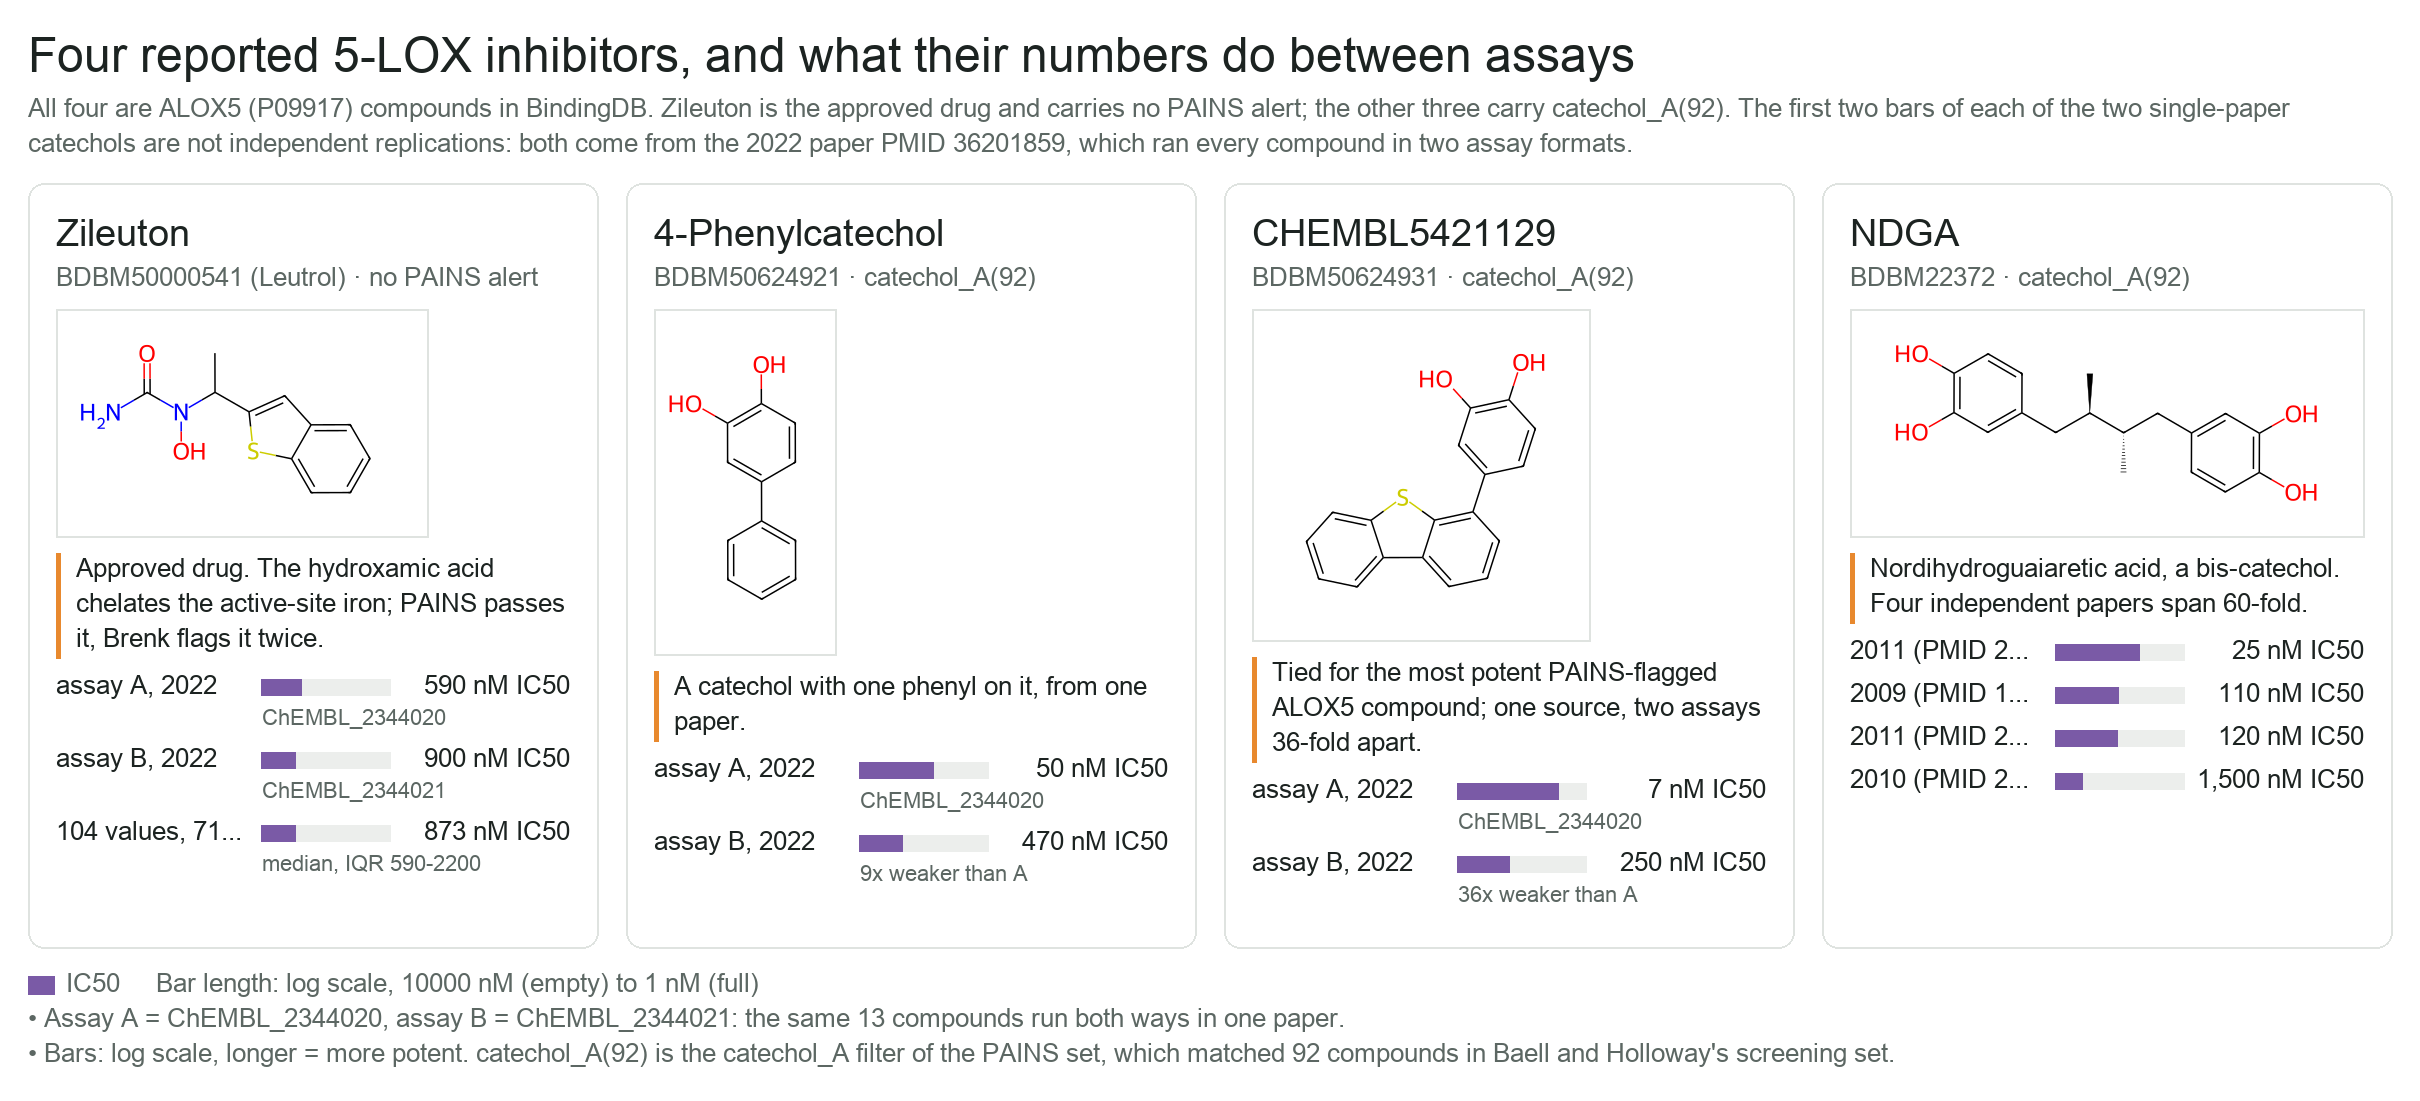

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'Four reported 5-LOX inhibitors, and what their numbers do between assays',
    'compounds': [
        {
            'smiles': 'CC(N(O)C(N)=O)c1cc2ccccc2s1',
            'title': 'Zileuton',
            'subtitle': 'BDBM50000541 (Leutrol) · no PAINS alert',
            'caption': 'Approved drug. The hydroxamic acid chelates the active-site iron; PAINS passes it, Brenk flags it twice.',
            'bars': [
                {'label': 'assay A, 2022', 'value_nm': 590.0, 'type': 'IC50', 'note': 'ChEMBL_2344020'},
                {'label': 'assay B, 2022', 'value_nm': 900.0, 'type': 'IC50', 'note': 'ChEMBL_2344021'},
                {
                    'label': '104 values, 71 sources',
                    'value_nm': 873.0,
                    'type': 'IC50',
                    'note': 'median, IQR 590-2200',
                },
            ],
        },
        {
            'smiles': 'Oc1ccc(cc1O)-c1ccccc1',
            'title': '4-Phenylcatechol',
            'subtitle': 'BDBM50624921 · catechol_A(92)',
            'caption': 'A catechol with one phenyl on it, from one paper.',
            'bars': [
                {'label': 'assay A, 2022', 'value_nm': 50.0, 'type': 'IC50', 'note': 'ChEMBL_2344020'},
                {'label': 'assay B, 2022', 'value_nm': 470.0, 'type': 'IC50', 'note': '9x weaker than A'},
            ],
        },
        {
            'smiles': 'Oc1ccc(cc1O)-c1cccc2c1sc1ccccc21',
            'title': 'CHEMBL5421129',
            'subtitle': 'BDBM50624931 · catechol_A(92)',
            'caption': 'Tied for the most potent PAINS-flagged ALOX5 compound; one source, two assays 36-fold apart.',
            'bars': [
                {'label': 'assay A, 2022', 'value_nm': 7.0, 'type': 'IC50', 'note': 'ChEMBL_2344020'},
                {'label': 'assay B, 2022', 'value_nm': 250.0, 'type': 'IC50', 'note': '36x weaker than A'},
            ],
        },
        {
            'smiles': 'C[C@@H](Cc1ccc(O)c(O)c1)[C@H](C)Cc1ccc(O)c(O)c1',
            'title': 'NDGA',
            'subtitle': 'BDBM22372 · catechol_A(92)',
            'caption': 'Nordihydroguaiaretic acid, a bis-catechol. Four independent papers span 60-fold.',
            'bars': [
                {'label': '2011 (PMID 21958737)', 'value_nm': 25.0, 'type': 'IC50'},
                {'label': '2009 (PMID 19848434)', 'value_nm': 110.0, 'type': 'IC50'},
                {'label': '2011 (PMID 21958738)', 'value_nm': 120.0, 'type': 'IC50'},
                {'label': '2010 (PMID 20667741)', 'value_nm': 1500.0, 'type': 'IC50'},
            ],
        },
    ],
    'columns': 4,
    'description': 'All four are ALOX5 (P09917) compounds in BindingDB. Zileuton is the approved drug and carries no PAINS alert; the other three carry catechol_A(92). The first two bars of each of the two single-paper catechols are not independent replications: both come from the 2022 paper PMID 36201859, which ran every compound in two assay formats.',
    'notes': [
        'Assay A = ChEMBL_2344020, assay B = ChEMBL_2344021: the same 13 compounds run both ways in one paper.',
        "Bars: log scale, longer = more potent. catechol_A(92) is the catechol_A filter of the PAINS set, which matched 92 compounds in Baell and Holloway's screening set.",
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

The very top of the list is clean, the flagged compounds start just below it, and the decisive evidence turned out to be **inside a single paper**.

## The top is clean, but not all the way down

`find_ligands_for_target(target_id=2259, max_value_nm=30)` and the same call with `properties={"exclude_alerts": ["pains"]}` return the same compounds until 7 nM. Nothing more potent than that is flagged, so down there the filter does no work. Further down it does: 163 ALOX5 compounds have a best value of 30 nM or lower, and 16 of them carry a PAINS alert.

What is at the very top: a 2006 series of chromen-2-ones (PMID 16464579) starting at 0.5 nM, MK-591 (1.6 nM) and L-746530 (2.3 nM), a 2021 series (PMID 34479036) at 0.75-0.8 nM. Designed, optimised, unflagged. Whatever is wrong with the 5-LOX literature is not at the very top of the potency ranking; it starts at about 7 nM.

## The flagged potent compounds are almost one paper

| compound | PAINS | best IC50 | sources | year |
|---|---|---|---|---|
| CHEMBL5398068 | catechol_A | 7 nM | 1 | 2022 |
| CHEMBL5421129 | catechol_A | 7 nM | 1 | 2022 |
| CHEMBL5395696 | catechol_A | 8 nM | 1 | 2022 |
| CHEMBL5413117 | catechol_A | 10 nM | 1 | 2022 |
| CHEMBL5401317 | catechol_A | 10 nM | 1 | 2022 |
| 4-({(3-fluoro-benzyl)-…}-methyl)-benzoic acid | anil_di_alk_C | 20 nM | 1 | 1992 |
| CHEMBL5280920 | ene_five_het_G | 20 nM | 1 | 2021 |
| CHEMBL5418840 | catechol_A | 20 nM | 1 | 2022 |
| CHEMBL5413658 | catechol_A | 20 nM | 1 | 2022 |
| NDGA | catechol_A | 25 nM | 4 | 2009-2011 |
| CHEMBL4085835 | catechol_A | 28 nM | 1 | 2017 |

Seven of the eleven most potent flagged compounds come from **one 2022 paper**, PMID 36201859 (doi 10.1016/j.ejmech.2022.114788), and all seven are catechols.

## That paper disagrees with itself

It ran the same 13 compounds in two assay formats, recorded separately as ChEMBL_2344020 (A) and ChEMBL_2344021 (B). Every compound has both numbers:

| compound | assay A | assay B | B / A |
|---|---|---|---|
| CHEMBL5398068 | 7 nM | 320 nM | 46× |
| CHEMBL5421129 | 7 nM | 250 nM | 36× |
| CHEMBL5395696 | 8 nM | 230 nM | 29× |
| CHEMBL5413117 | 10 nM | 270 nM | 27× |
| CHEMBL5401317 | 10 nM | 2,340 nM | 234× |
| CHEMBL5418840 | 20 nM | 260 nM | 13× |
| CHEMBL5413658 | 20 nM | 210 nM | 10.5× |
| CHEMBL5425532 | 30 nM | 1,110 nM | 37× |
| CHEMBL5441068 | 40 nM | 240 nM | 6× |
| 4-Phenylcatechol | 50 nM | 470 nM | 9.4× |
| CHEMBL5427414 | 76 nM | 210 nM | 2.8× |
| CHEMBL5403030 | 210 nM | 1,330 nM | 6.3× |
| **Zileuton** (reference) | 590 nM | 900 nM | 1.5× |

The twelve catechols shift by a median of **20×** between the two formats (from 2.8× to 234×). Zileuton, the approved drug included in the same table as the reference compound, shifts by **1.5×, the smallest ratio of all thirteen rows**.

That is the whole argument, and it needs no outside information. In assay A the catechols beat the approved drug (590 nM) by up to 84×. In assay B (zileuton 900 nM) the picture is much more modest. Of the five most potent catechols in assay A, four are only 2.8 to 3.9× more potent than zileuton, and the fifth, CHEMBL5401317, is 2.6× weaker (2,340 nM). Across all twelve, eight are 2.8 to 4.3× more potent than zileuton in assay B, 4-phenylcatechol is 1.9× more potent, and three (CHEMBL5401317, CHEMBL5425532 and CHEMBL5403030) are weaker than zileuton. A compound binding the active site would not be expected to change this much between two formats; a compound whose effect depends on the reducing environment of the assay might.

And look at **4-phenylcatechol**: MW 186, a catechol with one phenyl on it, reported at 50 nM in assay A, 12× more potent than zileuton there. There is no designed interaction in that structure to explain 50 nM against anything, and in assay B it is 470 nM.

## NDGA, the textbook case

Nordihydroguaiaretic acid is the natural-product 5-LOX inhibitor of the older literature, and it is a bis-catechol. BindingDB has exact IC50 values for it from four independent papers:

| IC50 | year | source |
|---|---|---|
| 25 nM | 2011 | PMID 21958737 |
| 110 nM | 2009 | PMID 19848434 |
| 120 nM | 2011 | PMID 21958738 |
| 1,500 nM | 2010 | PMID 20667741 |

Sixty-fold across four papers, and a 1991 EC50 recorded only as "> 330 µM" (PMID 1848292), an inequality, not a value, more than four orders of magnitude above the lowest IC50. NDGA is reproducible in the weak sense that several groups all get *a* number; it is not reproducible in the sense that matters, which is getting *the same* number.

The figure below puts four side by side: the approved drug, the fragment-sized catechol, the most potent flagged compounds (CHEMBL5421129, tied at 7 nM with CHEMBL5398068) and NDGA. The structures are drawn unaligned: their largest common substructure has only 6 atoms, too small to count as a shared core. The first two bars of each of the two single-paper catechols are not independent replications: they come from the same 2022 paper, which ran every compound in two assay formats. Zileuton is the only one of the four whose number is reproduced by independent groups (71 sources) rather than by one group twice.

## Exchange 3

**👤 User**

So what do I actually use as the rule?

In [ ]:
# Call 21 · run_sql · ran 2026-11-24 04:56:17 UTC
sql = """
    SELECT COUNT(*) AS n_values, COUNT(DISTINCT source_id) AS n_sources, MIN(year) AS y0, MAX(year) AS y1,
     MIN(value) AS min_nm, MAX(value) AS max_nm, MEDIAN(value) AS median_nm, quantile_cont(value,0.25) AS q1, quantile_cont(value,0.75) AS q3,
     SUM(CASE WHEN value BETWEEN 100 AND 1000 THEN 1 ELSE 0 END) AS n_100_1000
    FROM activity WHERE monomerid=50000541 AND polymerid=2259 AND affinity_type='IC50' AND relation='=' AND value IS NOT NULL
    
"""
await replay.call(21, 'run_sql', {'sql': sql},
                  sha256='3e9c320e3a72990ef007515d01856fdaa3e49c30d779c0dce16395ea02859286')

**Call 21** · `run_sql` · recorded result · sha256 `3e9c320e3a72…`

_1 row_

| n_values | n_sources | y0 | y1 | min_nm | max_nm | median_nm | q1 | q3 | n_100_1000 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 104 | 71 | 1992 | 2023 | 100 | 100000 | 873 | 590 | 2200 | 59 |


In [ ]:
# Call 22 · run_sql · ran 2026-11-24 04:56:17 UTC
sql = """
    WITH best AS (
      SELECT monomerid, MIN(value) AS best_nm, COUNT(DISTINCT source_id) AS n_sources
      FROM activity WHERE polymerid = 2259 AND relation = '=' AND value IS NOT NULL AND affinity_type IN ('IC50','Ki','Kd','EC50')
      GROUP BY monomerid)
    SELECT COUNT(*) AS n_cpd, SUM(CASE WHEN len(p.pains)>0 THEN 1 ELSE 0 END) AS n_flagged,
     SUM(CASE WHEN len(p.pains)>0 AND b.n_sources=1 THEN 1 ELSE 0 END) AS flagged_single,
     SUM(CASE WHEN len(p.pains)>0 AND b.n_sources=1 AND b.best_nm < 874 THEN 1 ELSE 0 END) AS rule_874
    FROM best b JOIN compound_property p USING (monomerid)
    
"""
await replay.call(22, 'run_sql', {'sql': sql},
                  sha256='275cebfd1aa794cfe8302eebff3e814bc89c0e8987e245241beceaea0e387362')

**Call 22** · `run_sql` · recorded result · sha256 `275cebfd1aa7…`

_1 row_

| n_cpd | n_flagged | flagged_single | rule_874 |
| --- | --- | --- | --- |
| 2411 | 416 | 395 | 226 |


In [ ]:
# Call 23 · run_sql · ran 2026-11-24 04:56:17 UTC
sql = """
    SELECT array_to_string(brenk,';') AS brenk, array_to_string(pains,';') AS pains, array_to_string(nih,';') AS nih FROM compound_property WHERE monomerid=50000541
    
"""
await replay.call(23, 'run_sql', {'sql': sql},
                  sha256='6e7bd455f2977ad6815e5fd05a6d966985adad5cb376b2f16d81ec130eda917c')

**Call 23** · `run_sql` · recorded result · sha256 `6e7bd455f297…`

_1 row_

| brenk | pains | nih |
| --- | --- | --- |
| Oxygen-nitrogen\_single\_bond;hydroxamic\_acid |  |  |


In [ ]:
# Call 24 · run_sql · ran 2026-11-24 04:56:17 UTC
sql = """
    SELECT COUNT(*) AS n_cpd, SUM(CASE WHEN len(brenk)>0 THEN 1 ELSE 0 END) AS n_brenk, ROUND(100.0*SUM(CASE WHEN len(brenk)>0 THEN 1 ELSE 0 END)/COUNT(*),1) AS pct FROM compound_property
    
"""
await replay.call(24, 'run_sql', {'sql': sql},
                  sha256='6185a210007a4a51fe7c4be139fef9edde13c5ac381bba6493d1a95c6f744d74')

**Call 24** · `run_sql` · recorded result · sha256 `6185a210007a…`

_1 row_

| n_cpd | n_brenk | pct |
| --- | --- | --- |
| 1466457 | 492632 | 33.6 |


In [ ]:
# Call 25 · find_ligands_for_target · ran 2026-11-24 04:56:17 UTC
await replay.call(25, 'find_ligands_for_target', {'target_id': 2259, 'max_value_nm': 600, 'limit': 500},
                  sha256='35bcc36c315b355ee60dc1fcc68855c884f4e745efd2990c75583e468b7988ca')

**Call 25** · `find_ligands_for_target` · recorded result · sha256 `35bcc36c315b…`

_500 rows, truncated at the limit_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 51002612 | IC50 | = | 0.5 | nM | 9.3 | 50182303 | 6-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.35 | 2.1 |  | 3 |
| 51002619 | IC50 | = | 0.5 | nM | 9.3 | 50182306 | 7-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-4-phenyl-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.36 | 2.24 |  | 3 |
| 51517804 | IC50 | = | 0.75 | nM | 9.12 | 50610906 | CHEMBL5267320 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282337 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.38 | 3.61 |  | 1 |
| 51517803 | IC50 | = | 0.77 | nM | 9.11 | 50610905 | CHEMBL5267685 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282337 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.46 | 4.15 |  | 1 |
| 51002614 | IC50 | = | 0.8 | nM | 9.1 | 50182308 | 7-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.37 | 2.44 |  | 3 |
| 51517805 | IC50 | = | 0.8 | nM | 9.1 | 50610907 | CHEMBL5270325 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282337 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.57 | 6.87 |  | 1 |
| 51002620 | IC50 | = | 0.9 | nM | 9.05 | 50182304 | 7-((3-fluoro-5-(3-hydroxypentan-3-yl)phenoxy)methyl)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.4 | 3.27 |  | 3 |
| 51090514 | IC50 | = | 1.6 | nM | 8.8 | 50029559 | MK-591 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290927 (CHEMBL3118900) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.29 | -0.21 |  | 1 |
| 51002621 | IC50 | = | 1.9 | nM | 8.72 | 50182302 | 7-((3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenoxy)methyl)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.32 | 2.09 |  | 3 |
| 51002616 | IC50 | = | 2.3 | nM | 8.64 | 50182300 | L-746530 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.34 | 3.83 |  | 3 |
| 51002613 | IC50 | = | 2.7 | nM | 8.57 | 50182305 | 7-((3-fluoro-5-(1-hydroxy-1-(thiazol-2-yl)propyl)phenoxy)methyl)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.33 | 2.15 |  | 3 |
| 50073146 | IC50 | = | 3 | nM | 8.52 | 50045643 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(quinolin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.29 | 0.36 |  | 1 |
| 50073191 | IC50 | = | 3 | nM | 8.52 | 50045673 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-\[2-(5-phenyl-pyridin-2-yl)-ethyl\]-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.03 |  | 1 |
| 50200285 | IC50 | = | 3 | nM | 8.52 | 50110484 | 3-((3-fluoro-5-(1-methoxycyclohexyl)phenoxy)methyl)-1-(4-(methylsulfonyl)phenyl)-5-phenyl-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3813 | 11859001 | 10.1016/s0960-894x(02)00013-6 | 2002 | 0.31 | 3.21 |  | 4 |
| 50832809 | EC50 | = | 3 | nM | 8.52 | 50172379 | (8E,10E)-(5S,9R)-20,20,20-Trifluoro-5,12-dihydroxy-icosa-6,8,10,14-tetraenoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_321097 (CHEMBL882067) | 16134928 | 10.1021/jm050524f | 2005 | 0.43 | 3.82 |  | 2 |
| 51002622 | IC50 | = | 3 | nM | 8.52 | 50182307 | 7-((3-fluoro-5-((1S,3S,5R)-3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]octan-3-yl)phenoxy)methyl)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.34 | 4.03 |  | 3 |
| 51002615 | IC50 | = | 3.7 | nM | 8.43 | 50182299 | 7-((3-fluoro-5-(1-hydroxy-1-(pyridin-2-yl)propyl)phenoxy)methyl)-4-(furan-3-yl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.33 | 2.62 |  | 3 |
| 51002623 | IC50 | = | 3.7 | nM | 8.43 | 50182298 | 7-((3-fluoro-5-((1S,3S,5R)-3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]octan-3-yl)phenoxy)methyl)-4-phenyl-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.33 | 3.53 |  | 3 |
| 50082254 | IC50 | = | 4 | nM | 8.4 | 50004424 | CHEMBL3238463 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.46 | 4.49 |  | 1 |
| 51002611 | IC50 | = | 4.3 | nM | 8.37 | 50182301 | 4-(4-chlorophenyl)-7-(3-fluoro-5-(1,1,1,3,3,3-hexafluoro-2-hydroxypropan-2-yl)phenylthio)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.32 | 0.65 |  | 3 |
| 50082255 | IC50 | = | 6 | nM | 8.22 | 50004425 | CHEMBL3238207 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.51 | 5.19 |  | 2 |
| 50024406 | IC50 | = | 7 | nM | 8.15 | 50016991 | 7-Fluoro-2-(4-methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.47 | 3.01 |  | 1 |
| 50799688 | IC50 | = | 7 | nM | 8.15 | 50085160 | L-674636 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 0.8 |  | 1 |
| 51553352 | IC50 | = | 7 | nM | 8.15 | 50624927 | CHEMBL5398068 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.62 | 4.23 | catechol\_A(92) | 2 |
| 51553356 | IC50 | = | 7 | nM | 8.15 | 50624931 | CHEMBL5421129 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.53 | 3.02 | catechol\_A(92) | 2 |
| 50610952 | IC50 | = | 7.9 | nM | 8.1 | 50331806 | methyl 3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxylate | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.95 |  | 2 |
| 50073123 | IC50 | = | 8 | nM | 8.1 | 50041161 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(2H-tetrazol-5-yl)-propyl\]-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.25 |  | 3 |
| 50799750 | IC50 | = | 8 | nM | 8.1 | 50052018 | MK-591 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.27 | 0.42 |  | 1 |
| 50997309 | IC50 | = | 8 | nM | 8.1 | 50409117 | CHEMBL2093045 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.35 | 2.19 |  | 1 |
| 51090513 | IC50 | = | 8 | nM | 8.1 | 50446686 | CHEMBL3113612 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290926 (CHEMBL3118899) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.38 | 6.44 |  | 3 |
| 51553354 | IC50 | = | 8 | nM | 8.1 | 50624929 | CHEMBL5395696 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.5 | 3.27 | catechol\_A(92) | 2 |
| 51090503 | Ki | = | 8.4 | nM | 8.08 | 50446681 | CHEMBL3113617 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290921 (CHEMBL3118894) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.4 | 6.51 |  | 2 |
| 50799732 | IC50 | = | 9 | nM | 8.05 | 50085202 | 2-{4-(4-Fluoro-phenyl)-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-butoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.56 |  | 1 |
| 51090502 | Ki | = | 9.9 | nM | 8 | 50446680 | CHEMBL3113618 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290921 (CHEMBL3118894) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.29 | 4.34 |  | 2 |
| 50047277 | IC50 | = | 10 | nM | 8 | 50031153 | \[1-{4-\[4-((S)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-eth-(E)-ylideneaminooxy\]-acetonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.41 | 2.84 |  | 1 |
| 50064442 | IC50 | = | 10 | nM | 8 | 50000845 | 4-Methoxy-4-\[3-(naphthalen-2-ylmethoxy)-phenyl\]-tetrahydro-pyran | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.42 | 2.93 |  | 2 |
| 50082256 | IC50 | = | 10 | nM | 8 | 50004426 | CHEMBL3238465 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.5 | 4.94 |  | 1 |
| 50258023 | IC50 | = | 10 | nM | 8 | 50038460 | CHEMBL3353726 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432944 (CHEMBL3383919) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.52 | 3.16 |  | 2 |
| 50799763 | IC50 | = | 10 | nM | 8 | 50085229 | {3-Methyl-3-phenyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-butoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.69 |  | 1 |
| 50799770 | IC50 | = | 10 | nM | 8 | 50085231 | {2-Butyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-hexyloxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.06 |  | 1 |
| 51553353 | IC50 | = | 10 | nM | 8 | 50624928 | CHEMBL5413117 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.52 | 3.68 | catechol\_A(92) | 2 |
| 51553355 | IC50 | = | 10 | nM | 8 | 50624930 | CHEMBL5401317 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.5 | 2.93 | catechol\_A(92) | 1 |
| 50024413 | IC50 | = | 11 | nM | 7.96 | 50016986 | 7-Chloro-2-(4-methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.31 |  | 2 |
| 50073122 | IC50 | = | 11 | nM | 7.96 | 50045654 | N-{4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-3,3-dimethyl-butyryl}-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -0.1 |  | 1 |
| 50073177 | IC50 | = | 11 | nM | 7.96 | 50045679 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-(5-phenyl-pyridin-2-ylmethylsulfanyl)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.1 |  | 1 |
| 50610958 | IC50 | = | 11 | nM | 7.96 | 50331797 | 1-(3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophen-2-yl)ethanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.39 |  | 2 |
| 51002617 | IC50 | = | 11.6 | nM | 7.94 | 50182310 | 7-((3-fluoro-5-((1S,3S,5R)-3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]octan-3-yl)phenoxy)methyl)-4-(4-fluorophenyl)-2H-chromen-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.3 | 2.9 |  | 1 |
| 50024404 | IC50 | = | 12 | nM | 7.92 | 50016990 | 2-(4-Methoxy-benzyl)-3,7-dimethyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.61 |  | 1 |
| 50073180 | IC50 | = | 12 | nM | 7.92 | 50045663 | 4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-3,3-dimethyl-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.14 |  | 1 |
| 50073183 | IC50 | = | 12 | nM | 7.92 | 50045640 | 3-\[1-(4-Chloro-benzyl)-6-(5-methoxy-pyridin-2-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.29 | 0.9 |  | 1 |
| 50024427 | IC50 | = | 13 | nM | 7.89 | 50017001 | 7-Chloro-2-(2,4-dimethoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.42 | 2.23 |  | 1 |
| 50038732 | IC50 | = | 13 | nM | 7.89 | 50029577 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.25 | -0.55 |  | 3 |
| 50107404 | IC50 | = | 13 | nM | 7.89 | 50163748 | (E)-3,5-Bis\[beta-(4-Hydroxy-3-methoxyphenyl)-ethenyl\]-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.4 | 3.71 |  | 4 |
| 50107405 | IC50 | = | 13 | nM | 7.89 | 50020584 | CHEMBL2413471 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.43 | 4.21 |  | 4 |
| 50107406 | IC50 | = | 13 | nM | 7.89 | 50020589 | CHEMBL3290441 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.29 | 0.69 |  | 4 |
| 50107407 | IC50 | = | 13 | nM | 7.89 | 22334 | BW4C | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.51 | 4.16 |  | 31 |
| 50799698 | IC50 | = | 13 | nM | 7.89 | 50085170 | 2-{Cycloheptyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.59 |  | 1 |
| 51517797 | IC50 | = | 13 | nM | 7.89 | 50610902 | CHEMBL5290007 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.47 | 3.52 |  | 1 |
| 50064441 | IC50 | = | 14 | nM | 7.85 | 50040423 | 7-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.3 | 1.44 |  | 2 |
| 50799764 | IC50 | = | 14 | nM | 7.85 | 50085227 | 2-{\[2-Chloro-4-(quinolin-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.28 |  | 1 |
| 50799766 | IC50 | = | 14 | nM | 7.85 | 50085226 | {\[2-Chloro-4-(5-fluoro-benzothiazol-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 1.47 |  | 1 |
| 50799769 | IC50 | = | 14 | nM | 7.85 | 50085230 | 2-{2-Butyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-hexyloxyimino}-propionic acid (2H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 0.52 |  | 1 |
| 51090512 | IC50 | = | 14 | nM | 7.85 | 50446685 | CHEMBL3113613 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290926 (CHEMBL3118899) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.28 | 4.1 |  | 3 |
| 51517798 | IC50 | = | 14 | nM | 7.85 | 50610903 | CHEMBL5284118 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.47 | 3.48 |  | 1 |
| 50781867 | IC50 | = | 15 | nM | 7.82 | 50059717 | 4-(furan-3-yl)-7-((6-(4-hydroxytetrahydro-2H-pyran-4-yl)pyridin-2-yl)methoxy)-2-naphthonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3794 (CHEMBL619869) | 9288168 | 10.1021/jm970046b | 1997 | 0.33 | 2.88 |  | 2 |
| 50799731 | IC50 | = | 15 | nM | 7.82 | 50085159 | 2-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.91 |  | 4 |
| 50073140 | IC50 | = | 16 | nM | 7.8 | 50045657 | 2,2-Dimethyl-3-\[4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-1-(5-phenyl-pyridin-2-ylmethyl)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -1.28 |  | 1 |
| 50799691 | IC50 | = | 16 | nM | 7.8 | 50085163 | 2-{Cyclopentyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 2.28 |  | 1 |
| 50799711 | IC50 | = | 17 | nM | 7.77 | 50085181 | {Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 2.25 |  | 1 |
| 50799725 | IC50 | = | 17 | nM | 7.77 | 50085182 | (E)-4-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-pentanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.08 |  | 1 |
| 50799760 | IC50 | = | 17 | nM | 7.77 | 50085232 | 7-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-octanoic acid (0.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | -0.09 |  | 1 |
| 51517799 | IC50 | = | 17 | nM | 7.77 | 50610904 | CHEMBL5267222 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.44 | 4.43 |  | 1 |
| 50799728 | IC50 | = | 18 | nM | 7.74 | 50085196 | {Cycloheptyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.83 |  | 1 |
| 50073119 | IC50 | = | 19 | nM | 7.72 | 50045647 | 5-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-4,4-dimethyl-pentanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.73 |  | 1 |
| 50610955 | IC50 | = | 19 | nM | 7.72 | 50331794 | 1,1,1-trifluoro-2-(1-((2-(hydroxymethyl)-3-phenylbenzo\[b\]thiophen-6-yl)methyl)-1H-1,2,3-triazol-4-yl)butan-2-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.86 |  | 2 |
| 50024401 | IC50 | = | 20 | nM | 7.7 | 50016987 | 7-Chloro-2-(4-methoxy-benzyl)-3,5-dipropyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.41 | 1.4 |  | 1 |
| 50024424 | IC50 | = | 20 | nM | 7.7 | 50017000 | 5-Allyl-7-chloro-2-(4-methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.44 | 2.27 |  | 1 |
| 50047252 | IC50 | = | 20 | nM | 7.7 | 50031128 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.35 | 3.48 |  | 1 |
| 50047260 | IC50 | = | 20 | nM | 7.7 | 50031136 | 1-{4-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 1.94 |  | 1 |
| 50047273 | IC50 | = | 20 | nM | 7.7 | 50031149 | 6-\[4-(4-Methoxy-tetrahydro-pyran-4-yl)-5-methyl-thiophen-2-ylsulfanyl\]-1-methyl-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 2.93 |  | 1 |
| 50064436 | IC50 | = | 20 | nM | 7.7 | 50040419 | 7-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.29 | 1.29 |  | 1 |
| 50065539 | IC50 | = | 20 | nM | 7.7 | 50041156 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.25 | -0.35 |  | 1 |
| 50065553 | IC50 | = | 20 | nM | 7.7 | 50041160 | N-(2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-butyryl)-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | 0.27 |  | 1 |
| 50073172 | IC50 | = | 20 | nM | 7.7 | 50045664 | 3-\[1-(4-Chloro-benzyl)-6-(isoquinolin-3-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.46 |  | 1 |
| 50121388 | IC50 | = | 20 | nM | 7.7 | 50059715 | 4-Furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.31 | 3.03 |  | 3 |
| 50462622 | IC50 | = | 20 | nM | 7.7 | 50012827 | PHENOXAZINE | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4044 |  | 10.1016/S0960-894X(00)80241-3 | 1991 | 0.75 | 4.16 |  | 1 |
| 50760052 | IC50 | = | 20 | nM | 7.7 | 50006807 | 4-({(3-Fluoro-benzyl)-\[4-(quinolin-2-ylmethoxy)-phenyl\]-amino}-methyl)-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3834 (CHEMBL875087) | 1635053 | 10.1021/jm00092a001 | 1992 | 0.29 | 0.84 | anil\_di\_alk\_C(246) | 1 |
| 50760188 | IC50 | = | 20 | nM | 7.7 | 50000829 | ZD-2138 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.36 | 3.79 |  | 5 |
| 50760669 | EC50 | = | 20 | nM | 7.7 | 50001176 | 2-(5-Chloro-benzothiazol-2-ylsulfanyl)-ethylamine-N-hydroxy-N-methyl carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.56 | 4.63 |  | 1 |
| 50760681 | EC50 | = | 20 | nM | 7.7 | 50001187 | 3-(5-Chloro-benzothiazol-2-ylsulfanyl)-N-hydroxy-N-methyl-propionamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.59 | 4.42 |  | 1 |
| 50799689 | IC50 | = | 20 | nM | 7.7 | 50085161 | {Cyclohexyl-\[3-methyl-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid (0.4H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.87 |  | 1 |
| 50799702 | IC50 | = | 20 | nM | 7.7 | 50085173 | 2-{Adamantan-2-yl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 1.3 |  | 1 |
| 50799710 | IC50 | = | 20 | nM | 7.7 | 50085179 | {Cyclohexyl-\[2-methoxy-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 2.17 |  | 1 |
| 50799724 | IC50 | = | 20 | nM | 7.7 | 50085194 | 2-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-4-phenyl-butyric acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.27 | 0.17 |  | 1 |
| 50799726 | IC50 | = | 20 | nM | 7.7 | 50085192 | 2-{Cyclohexyl-\[4-(6-fluoro-quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.65 |  | 1 |
| 50799727 | IC50 | = | 20 | nM | 7.7 | 50085195 | 2-{Cyclohexyl-\[4-(4-phenyl-thiazol-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.21 |  | 1 |
| 50799741 | IC50 | = | 20 | nM | 7.7 | 50085203 | 2-{Cyclohexyl-\[3-methyl-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid (0.1H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.48 |  | 1 |
| 50799745 | IC50 | = | 20 | nM | 7.7 | 50085217 | 2-{2-Cyclohexyl-2-\[4-(quinolin-2-ylmethoxy)-phenyl\]-ethoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.75 |  | 1 |
| 50997308 | IC50 | = | 20 | nM | 7.7 | 50409116 | CHEMBL2110176 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.01 |  | 1 |
| 51517773 | IC50 | = | 20 | nM | 7.7 | 50610884 | CHEMBL5280920 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282321 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.3 | 0.72 | ene\_five\_het\_G(10) | 1 |
| 51553347 | IC50 | = | 20 | nM | 7.7 | 50624922 | CHEMBL5418840 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.7 | 4.28 | catechol\_A(92) | 2 |
| 51553348 | IC50 | = | 20 | nM | 7.7 | 50624923 | CHEMBL5413658 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.7 | 4.28 | catechol\_A(92) | 2 |
| 50610979 | IC50 | = | 21 | nM | 7.68 | 50331803 | (S)-3-(4-fluorophenyl)-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686761 (CHEMBL1291000) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.32 | 3.07 |  | 2 |
| 50799699 | IC50 | = | 21 | nM | 7.68 | 50085168 | {Adamantan-2-yl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.3 | 1.67 |  | 1 |
| 50799749 | IC50 | = | 21 | nM | 7.68 | 50085213 | {Cyclohexyl-\[4-(4-phenyl-thiazol-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid (1.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.58 |  | 1 |
| 50799761 | IC50 | = | 21 | nM | 7.68 | 50085220 | (Z)-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-thiophen-2-yl-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 0.68 |  | 1 |
| 50065556 | IC50 | = | 22 | nM | 7.66 | 50041173 | N-(2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-propionyl)-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | 0.62 |  | 1 |
| 50073142 | IC50 | = | 22 | nM | 7.66 | 50045667 | L-689065 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.01 |  | 1 |
| 50465089 | IC50 | = | 22 | nM | 7.66 | 50280965 | 4-Phenyl-7-(5-phenyl-pyridin-2-ylmethoxy)-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.31 | 0.84 |  | 1 |
| 50799709 | IC50 | = | 22 | nM | 7.66 | 50085178 | {\[4-(Benzothiazol-2-ylmethoxy)-2-bromo-phenyl\]-cyclohexyl-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 1.31 |  | 1 |
| 50799740 | IC50 | = | 22 | nM | 7.66 | 50085210 | 2-{3-Methyl-3-phenyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-butoxyimino}-propionic acid (0.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 0.96 |  | 1 |
| 50044417 | IC50 | = | 23 | nM | 7.64 | 50029561 | 2-(2-(2-(2-(3-fluorobenzyl)-7-methyl-5-((5-phenylpyridin-2-yl)methoxy)-6,7-dihydro-2H-thiopyrano\[2,3,4-cd\]indol-1-yl)ethoxy)phenyl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -1.12 |  | 1 |
| 50073104 | IC50 | = | 23 | nM | 7.64 | 50045637 | 2,2-Dimethyl-3-\[4-methyl-1-(3-phenyl-propyl)-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -0.97 |  | 1 |
| 50073149 | IC50 | = | 23 | nM | 7.64 | 50045638 | 4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.42 |  | 1 |
| 50777584 | IC50 | = | 23 | nM | 7.64 | 50053534 | 7-\[3-(4-Hydroxy-2-methoxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.28 | 1.91 |  | 1 |
| 50997311 | IC50 | = | 23 | nM | 7.64 | 50409118 | CHEMBL2110173 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 0.64 |  | 1 |
| 50061703 | IC50 | = | 24 | nM | 7.62 | 50042521 | N'-ethyl-N-hydroxy-N-\[(6-phenoxy-2H-chromen-3-yl)methyl\]urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_101350 (CHEMBL712608) | 8246226 | 10.1021/jm00075a013 | 1994 | 0.42 | 3.94 |  | 2 |
| 198909 | IC50 | = | 25 | nM | 7.6 | 91658 | N-aryl-4-aryl-1,3-thiazole-2-amine, 6 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.47 | 3.43 |  | 1 |
| 50022521 | IC50 | = | 25 | nM | 7.6 | 50015416 | 4,6,7-Trimethyl-2-propyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.65 | 3.67 |  | 1 |
| 50701863 | IC50 | = | 25 | nM | 7.6 | 22372 | NDGA | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_787580 (CHEMBL1917973) | 21958737 | 10.1016/j.bmc.2011.09.003 | 2011 | 0.47 | 4.03 | catechol\_A(92) | 3 |
| 50799720 | IC50 | = | 25 | nM | 7.6 | 50085188 | {Cyclohexyl-\[4-(quinoxalin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 2.68 |  | 1 |
| 50024425 | IC50 | = | 26 | nM | 7.59 | 50016998 | 7-Chloro-2-(4-chloro-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 1.29 |  | 1 |
| 50044421 | IC50 | = | 26 | nM | 7.59 | 50029564 | {2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethoxy\]-phenyl}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -1.64 |  | 1 |
| 50777586 | IC50 | = | 26 | nM | 7.59 | 50053537 | 4-Furan-3-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.31 | 2.24 |  | 1 |
| 50073159 | IC50 | = | 27 | nM | 7.57 | 50045653 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(6-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.1 |  | 1 |
| 50121391 | IC50 | = | 27 | nM | 7.57 | 50070314 | 7-\[3-Fluoro-5-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-phenoxymethyl\]-4-furan-3-yl-quinoline-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.3 | 2.76 |  | 1 |
| 50777611 | IC50 | = | 27 | nM | 7.57 | 50053564 | 7-\[3-(4-Hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-thiophen-3-yl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.31 | 1.75 |  | 1 |
| 50799701 | IC50 | = | 27 | nM | 7.57 | 50085172 | 2-{\[3-Chloro-4-(quinolin-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1 |  | 1 |
| 50799723 | IC50 | = | 27 | nM | 7.57 | 50085193 | {2-Cyclohexyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-ethoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.66 |  | 1 |
| 50799768 | IC50 | = | 27 | nM | 7.57 | 50085223 | {Cyclohexyl-\[4-(thiazolo\[5,4-b\]pyridin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.35 | 2.59 |  | 1 |
| 50073169 | IC50 | = | 28 | nM | 7.55 | 50045675 | 3-\[1-(4-Methoxy-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -0.48 |  | 1 |
| 50073175 | IC50 | = | 28 | nM | 7.55 | 50045666 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(thiophen-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.3 | -0.12 |  | 1 |
| 50073189 | IC50 | = | 28 | nM | 7.55 | 50045669 | 3-\[1-(3-Methoxy-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -0.48 |  | 1 |
| 50610962 | IC50 | = | 28 | nM | 7.55 | 50331801 | (S)-3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.32 | 3.08 |  | 2 |
| 50683170 | IC50 | = | 28 | nM | 7.55 | 50231998 | CHEMBL4085835 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1645815 (CHEMBL3994871) | 27836196 | 10.1016/j.ejmech.2016.10.046 | 2017 | 0.41 | 1.58 | catechol\_A(92) | 2 |
| 50799738 | IC50 | = | 28 | nM | 7.55 | 50085206 | {\[4-(Benzothiazol-2-ylmethoxy)-2-chloro-phenyl\]-cyclohexyl-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.31 |  | 1 |
| 50799746 | IC50 | = | 28 | nM | 7.55 | 50085216 | 2-{\[4-(Benzothiazol-2-ylmethoxy)-2-chloro-phenyl\]-cyclohexyl-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 0.92 |  | 1 |
| 50799733 | IC50 | = | 29 | nM | 7.54 | 50085197 | 2-{2-Cyclohexyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-ethoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.24 |  | 1 |
| 51549766 | IC50 | = | 29 | nM | 7.54 | 50078888 | CHEMBL3416359 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2337815 | 36731273 | 10.1016/j.ejmech.2023.115151 | 2023 | 0.43 | 2.66 | imine\_one\_A(321), quinone\_D(2) | 2 |
| 50023890 | IC50 | = | 30 | nM | 7.52 | 50016671 | 2-(4-Benzyloxy-phenyl)-N-hydroxy-N-(1-phenyl-ethyl)-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3824 | 2502629 | 10.1021/jm00128a027 | 1989 | 0.38 | 2.73 |  | 2 |
| 50024417 | IC50 | = | 30 | nM | 7.52 | 50016994 | 2-Benzyl-7-chloro-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.47 | 1.88 |  | 1 |
| 50044425 | IC50 | = | 30 | nM | 7.52 | 50029568 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethylsulfanyl}-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -2.53 |  | 1 |
| 50044433 | IC50 | = | 30 | nM | 7.52 | 50029573 | 2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -2.49 |  | 1 |
| 50047257 | IC50 | = | 30 | nM | 7.52 | 50031133 | N-{4-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-phenyl}-N-methyl-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.37 | 2.6 |  | 1 |
| 50047268 | IC50 | = | 30 | nM | 7.52 | 50031143 | \[1-{4-\[5-((R)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiazol-2-ylsulfanyl\]-phenyl}-eth-(E)-ylideneaminooxy\]-acetonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.38 | 2.96 | thiazol\_SC\_A(3) | 1 |
| 50082257 | IC50 | = | 30 | nM | 7.52 | 50004427 | CHEMBL3238471 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.38 | 3.1 |  | 1 |
| 50258084 | IC50 | = | 30 | nM | 7.52 | 50038459 | CHEMBL3353725 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432943 (CHEMBL3383918) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.47 | 2.75 |  | 2 |
| 50280162 | IC50 | = | 30 | nM | 7.52 | 50312869 | N-aryl-4-aryl-1,3-thiazole-2-amine, 5 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.52 | 2.61 |  | 2 |
| 50280172 | IC50 | = | 30 | nM | 7.52 | 50312882 | 4-(4-(3,4-dichlorophenyl)thiazol-2-ylamino)phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.49 | 1.95 |  | 1 |
| 50280225 | IC50 | = | 30 | nM | 7.52 | 50051932 | CHEMBL3318370 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.47 | 2.86 |  | 2 |
| 50280233 | IC50 | = | 30 | nM | 7.52 | 91660 | N-aryl-4-aryl-1,3-thiazole-2-amine, 9 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.52 | 2.61 |  | 2 |
| 50683138 | IC50 | = | 30 | nM | 7.52 | 50231991 | CHEMBL4093584 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1645815 (CHEMBL3994871) | 27836196 | 10.1016/j.ejmech.2016.10.046 | 2017 | 0.45 | 2.33 | catechol\_A(92) | 2 |
| 50721084 | IC50 | = | 30 | nM | 7.52 | 50365616 | CHEMBL1958141 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 0.89 |  | 2 |
| 50760207 | IC50 | = | 30 | nM | 7.52 | 50000847 | 6-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one (0.8 hydrate) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.37 | 3.75 |  | 1 |
| 50777596 | IC50 | = | 30 | nM | 7.52 | 50053554 | 4-Furan-3-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.32 | 1.97 |  | 2 |
| 50799714 | IC50 | = | 30 | nM | 7.52 | 50085183 | 2-{2-Phenyl-1-\[4-(quinolin-2-ylmethoxy)-phenyl\]-ethoxyimino}-propionic acid (0.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.95 |  | 1 |
| 50799756 | IC50 | = | 30 | nM | 7.52 | 50085214 | {Cyclopentyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 2.39 |  | 1 |
| 50799757 | IC50 | = | 30 | nM | 7.52 | 50085215 | 2-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-butyric acid (H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.22 |  | 1 |
| 51086308 | IC50 | = | 30 | nM | 7.52 | 50444531 | CHEMBL3099680 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1281541 (CHEMBL3102107) | 24900624 | 10.1021/ml4002562 | 2013 | 0.32 | 1.11 |  | 1 |
| 51526968 | IC50 | = | 30 | nM | 7.52 | 50614346 | CHEMBL5271431 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2296655 | 26994693 | 10.1016/j.ejmech.2016.01.055 | 2016 | 0.36 | 1.74 |  | 1 |
| 51553351 | IC50 | = | 30 | nM | 7.52 | 50624926 | CHEMBL5425532 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.61 | 4.01 | catechol\_A(92) | 1 |
| 51553374 | IC50 | = | 30 | nM | 7.52 | 50231999 | CHEMBL4103758 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344031 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.43 | 1.94 | catechol\_A(92) | 3 |
| 51562782 | IC50 | = | 30 | nM | 7.52 | 50628320 | CHEMBL5404346 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2354976 | 37591315 | 10.1016/j.bmcl.2023.129448 | 2023 | 0.43 | 2.19 |  | 1 |
| 56028 | IC50 | = | 31 | nM | 7.51 | 31134 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11m | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.37 | 1.87 |  | 2 |
| 50024400 | IC50 | = | 31 | nM | 7.51 | 50016985 | 2-(4-Methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.51 |  | 1 |
| 50610978 | IC50 | = | 31 | nM | 7.51 | 50331802 | (S)-3-(3-fluorophenyl)-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686761 (CHEMBL1291000) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.31 | 2.9 |  | 2 |
| 50799743 | IC50 | = | 31 | nM | 7.51 | 50085209 | {Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-phenyl-acetic acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.28 | 0.57 |  | 1 |
| 50799758 | IC50 | = | 31 | nM | 7.51 | 50085225 | 4-({Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-methyl)-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.28 | 0.33 |  | 1 |
| 51517796 | IC50 | = | 31 | nM | 7.51 | 50610901 | CHEMBL5283932 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282335 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.45 | 2.94 |  | 1 |
| 50073176 | IC50 | = | 33 | nM | 7.48 | 50045652 | 3-\[1-Cyclohexylmethyl-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.07 |  | 1 |
| 50073178 | IC50 | = | 33 | nM | 7.48 | 50045678 | 3-\[1-(4-Chloro-benzyl)-4-ethyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.58 |  | 1 |
| 50082258 | IC50 | = | 33 | nM | 7.48 | 50004428 | CHEMBL3238466 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.47 | 4.07 |  | 1 |
| 50799734 | IC50 | = | 33 | nM | 7.48 | 50085204 | 2-{Cyclohexyl-\[5-(quinolin-2-ylmethoxy)-benzo\[b\]thiophen-2-yl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 0.35 |  | 1 |
| 50799748 | IC50 | = | 33 | nM | 7.48 | 50085212 | 2-{\[4-(Quinolin-2-ylmethoxy)-phenyl\]-thiophen-2-yl-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 2.04 |  | 1 |
| 50067732 | IC50 | = | 34 | nM | 7.47 | 50042497 | N-hydroxy-N-\[(6-phenoxy-2H-chromen-3-yl)methyl\]-N'-propylurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_101349 | 8246226 | 10.1021/jm00075a013 | 1994 | 0.39 | 3.4 |  | 2 |
| 50082259 | IC50 | = | 34 | nM | 7.47 | 50004429 | CHEMBL3238468 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1336618 (CHEMBL3240356) | 24685113 | 10.1016/j.bmc.2014.03.008 | 2014 | 0.44 | 4.71 |  | 1 |
| 50997312 | IC50 | = | 34 | nM | 7.47 | 50409119 | CHEMBL2110174 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 2.89 |  | 1 |
| 50073114 | IC50 | = | 35 | nM | 7.46 | 50045646 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.28 | 0.45 |  | 1 |
| 50462618 | IC50 | = | 35 | nM | 7.46 | 50279849 | (E)-3-(10H-Phenoxazin-2-yl)-acrylic acid ethyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4044 |  | 10.1016/S0960-894X(00)80241-3 | 1991 | 0.49 | 3.35 |  | 1 |
| 50799759 | IC50 | = | 35 | nM | 7.46 | 50085224 | 2-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-3-phenyl-propionic acid (H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.27 | 0.32 |  | 1 |
| 50799762 | IC50 | = | 35 | nM | 7.46 | 50085228 | (Cyclohexyl-{4-\[4-(4-isopropyl-phenyl)-thiazol-2-ylmethoxy\]-phenyl}-methoxyimino)-acetic acid (2H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 0.24 |  | 1 |
| 50061734 | IC50 | = | 36 | nM | 7.44 | 50042500 | N-hydroxy-N'-methyl-N-\[(6-phenoxy-2H-chromen-3-yl)methyl\]urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_101351 (CHEMBL877238) | 8246226 | 10.1021/jm00075a013 | 1994 | 0.42 | 4.15 |  | 2 |
| 50121389 | IC50 | = | 36 | nM | 7.44 | 50070310 | 4-Furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-ylmethoxy\]-quinoline-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.3 | 3.38 |  | 1 |
| 50003367 | IC50 | = | 37 | nM | 7.43 | 50042493 | CGS-23885 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4047 (CHEMBL620778) |  | 10.1016/S0960-894X(01)80152-9 | 1994 | 0.44 | 4.41 |  | 5 |
| 50067752 | IC50 | = | 37 | nM | 7.43 | 50042512 | N'-allyl-N-hydroxy-N-\[(6-phenoxy-2H-chromen-3-yl)methyl\]urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_101349 (CHEMBL712607) | 8246226 | 10.1021/jm00075a013 | 1994 | 0.39 | 3.59 |  | 2 |
| 50073170 | IC50 | = | 37 | nM | 7.43 | 50045660 | \[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.22 |  | 1 |
| 50073179 | IC50 | = | 38 | nM | 7.42 | 50045677 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.62 |  | 1 |
| 50760673 | EC50 | = | 39 | nM | 7.41 | 50001181 | 3-(Benzothiazol-2-ylsulfanyl)-N-hydroxy-N-methyl-propionamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.6 | 4.78 |  | 1 |
| 50044440 | IC50 | = | 40 | nM | 7.4 | 50029576 | (2-{2-\[1-(3-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-phenyl)-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -1.87 |  | 1 |
| 50047249 | IC50 | = | 40 | nM | 7.4 | 50031125 | 4-Methyl-6-\[4-(2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-4H-benzo\[1,4\]oxazin-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 3.15 |  | 1 |
| 50047256 | IC50 | = | 40 | nM | 7.4 | 50031132 | N-Methyl-N-{4-\[4-((S)-2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.41 | 2.52 |  | 1 |
| 50047263 | IC50 | = | 40 | nM | 7.4 | 50031139 | 1-{4-\[4-((S)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.42 | 1.68 |  | 1 |
| 50047265 | IC50 | = | 40 | nM | 7.4 | 50031141 | 1-{4-\[4-(2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.42 | 1.68 |  | 1 |
| 50047269 | IC50 | = | 40 | nM | 7.4 | 50031145 | 7-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-4-methyl-4H-benzo\[1,4\]oxazin-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.35 | 3.11 |  | 1 |
| 50047274 | IC50 | = | 40 | nM | 7.4 | 50031152 | 6-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-4-methyl-benzenesulfonyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.34 | 4.07 |  | 1 |
| 50065555 | IC50 | = | 40 | nM | 7.4 | 50041171 | (R)-2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanylmethyl\]-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.23 | -1.96 |  | 1 |
| 50192424 | IC50 | = | 40 | nM | 7.4 | 50250921 | isaindigotone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_506252 (CHEMBL942442) | 11678654 | 10.1021/np0101898 | 2001 | 0.39 | 4.34 |  | 1 |
| 50324530 | IC50 | = | 40 | nM | 7.4 | 50078886 | CHEMBL3416361 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1472475 (CHEMBL3420628) | 25765759 | 10.1016/j.ejmech.2015.02.042 | 2015 | 0.39 | 1.74 | imine\_one\_A(321), quinone\_D(2) | 1 |
| 50610954 | IC50 | = | 40 | nM | 7.4 | 50331807 | 1,1,1-trifluoro-2-(1-((3-phenylbenzo\[b\]thiophen-6-yl)methyl)-1H-1,2,3-triazol-4-yl)butan-2-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.35 | 2.03 |  | 2 |
| 50721086 | IC50 | = | 40 | nM | 7.4 | 50365618 | CHEMBL1958143 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 0.77 |  | 2 |
| 50760223 | IC50 | = | 40 | nM | 7.4 | 50000862 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-3-methyl-3H-benzothiazol-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.36 | 3.43 |  | 1 |
| 50799690 | IC50 | = | 40 | nM | 7.4 | 50085162 | 2-{Cyclohexyl-\[6-(quinolin-2-ylmethoxy)-benzo\[b\]thiophen-2-yl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.29 | 0.27 |  | 1 |
| 50799697 | IC50 | = | 40 | nM | 7.4 | 50085169 | 4-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-pent-2-enoic acid (0.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.3 | 0.93 |  | 1 |
| 51427191 | IC50 | = | 40 | nM | 7.4 | 50576500 | CHEMBL4847874 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127370 (CHEMBL4836715) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.31 | 0.85 |  | 4 |
| 51526971 | IC50 | = | 40 | nM | 7.4 | 50614351 | CHEMBL5268642 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2296655 | 26994693 | 10.1016/j.ejmech.2016.01.055 | 2016 | 0.35 | 1.57 |  | 1 |
| 51553350 | IC50 | = | 40 | nM | 7.4 | 50624925 | CHEMBL5441068 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.56 | 4.86 | catechol\_A(92) | 2 |
| 50061698 | IC50 | = | 42 | nM | 7.38 | 50042509 | N-{\[6-(4-fluorophenoxy)-2H-chromen-3-yl\]methyl}-N-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_101349 | 8246226 | 10.1021/jm00075a013 | 1994 | 0.42 | 4.22 |  | 2 |
| 50073154 | IC50 | = | 42 | nM | 7.38 | 50045672 | 3-\[6-(5-Butyl-pyridin-2-ylmethoxy)-1-(4-chloro-benzyl)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.97 |  | 1 |
| 50465093 | IC50 | = | 42 | nM | 7.38 | 50280968 | 4-(3-Methoxy-phenyl)-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.46 | 3.19 |  | 1 |
| 51519359 | IC50 | = | 42 | nM | 7.38 | 50611742 | CHEMBL5275767 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2284016 | 28784429 | 10.1016/j.ejmech.2017.07.019 | 2018 | 0.35 | 1.43 |  | 1 |
| 50799719 | IC50 | = | 43 | nM | 7.37 | 50085190 | 2-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-3-(4-hydroxy-phenyl)-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.26 | 0.53 |  | 1 |
| 56026 | IC50 | = | 45 | nM | 7.35 | 31132 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11k | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.39 | 1.83 |  | 2 |
| 50018498 | IC50 | = | 45 | nM | 7.35 | 50012772 | 2,6-Dimethyl-4-(2-thiophen-3-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.63 | 3.11 |  | 1 |
| 50067726 | IC50 | = | 45 | nM | 7.35 | 50042498 | N-{\[6-(4-fluorophenoxy)-2H-chromen-3-yl\]methyl}-N-hydroxy-N'-methylurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_101349 (CHEMBL712607) | 8246226 | 10.1021/jm00075a013 | 1994 | 0.4 | 3.93 |  | 4 |
| 50760674 | EC50 | = | 45 | nM | 7.35 | 50001171 | 3-(Benzothiazol-2-ylsulfanyl)-propylamine-N-hydroxy carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.53 | 4.54 |  | 1 |
| 51143895 | IC50 | = | 45 | nM | 7.35 | 50468648 | CHEMBL4291851 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800825 (CHEMBL4273117) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.36 | 1.25 |  | 2 |
| 50024403 | IC50 | = | 46 | nM | 7.34 | 50016989 | 7-Chloro-2-(4-methoxy-benzyl)-3,5-dimethyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.46 | 2.33 |  | 1 |
| 50073127 | IC50 | = | 46 | nM | 7.34 | 50045658 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-\[2-(5-phenyl-pyridin-2-yl)-ethoxy\]-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.22 | -1.05 |  | 1 |
| 50799744 | IC50 | = | 47 | nM | 7.33 | 50085208 | {2-Cyclohexyl-2-\[4-(quinolin-2-ylmethoxy)-phenyl\]-ethoxyimino}-acetic acid (0.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.77 |  | 1 |
| 50285291 | IC50 | = | 48 | nM | 7.32 | 50155340 | 1-{4-\[4-(2-{4-\[bis(4-fluorophenyl)methyl\]piperazin-1-yl}ethoxy)phenyl\]but-3-yn-1-yl}-1-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_304944 (CHEMBL826973) | 15482930 | 10.1016/j.bmcl.2004.08.060 | 2004 | 0.26 | 3.06 |  | 1 |
| 50799730 | IC50 | = | 48 | nM | 7.32 | 50085201 | 2-{\[2-Chloro-4-(5-fluoro-benzothiazol-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.3 | 0.55 |  | 1 |
| 56029 | IC50 | = | 49 | nM | 7.31 | 31135 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11n | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.67 |  | 1 |
| 50061718 | IC50 | = | 49 | nM | 7.31 | 50042524 | N-hydroxy-N'-isopropyl-N-\[(6-phenoxy-2H-chromen-3-yl)methyl\]urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_101349 | 8246226 | 10.1021/jm00075a013 | 1994 | 0.39 | 3.25 |  | 2 |
| 50023874 | IC50 | = | 50 | nM | 7.3 | 50016694 | 4-Benzyloxy-N-hydroxy-N-phenethyl-benzamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3824 | 2502629 | 10.1021/jm00128a027 | 1989 | 0.38 | 2.96 |  | 1 |
| 50035220 | IC50 | = | 50 | nM | 7.3 | 50023326 | N-Hydroxy-N-methyl-3-(3-phenoxy-phenyl)-acrylamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3805 | 3346867 | 10.1021/jm00398a001 | 1988 | 0.5 | 3.96 |  | 1 |
| 50047264 | IC50 | = | 50 | nM | 7.3 | 50031142 | \[1-{4-\[4-((S)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophene-2-sulfonyl\]-phenyl}-eth-(E)-ylideneaminooxy\]-acetonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.34 | 3.46 |  | 1 |
| 50064437 | IC50 | = | 50 | nM | 7.3 | 50040422 | 7-\[3-(1-Methoxy-1-thiazol-2-yl-propyl)-phenoxymethyl\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.26 | -0.21 |  | 1 |
| 50065540 | IC50 | = | 50 | nM | 7.3 | 50041154 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-2-methyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.23 | -1.14 |  | 1 |
| 50280526 | IC50 | = | 50 | nM | 7.3 | 50382192 | CHEMBL2023847 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.45 | 2.36 |  | 1 |
| 50280528 | IC50 | = | 50 | nM | 7.3 | 50051857 | CHEMBL3318382 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.4 | 2.26 | anil\_di\_alk\_A(478) | 1 |
| 50721146 | IC50 | = | 50 | nM | 7.3 | 50365646 | CHEMBL1958140 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 0.45 |  | 2 |
| 50760197 | IC50 | = | 50 | nM | 7.3 | 50000835 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinoxalin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.34 | 4 |  | 1 |
| 50774352 | IC50 | = | 50 | nM | 7.3 | 50369069 | CHEMBL1907933 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4071 (CHEMBL620873) | 7490726 | 10.1021/jm00024a004 | 1996 | 0.45 | 4.58 |  | 1 |
| 50777612 | IC50 | = | 50 | nM | 7.3 | 50053529 | {4-Furan-3-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-naphthalen-2-yl}-thiazol-2-yl-methanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.27 | 0.94 |  | 1 |
| 50777613 | IC50 | = | 50 | nM | 7.3 | 50053566 | 4-{3-\[7-(4,5-Dihydro-thiazol-2-yl)-5-furan-3-yl-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.29 | 1.13 |  | 1 |
| 50781140 | IC50 | = | 50 | nM | 7.3 | 50369261 | CHEMBL1907812 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_90070 (CHEMBL701321) | 9207936 | 10.1021/jm9700474 | 1997 | 0.43 | 4.33 |  | 1 |
| 50799716 | IC50 | = | 50 | nM | 7.3 | 50085187 | 2-{1-Cyclohexyl-2-\[4-(quinolin-2-ylmethoxy)-phenyl\]-ethoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.3 | 1.52 |  | 1 |
| 50983878 | IC50 | = | 50 | nM | 7.3 | 50104352 | 4-\[4-(4-Fluoro-phenyl)-5-pyridin-4-yl-1H-imidazol-2-yl\]-phenylamine | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.4 | 2.77 |  | 1 |
| 50983884 | IC50 | = | 50 | nM | 7.3 | 50403384 | CHEMBL17445 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.38 | 2.9 |  | 1 |
| 50983895 | IC50 | = | 50 | nM | 7.3 | 13531 | SB202190 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.4 | 2.65 |  | 1 |
| 50983924 | IC50 | = | 50 | nM | 7.3 | 50403407 | CHEMBL17210 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.36 | 3.71 |  | 1 |
| 50983925 | IC50 | = | 50 | nM | 7.3 | 50230001 | PD-169316 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.37 | 2.45 |  | 1 |
| 51142669 | IC50 | = | 50 | nM | 7.3 | 50380205 | NYMPHAEOL A | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1798571 (CHEMBL4270863) | 28322565 | 10.1021/acs.jnatprod.6b01011 | 2017 | 0.32 | 1.85 | catechol\_A(92) | 1 |
| 51265773 | IC50 | = | 50 | nM | 7.3 | 50516943 | CHEMBL332610 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1867200 (CHEMBL4368175) | 31351395 | 10.1016/j.ejmech.2019.07.033 | 2019 | 0.5 | 4.01 | catechol\_A(92) | 2 |
| 51374240 | IC50 | = | 50 | nM | 7.3 | 50555731 | CHEMBL4743283 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.26 | -0.98 |  | 2 |
| 51427193 | IC50 | = | 50 | nM | 7.3 | 50576502 | CHEMBL3092679 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127370 (CHEMBL4836715) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.31 | 1.06 |  | 2 |
| 51553346 | IC50 | = | 50 | nM | 7.3 | 50624921 | 4-Phenylcatechol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.71 | 4.54 | catechol\_A(92) | 2 |
| 50044435 | IC50 | = | 52 | nM | 7.28 | 50029560 | 2-\[1-(4-Chloro-benzyl)-6-(5-methoxy-pyridin-2-ylmethoxy)-4-methyl-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.24 | -1.07 |  | 1 |
| 50799747 | IC50 | = | 52 | nM | 7.28 | 50085211 | {1-\[4-(Quinolin-2-ylmethoxy)-phenyl\]-pentyloxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.34 | 2.15 |  | 1 |
| 50067781 | IC50 | = | 53 | nM | 7.28 | 50042504 | N-hydroxy-N-\[(6-phenoxy-3,4-dihydro-2H-chromen-3-yl)methyl\]urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_101349 | 8246226 | 10.1021/jm00075a013 | 1994 | 0.43 | 4.48 |  | 2 |
| 50018501 | IC50 | = | 54 | nM | 7.27 | 50012778 | 2,6-Dimethyl-4-(2-thiophen-2-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.62 | 3.03 |  | 1 |
| 50044428 | IC50 | = | 55 | nM | 7.26 | 50029567 | 2-\[1-(4-Chloro-benzyl)-4-methyl-6-(pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.25 | -1.08 |  | 1 |
| 50065544 | IC50 | = | 55 | nM | 7.26 | 50041162 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.24 | -1.47 |  | 1 |
| 50610961 | IC50 | = | 55 | nM | 7.26 | 50331800 | 3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.31 | 2.79 |  | 2 |
| 50799703 | IC50 | = | 56 | nM | 7.25 | 50085175 | {Cyclohexyl-\[6-(quinolin-2-ylmethoxy)-naphthalen-2-yl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.28 | 0.57 |  | 1 |
| 50285297 | IC50 | = | 57 | nM | 7.24 | 50155334 | 1-(4-{4-\[4-(4-{13-chloro-4-azatricyclo\[9.4.0.0^{3,8}\]pentadeca-1(11),3(8),4,6,12,14-hexaen-2-ylidene}piperidin-1-yl)butoxy\]phenyl}but-3-yn-1-yl)-1-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_304944 (CHEMBL826973) | 15482930 | 10.1016/j.bmcl.2004.08.060 | 2004 | 0.24 | 1.14 |  | 1 |
| 50462982 | IC50 | = | 57 | nM | 7.24 | 50280050 | 5-Methyl-2-\[2-(10H-phenothiazin-2-yloxy)-ethyl\]-2,4-dihydro-pyrazol-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_724 |  | 10.1016/S0960-894X(00)80655-1 | 1992 | 0.41 | 3.47 |  | 1 |
| 51374237 | IC50 | = | 57 | nM | 7.24 | 50527521 | CHEMBL4463788 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.32 | 0.19 |  | 4 |
| 50018182 | IC50 | = | 58 | nM | 7.24 | 50012476 | 2-(3,4-Dihydroxy-phenyl)-3-hexyl-5,7,8-trimethoxy-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.32 | 2.22 | catechol\_A(92) | 1 |
| 50022520 | IC50 | = | 59 | nM | 7.23 | 50015415 | 2-Butyl-4,6,7-trimethyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.58 | 2.91 |  | 1 |
| 50799752 | IC50 | = | 59 | nM | 7.23 | 50085218 | 5-{Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-hexanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.28 | 0.15 |  | 1 |
| 198926 | IC50 | = | 60 | nM | 7.22 | 91673 | N-aryl-4-aryl-1,3-thiazole-2-amine, 31 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.47 | 1.78 | anil\_no\_alk(40) | 1 |
| 50007687 | IC50 | = | 60 | nM | 7.22 | 50250926 | ZM-230487 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3823 (CHEMBL618009) | 9871729 | 10.1016/s0960-894x(98)00179-6 | 1999 | 0.33 | 2.83 |  | 3 |
| 50035290 | IC50 | = | 60 | nM | 7.22 | 50407160 | CHEMBL2092747 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.33 | 2.12 |  | 1 |
| 50044420 | IC50 | = | 60 | nM | 7.22 | 50029563 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -2.12 |  | 1 |
| 50044429 | IC50 | = | 60 | nM | 7.22 | 50029571 | (2-{2-\[1-(4-Fluoro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-phenyl)-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -1.54 |  | 1 |
| 50044432 | IC50 | = | 60 | nM | 7.22 | 50029569 | (2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-phenyl)-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -2.05 |  | 1 |
| 50047254 | IC50 | = | 60 | nM | 7.22 | 50031130 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-1-methyl-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.34 | 2.37 |  | 1 |
| 50047267 | IC50 | = | 60 | nM | 7.22 | 50031147 | 1-Methyl-7-\[5-((R)-2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiazol-2-ylsulfanyl\]-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.38 | 3.02 | thiazol\_SC\_A(3) | 1 |
| 50065557 | IC50 | = | 60 | nM | 7.22 | 50041169 | 1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-2-{2-\[1-(2H-tetrazol-5-yl)-ethoxy\]-ethyl}-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3827 (CHEMBL882927) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | -0.63 |  | 1 |
| 50100765 | IC50 | = | 60 | nM | 7.22 | 50017559 | CHEMBL3288316 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1363988 (CHEMBL3295575) | 24794107 | 10.1016/j.bmcl.2014.04.006 | 2014 | 0.4 | 3.77 |  | 1 |
| 50192425 | IC50 | = | 60 | nM | 7.22 | 50250946 | 3-(4'-Acetoxy-3',5'-dimethoxy)benzylidene-1,2-dihydropyrrolo\[2,1-b\]quinazoline-9-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_506252 (CHEMBL942442) | 11678654 | 10.1021/np0101898 | 2001 | 0.34 | 3.94 |  | 1 |
| 50255582 | IC50 | = | 60 | nM | 7.22 | 50138996 | 1-{4-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-phenyl}-2-methyl-1H-imidazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.34 | 2.67 |  | 1 |
| 50280177 | IC50 | = | 60 | nM | 7.22 | 91656 | N-aryl-4-aryl-1,3-thiazole-2-amine, 3 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.49 | 2.82 |  | 2 |
| 50280190 | IC50 | = | 60 | nM | 7.22 | 50051863 | CHEMBL1081479 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.49 | 2.65 |  | 1 |
| 50324033 | IC50 | = | 60 | nM | 7.22 | 50078850 | Embelin | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1472475 (CHEMBL3420628) | 25765759 | 10.1016/j.ejmech.2015.02.042 | 2015 | 0.47 | 2.91 | quinone\_A(370) | 2 |
| 50721136 | IC50 | = | 60 | nM | 7.22 | 50365636 | CHEMBL1957975 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.34 | 0.83 |  | 2 |
| 50721137 | IC50 | = | 60 | nM | 7.22 | 50365637 | CHEMBL1957976 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.27 | 0.76 |  | 2 |
| 50760054 | IC50 | = | 60 | nM | 7.22 | 50006805 | MK886 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3835 (CHEMBL618019) | 1635053 | 10.1021/jm00092a001 | 1992 | 0.31 | -0.79 |  | 5 |
| 50774347 | IC50 | = | 60 | nM | 7.22 | 50029778 | N-{3-\[5-(4-fluorophenoxy)-2-furyl\]prop-2-ynyl}-N-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4071 (CHEMBL620873) | 7490726 | 10.1021/jm00024a004 | 1996 | 0.47 | 4.89 |  | 2 |
| 50781141 | IC50 | = | 60 | nM | 7.22 | 50058592 | N-hydroxy-N-\[3-(3-phenoxyphenyl)prop-2-ynyl\]urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_90070 (CHEMBL701321) | 9207936 | 10.1021/jm9700474 | 1997 | 0.47 | 4.62 |  | 1 |
| 50781212 | IC50 | = | 60 | nM | 7.22 | 50058635 | N-{2-\[({(1E)-\[5-(4-fluorophenoxy)-2-furyl\]methylene}amino)oxy\]ethyl}-N-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_90070 (CHEMBL701321) | 9207936 | 10.1021/jm9700474 | 1997 | 0.43 | 4.89 |  | 1 |
| 50799704 | IC50 | = | 60 | nM | 7.22 | 50085176 | {\[4-(Benzothiazol-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 1.64 |  | 1 |
| 50799707 | IC50 | = | 60 | nM | 7.22 | 50052030 | Cyclopentyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.37 | 2.05 |  | 2 |
| 50799717 | IC50 | = | 60 | nM | 7.22 | 50085186 | 2-{\[4-(Benzothiazol-2-ylmethoxy)-phenyl\]-cyclohexyl-methoxyimino}-propionic acid (0.5H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.32 | 1.25 |  | 1 |
| 50934936 | IC50 | = | 60 | nM | 7.22 | 50383636 | CHEMBL2029857 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.33 | 0.53 | ene\_five\_het\_B(90) | 2 |
| 51127529 | IC50 | = | 60 | nM | 7.22 | 50462326 | CHEMBL4251024 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1774624 (CHEMBL4231616) | 29597170 | 10.1016/j.ejmech.2018.03.045 | 2018 | 0.29 | 0.11 |  | 1 |
| 51142674 | IC50 | = | 60 | nM | 7.22 | 50468223 | CHEMBL463675 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1798571 (CHEMBL4270863) | 28322565 | 10.1021/acs.jnatprod.6b01011 | 2017 | 0.3 | 1.76 | catechol\_A(92) | 1 |
| 51526972 | IC50 | = | 60 | nM | 7.22 | 50614352 | CHEMBL5277274 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2296655 | 26994693 | 10.1016/j.ejmech.2016.01.055 | 2016 | 0.38 | 0.71 |  | 1 |
| 50067800 | IC50 | = | 61 | nM | 7.21 | 50042501 | 6-Benzyloxy-2H-chromene-3-carboxylic acid hydroxy-methyl-amide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_101350 (CHEMBL712608) | 8246226 | 10.1021/jm00075a013 | 1994 | 0.43 | 4.32 |  | 2 |
| 50462981 | IC50 | = | 61 | nM | 7.21 | 50280049 | 5-Methyl-2-\[2-(10H-phenothiazin-3-yloxy)-ethyl\]-2,4-dihydro-pyrazol-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_724 |  | 10.1016/S0960-894X(00)80655-1 | 1992 | 0.41 | 3.44 | het\_thio\_666\_A(13) | 1 |
| 50018171 | IC50 | = | 62 | nM | 7.21 | 50012465 | 2-(3,4-Dihydroxy-phenyl)-5,7,8-trimethoxy-3-octyl-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.3 | 1.41 | catechol\_A(92) | 1 |
| 50044434 | IC50 | = | 62 | nM | 7.21 | 50029572 | 2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethoxymethyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -2.23 |  | 1 |
| 198917 | IC50 | = | 63 | nM | 7.2 | 91665 | N-aryl-4-aryl-1,3-thiazole-2-amine, 15 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.45 | 1.84 |  | 1 |
| 50022516 | IC50 | = | 63 | nM | 7.2 | 50015411 | 2-Ethyl-4,6,7-trimethyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.66 | 3.66 |  | 1 |
| 198911 | IC50 | = | 65 | nM | 7.19 | 91659 | N-aryl-4-aryl-1,3-thiazole-2-amine, 8 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.49 | 2.79 |  | 1 |
| 50018614 | IC50 | = | 65 | nM | 7.19 | 50012783 | 2-Allyl-6-methyl-4-(2-thiophen-2-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.55 | 2.53 |  | 1 |
| 50061711 | IC50 | = | 65 | nM | 7.19 | 50042503 | N-hydroxy-N-\[(6-phenoxy-2H-chromen-3-yl)methyl\]-N'-butylurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_101349 (CHEMBL712607) | 8246226 | 10.1021/jm00075a013 | 1994 | 0.36 | 2.73 |  | 2 |
| 50462617 | IC50 | = | 65 | nM | 7.19 | 50279848 | 10H-Phenoxazine-2-carboxylic acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4044 |  | 10.1016/S0960-894X(00)80241-3 | 1991 | 0.55 | 3.87 |  | 1 |
| 51099634 | IC50 | = | 65 | nM | 7.19 | 50152151 | CHEMBL3781006 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1736783 (CHEMBL4152533) | 29133059 | 10.1016/j.ejmech.2017.10.020 | 2018 | 0.3 | 0.7 |  | 1 |
| 51099636 | IC50 | = | 65 | nM | 7.19 | 153384 | Setileuton | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1736783 (CHEMBL4152533) | 29133059 | 10.1016/j.ejmech.2017.10.020 | 2018 | 0.3 | 2.44 |  | 1 |
| 51099638 | IC50 | = | 65 | nM | 7.19 | 50369677 | CHEMBL4172824 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1736783 (CHEMBL4152533) | 29133059 | 10.1016/j.ejmech.2017.10.020 | 2018 | 0.45 | 2.64 |  | 1 |
| 51374241 | IC50 | = | 65 | nM | 7.19 | 50555732 | CHEMBL4757880 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.25 | -1.82 |  | 2 |
| 50073182 | IC50 | = | 66 | nM | 7.18 | 50045670 | 3-\[1-(4-Chloro-benzyl)-6-(5-cyano-pyridin-2-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | 0.3 |  | 1 |
| 56027 | IC50 | = | 67 | nM | 7.17 | 31133 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11l | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.38 | 1.65 |  | 4 |
| 50799706 | IC50 | = | 67 | nM | 7.17 | 50085177 | 4-({Cyclohexyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-methyl)-cyclohexanecarboxylic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.27 | 0.09 |  | 1 |
| 50061713 | IC50 | = | 68 | nM | 7.17 | 50042522 | ethyl \[({hydroxy\[(6-phenoxy-2H-chromen-3-yl)methyl\]amino}carbonyl)amino\]acetate | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_101349 (CHEMBL712607) | 8246226 | 10.1021/jm00075a013 | 1994 | 0.34 | 3.95 |  | 2 |
| 50285290 | IC50 | = | 68 | nM | 7.17 | 50155338 | 1-{4-\[4-(4-{4-\[(R)-(4-chlorophenyl)(phenyl)methyl\]piperazin-1-yl}butoxy)phenyl\]but-3-yn-1-yl}-1-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_304944 (CHEMBL826973) | 15482930 | 10.1016/j.bmcl.2004.08.060 | 2004 | 0.25 | 1.75 |  | 1 |
| 198927 | IC50 | = | 70 | nM | 7.15 | 91674 | N-aryl-4-aryl-1,3-thiazole-2-amine, 32 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.47 | 2.74 | anil\_no\_alk(40) | 1 |
| 50044442 | IC50 | = | 70 | nM | 7.15 | 50029558 | 2-\[1-(4-Chloro-benzyl)-4-methyl-6-(quinolin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -2.35 |  | 1 |
| 50047278 | IC50 | = | 70 | nM | 7.15 | 50031155 | N-Methyl-N-{4-\[5-((R)-2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiazol-2-ylsulfanyl\]-phenyl}-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 2.87 | thiazol\_SC\_A(3) | 1 |
| 50065546 | IC50 | = | 70 | nM | 7.15 | 50041165 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.23 | -1.97 |  | 1 |
| 50070040 | IC50 | = | 70 | nM | 7.15 | 50043681 | 4-\[3-(1-Methyl-2-oxo-1,2-dihydro-quinolin-6-ylmethoxy)-phenyl\]-tetrahydro-pyran-4-carboxylic acid ethyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.32 | 3.42 |  | 1 |
| 50070053 | IC50 | = | 70 | nM | 7.15 | 50043676 | 6-\[3-Fluoro-5-((S)-1-methoxy-1-methoxymethyl-propyl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.34 | 3 |  | 1 |
| 50465083 | IC50 | = | 70 | nM | 7.15 | 50280961 | Justicidin-E | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86709 (CHEMBL693301) |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.38 | 3.52 |  | 2 |
| 50760221 | IC50 | = | 70 | nM | 7.15 | 50000859 | 4-Methoxy-4-\[3-(3-phenyl-prop-2-ynyloxy)-phenyl\]-tetrahydro-pyran; compound with dichloro-methane | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.41 | 3.38 |  | 1 |
| 50760662 | EC50 | = | 70 | nM | 7.15 | 50001168 | 3-(Benzothiazol-2-ylsulfanyl)-propylamine-N-hydroxy-N-isopropyl carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.47 | 3.56 |  | 1 |
| 50760672 | EC50 | = | 70 | nM | 7.15 | 50001180 | 2-(Benzothiazol-2-ylsulfanyl)-N-hydroxy-N-methyl-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.61 | 4.91 |  | 1 |
| 50760675 | EC50 | = | 70 | nM | 7.15 | 50001183 | Tepoxalin | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.36 | 3.17 |  | 1 |
| 50760676 | EC50 | = | 70 | nM | 7.15 | 50001182 | 2-(5-Chloro-benzothiazol-2-ylsulfanyl)-ethylamine-N-isopropyl-N-hydroxy carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.47 | 3.3 |  | 1 |
| 50774345 | IC50 | = | 70 | nM | 7.15 | 50029776 | N-{3-\[5-(4-fluorobenzyl)thien-2-yl\]prop-2-ynyl}-N-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4070 (CHEMBL620872) | 7490726 | 10.1021/jm00024a004 | 1996 | 0.47 | 4.55 |  | 1 |
| 50777589 | IC50 | = | 70 | nM | 7.15 | 50053543 | 7-\[3-(4-Hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-naphthalene-2-carboxylic acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.28 | 1.28 |  | 1 |
| 50777591 | IC50 | = | 70 | nM | 7.15 | 50053549 | {4-Furan-3-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-naphthalen-2-yl}-phenyl-methanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 0.24 |  | 1 |
| 50777628 | IC50 | = | 70 | nM | 7.15 | 50053539 | 4-{3-\[7-(4,5-Dihydro-oxazol-2-yl)-5-furan-3-yl-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.28 | 1.7 |  | 1 |
| 50781195 | IC50 | = | 70 | nM | 7.15 | 50029775 | A-78773 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_90070 (CHEMBL701321) | 9207936 | 10.1021/jm9700474 | 1997 | 0.45 | 4.43 |  | 2 |
| 50781866 | IC50 | = | 70 | nM | 7.15 | 50059722 | 4-Furan-3-yl-7-\[4-(4-hydroxy-tetrahydro-pyran-4-yl)-pyridin-2-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3795 (CHEMBL619870) | 9288168 | 10.1021/jm970046b | 1997 | 0.31 | 2.21 |  | 1 |
| 50799696 | IC50 | = | 70 | nM | 7.15 | 50369781 | CHEMBL1788266 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.24 |  | 1 |
| 50934998 | IC50 | = | 70 | nM | 7.15 | 50383659 | CHEMBL2029849 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.38 | 1.59 | ene\_five\_het\_B(90) | 1 |
| 51224148 | IC50 | = | 70 | nM | 7.15 | 50503028 | CHEMBL4464351 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1809198 (CHEMBL4308557) | 31620227 | 10.1021/acsmedchemlett.9b00193 | 2019 | 0.32 | 2.52 |  | 2 |
| 51265777 | IC50 | = | 70 | nM | 7.15 | 50516942 | NSC-381281 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1867200 (CHEMBL4368175) | 31351395 | 10.1016/j.ejmech.2019.07.033 | 2019 | 0.47 | 3.56 |  | 1 |
| 51427142 | IC50 | = | 70 | nM | 7.15 | 50576496 | CHEMBL4876438 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127368 (CHEMBL4836713) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.28 | 0.04 | mannich\_A(296) | 1 |
| 51562790 | IC50 | = | 70 | nM | 7.15 | 50628328 | CHEMBL5431302 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2354976 | 37591315 | 10.1016/j.bmcl.2023.129448 | 2023 | 0.32 | -0.22 |  | 1 |
| 50022514 | IC50 | = | 71 | nM | 7.15 | 50015409 | 4,6,7-Trimethyl-2-phenyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.52 | 2.65 |  | 1 |
| 51542202 | IC50 | = | 71 | nM | 7.15 | 50620368 | CHEMBL5408127 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2324016 | 37334504 | 10.1021/acs.jmedchem.3c00831 | 2023 | 0.32 | 1.67 | anil\_di\_alk\_A(478) | 2 |
| 50255576 | IC50 | = | 72 | nM | 7.14 | 50138992 | 1-{4-\[3-Fluoro-5-(4-methylsulfanyl-tetrahydro-pyran-4-yl)-phenoxymethyl\]-phenyl}-2-methyl-1H-imidazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.34 | 1.87 |  | 1 |
| 50295259 | IC50 | = | 72 | nM | 7.14 | 50160827 | N-hydroxycarbamate derivative | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_313047 (CHEMBL835738) | 15686917 | 10.1016/j.bmcl.2004.12.023 | 2005 | 0.23 | 1.02 |  | 2 |
| 51542199 | IC50 | = | 74 | nM | 7.13 | 50620373 | CHEMBL5415175 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2324016 | 37334504 | 10.1021/acs.jmedchem.3c00831 | 2023 | 0.33 | 1.59 | anil\_di\_alk\_A(478) | 1 |
| 50024410 | IC50 | = | 76 | nM | 7.12 | 50016992 | 7-Chloro-5-(3-hydroxy-propyl)-2-(4-methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.39 | 2.5 |  | 1 |
| 51374243 | IC50 | = | 76 | nM | 7.12 | 50555734 | CHEMBL4746603 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.24 | -1.17 |  | 1 |
| 51553357 | IC50 | = | 76 | nM | 7.12 | 50624932 | CHEMBL5427414 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2344020 | 36201859 | 10.1016/j.ejmech.2022.114788 | 2022 | 0.46 | 2.46 | catechol\_A(92) | 2 |
| 51374242 | IC50 | = | 77 | nM | 7.11 | 50555733 | CHEMBL4739891 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.26 | -0.57 |  | 2 |
| 51542201 | IC50 | = | 78 | nM | 7.11 | 50620374 | CHEMBL5415470 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2324016 | 37334504 | 10.1021/acs.jmedchem.3c00831 | 2023 | 0.3 | 1.38 | anil\_di\_alk\_A(478) | 1 |
| 50073190 | IC50 | = | 80 | nM | 7.1 | 50045674 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(4-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -1.57 |  | 1 |
| 50255580 | IC50 | = | 80 | nM | 7.1 | 50138997 | 1-{4-\[3-(4-Ethoxy-tetrahydro-pyran-4-yl)-5-fluoro-phenoxymethyl\]-phenyl}-2-methyl-1H-imidazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.32 | 2.16 |  | 1 |
| 50258086 | IC50 | = | 80 | nM | 7.1 | 50038461 | CHEMBL3353727 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432943 (CHEMBL3383918) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.44 | 2.69 | ene\_five\_het\_B(90) | 2 |
| 50258087 | IC50 | = | 80 | nM | 7.1 | 50038462 | CHEMBL3353728 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432943 (CHEMBL3383918) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.39 | 2.19 | ene\_five\_het\_B(90) | 2 |
| 50324531 | IC50 | = | 80 | nM | 7.1 | 50078887 | CHEMBL3416360 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1472475 (CHEMBL3420628) | 25765759 | 10.1016/j.ejmech.2015.02.042 | 2015 | 0.39 | 1.83 | imine\_one\_A(321), quinone\_D(2) | 1 |
| 50465315 | IC50 | = | 80 | nM | 7.1 | 50281096 | N-{(2E)-3-\[3-(4-fluorophenoxy)phenyl\]-1-methylprop-2-enyl}-N-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3839 |  | 10.1016/S0960-894X(01)80717-4 | 1993 | 0.42 | 3.31 |  | 1 |
| 50721085 | IC50 | = | 80 | nM | 7.1 | 50365617 | CHEMBL1958142 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.32 | 0.25 |  | 2 |
| 50721130 | IC50 | = | 80 | nM | 7.1 | 50365631 | CHEMBL1957970 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.37 | 1.63 |  | 2 |
| 50760202 | IC50 | = | 80 | nM | 7.1 | 50000841 | 5-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1,3-dimethyl-1,3-dihydro-benzoimidazol-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.34 | 3.85 |  | 1 |
| 50760212 | IC50 | = | 80 | nM | 7.1 | 50000850 | 5-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1,3,3-trimethyl-1,3-dihydro-indol-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.32 | 2.79 |  | 1 |
| 50774346 | IC50 | = | 80 | nM | 7.1 | 50369068 | A-79175 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4071 (CHEMBL620873) | 7490726 | 10.1021/jm00024a004 | 1996 | 0.44 | 4.38 |  | 1 |
| 50777577 | IC50 | = | 80 | nM | 7.1 | 50053518 | 4-{3-\[5-Furan-3-yl-7-(3-methyl-1H-tetrazol-5-yl)-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.27 | 2.23 |  | 1 |
| 50777587 | IC50 | = | 80 | nM | 7.1 | 50053538 | 7-\[3-(4-Hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-(3-methoxy-phenyl)-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 1.34 |  | 1 |
| 50781133 | IC50 | = | 80 | nM | 7.1 | 50369260 | CHEMBL1907824 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_90070 (CHEMBL701321) | 9207936 | 10.1021/jm9700474 | 1997 | 0.42 | 4.13 |  | 1 |
| 50781860 | IC50 | = | 80 | nM | 7.1 | 50059720 | 4-Furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-yloxymethyl\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3795 (CHEMBL619870) | 9288168 | 10.1021/jm970046b | 1997 | 0.29 | 2.43 |  | 1 |
| 50934947 | IC50 | = | 80 | nM | 7.1 | 50383642 | CHEMBL2029848 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.35 | 1.12 | ene\_five\_het\_B(90) | 2 |
| 50934993 | IC50 | = | 80 | nM | 7.1 | 50383655 | CHEMBL2029843 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.39 | 2.19 | ene\_five\_het\_B(90) | 2 |
| 50934994 | IC50 | = | 80 | nM | 7.1 | 50383656 | CHEMBL2029844 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.37 | 2.48 | ene\_five\_het\_B(90) | 1 |
| 50934995 | IC50 | = | 80 | nM | 7.1 | 50383641 | CHEMBL2029845 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.41 | 1.91 | ene\_five\_het\_B(90) | 2 |
| 50934997 | IC50 | = | 80 | nM | 7.1 | 50383658 | CHEMBL2029847 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.36 | 0.91 | ene\_five\_het\_B(90) | 2 |
| 50983872 | IC50 | = | 80 | nM | 7.1 | 50403376 | CHEMBL17389 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.36 | 1.9 |  | 1 |
| 50983886 | IC50 | = | 80 | nM | 7.1 | 50403386 | CHEMBL417087 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.35 | 2.09 |  | 1 |
| 50983887 | IC50 | = | 80 | nM | 7.1 | 13336 | SB203580 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.36 | 2.42 |  | 1 |
| 51224149 | IC50 | = | 80 | nM | 7.1 | 50503029 | CHEMBL4568352 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1809198 (CHEMBL4308557) | 31620227 | 10.1021/acsmedchemlett.9b00193 | 2019 | 0.35 | 2.18 |  | 1 |
| 51277217 | IC50 | = | 80 | nM | 7.1 | 50521296 | CHEMBL4464435 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.32 | -0.03 |  | 1 |
| 51374260 | IC50 | = | 80 | nM | 7.1 | 50555751 | CHEMBL4779142 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.24 | -1.5 |  | 1 |
| 51427171 | IC50 | = | 80 | nM | 7.1 | 50576481 | CHEMBL2151600 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127370 (CHEMBL4836715) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.29 | -0.8 |  | 3 |
| 198910 | IC50 | = | 81 | nM | 7.09 | 50312876 | N-aryl-4-aryl-1,3-thiazole-2-amine, 7 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.49 | 2.69 |  | 1 |
| 198907 | IC50 | = | 82 | nM | 7.09 | 91657 | N-aryl-4-aryl-1,3-thiazole-2-amine, 4 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.49 | 2.07 |  | 1 |
| 56018 | IC50 | = | 84 | nM | 7.08 | 31124 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11c | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.63 |  | 1 |
| 198914 | IC50 | = | 85 | nM | 7.07 | 91662 | N-aryl-4-aryl-1,3-thiazole-2-amine, 12 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.46 | 2.53 |  | 1 |
| 50024422 | IC50 | = | 85 | nM | 7.07 | 32020 | LOX inhibitor, N/A | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.44 | 3.5 | catechol\_A(92) | 8 |
| 50038998 | IC50 | = | 85 | nM | 7.07 | 50036033 | (2S)-2-\[\[N-(aminocarbonyl)-N-hydroxyamino\]methyl\]-7-(4-fluorophenoxy)-1,4-benzodioxan | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4049 (CHEMBL621500) | 7837242 | 10.1021/jm00001a012 | 1995 | 0.4 | 4.54 |  | 2 |
| 50462615 | IC50 | = | 85 | nM | 7.07 | 50279846 | (E)-N-Hydroxy-N-methyl-3-(10H-phenoxazin-2-yl)-acrylamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4044 |  | 10.1016/S0960-894X(00)80241-3 | 1991 | 0.46 | 3.67 |  | 1 |
| 56016 | IC50 | = | 86 | nM | 7.07 | 31122 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11a | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.62 |  | 2 |
| 50018168 | IC50 | = | 86 | nM | 7.07 | 50012461 | 3-Decyl-2-(3,4-dihydroxy-phenyl)-5,7,8-trimethoxy-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.28 | 0.49 | catechol\_A(92) | 1 |
| 50018564 | IC50 | = | 86 | nM | 7.07 | 50012779 | 2-Methoxy-6-propyl-4-(2-thiophen-2-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.51 | 2.48 |  | 1 |
| 50018567 | IC50 | = | 86 | nM | 7.07 | 50012805 | 2-Methoxy-6-methyl-4-(2-thiophen-2-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.57 | 3.13 |  | 1 |
| 50061729 | IC50 | = | 86 | nM | 7.07 | 50042507 | N-hydroxy-N-\[(6-phenoxy-2H-chromen-3-yl)methyl\]acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_101349 (CHEMBL712607) | 8246226 | 10.1021/jm00075a013 | 1994 | 0.42 | 3.58 |  | 2 |
| 50067773 | IC50 | = | 87 | nM | 7.06 | 50042518 | N-hydroxy-N-\[(2-methyl-6-phenyoxy-2H-chromen-3-yl)methyl\]urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_101350 (CHEMBL712608) | 8246226 | 10.1021/jm00075a013 | 1994 | 0.4 | 3.65 |  | 2 |
| 50462625 | IC50 | = | 87 | nM | 7.06 | 50279855 | 10H-Phenoxazine-2-carboxylic acid hydroxy-methyl-amide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4044 |  | 10.1016/S0960-894X(00)80241-3 | 1991 | 0.51 | 4.06 |  | 1 |
| 50799754 | IC50 | = | 87 | nM | 7.06 | 50085221 | {Cyclohexyl-\[4-(5-fluoro-benzothiazol-2-ylmethoxy)-phenyl\]-methoxyimino}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 1.34 |  | 1 |
| 50018158 | IC50 | = | 88 | nM | 7.06 | 50012451 | 2-(3,4-Dihydroxy-phenyl)-3-hexyloxy-5,7,8-trimethoxy-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.3 | 2.2 | catechol\_A(92) | 1 |
| 50073164 | IC50 | = | 88 | nM | 7.06 | 50045676 | 3-\[1-(4-Chloro-benzyl)-4,4-dimethyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.22 | -2 |  | 1 |
| 50465087 | IC50 | = | 88 | nM | 7.06 | 50280963 | 4-Phenyl-7-(quinolin-2-ylmethoxy)-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.3 | 0.76 |  | 1 |
| 50610957 | IC50 | = | 88 | nM | 7.06 | 50331796 | 1,1,1-trifluoro-2-(1-((2-(1-hydroxyethyl)-3-phenylbenzo\[b\]thiophen-6-yl)methyl)-1H-1,2,3-triazol-4-yl)butan-2-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.3 | 1.64 |  | 2 |
| 50003366 | IC50 | = | 89 | nM | 7.05 | 50283975 | N-hydroxy-N-\[(7-phenoxy-2,3-dihydro-1-benzoxepin-4-yl)methyl\]urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4047 (CHEMBL620778) |  | 10.1016/S0960-894X(01)80152-9 | 1994 | 0.4 | 3.64 |  | 2 |
| 50285295 | IC50 | = | 89 | nM | 7.05 | 50155336 | N-hydroxycarbamate derivative | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_304944 (CHEMBL826973) | 15482930 | 10.1016/j.bmcl.2004.08.060 | 2004 | 0.24 | 2.01 |  | 3 |
| 50018550 | IC50 | = | 90 | nM | 7.05 | 50012773 | 2-Ethyl-6-methoxy-4-(2-thiophen-2-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.54 | 2.85 |  | 1 |
| 50022518 | IC50 | = | 90 | nM | 7.05 | 50015404 | 2-(3-Hydroxy-propyl)-4,6,7-trimethyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.57 | 4.15 |  | 1 |
| 50047281 | IC50 | = | 90 | nM | 7.05 | 50031158 | 1-{4-\[4-((S)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophene-2-sulfonyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.37 | 2.64 |  | 1 |
| 50285289 | IC50 | = | 90 | nM | 7.05 | 50155339 | 1-{4-\[4-(3-{4-\[bis(4-fluorophenyl)methyl\]piperazin-1-yl}propoxy)phenyl\]but-3-yn-1-yl}-1-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_304944 (CHEMBL826973) | 15482930 | 10.1016/j.bmcl.2004.08.060 | 2004 | 0.24 | 2.4 |  | 1 |
| 50295266 | IC50 | = | 90 | nM | 7.05 | 50160828 | N-hydroxycarbamate derivative | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_313047 (CHEMBL835738) | 15686917 | 10.1016/j.bmcl.2004.12.023 | 2005 | 0.23 | 1.32 |  | 2 |
| 50324533 | IC50 | = | 90 | nM | 7.05 | 50078889 | CHEMBL3416358 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1472475 (CHEMBL3420628) | 25765759 | 10.1016/j.ejmech.2015.02.042 | 2015 | 0.42 | 2.56 | imine\_one\_A(321), quinone\_D(2) | 1 |
| 50760663 | EC50 | = | 90 | nM | 7.05 | 50001169 | 2-benzo\[d\]\[1,3\]thiazol-2-ylsulfanyl-1-ethanamino-N-methyl-N-hydroxy-carboxyamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.54 | 4.63 |  | 1 |
| 50781097 | IC50 | = | 90 | nM | 7.05 | 50058554 | N-{(2Z)-2-fluoro-3-\[5-(4-fluorophenoxy)-2-furyl\]-1-methylprop-2-enyl}-N-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_90070 (CHEMBL701321) | 9207936 | 10.1021/jm9700474 | 1997 | 0.42 | 3.37 |  | 1 |
| 50799692 | IC50 | = | 90 | nM | 7.05 | 50085164 | 2-{Cyclohexyl-\[2-cyclohexylsulfanyl-4-(quinolin-2-ylmethoxy)-phenyl\]-methoxyimino}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.25 | -1.29 |  | 1 |
| 50922113 | IC50 | = | 90 | nM | 7.05 | 50341269 | (Z)-2-(4-Chlorophenyl)-5-(4-methoxybenzylidene)-5H-thiazol-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_742515 (CHEMBL1769274) | 21341744 | 10.1021/jm101165z | 2011 | 0.44 | 2.64 | ene\_five\_het\_B(90) | 4 |
| 50934934 | IC50 | = | 90 | nM | 7.05 | 50383634 | CHEMBL2029855 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.29 | -0.28 | ene\_five\_het\_B(90) | 1 |
| 50934983 | IC50 | = | 90 | nM | 7.05 | 50383644 | CHEMBL2029832 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.44 | 2.64 | ene\_five\_het\_B(90) | 2 |
| 50934984 | IC50 | = | 90 | nM | 7.05 | 50383646 | CHEMBL2029834 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.44 | 2.53 | ene\_five\_het\_B(90) | 2 |
| 50934996 | IC50 | = | 90 | nM | 7.05 | 50383657 | CHEMBL2029846 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.36 | 0.86 | ene\_five\_het\_B(90) | 2 |
| 51277239 | IC50 | = | 90 | nM | 7.05 | 50521300 | CHEMBL4456287 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.33 | 0.22 |  | 1 |
| 51389478 | IC50 | = | 90 | nM | 7.05 | 50029781 | Atreleuton | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2074990 (CHEMBL4730524) | 33044073 | 10.1021/acs.jmedchem.0c00561 | 2020 | 0.44 | 4.06 |  | 4 |
| 51427147 | IC50 | = | 90 | nM | 7.05 | 50576501 | CHEMBL4865488 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127368 (CHEMBL4836713) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.3 | 0.81 |  | 2 |
| 51427153 | IC50 | = | 90 | nM | 7.05 | 50576507 | CHEMBL4856987 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127368 (CHEMBL4836713) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.25 | 1.06 |  | 2 |
| 51427168 | IC50 | = | 90 | nM | 7.05 | 50576522 | CHEMBL4849927 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127368 (CHEMBL4836713) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.21 | -1.46 |  | 2 |
| 50018490 | IC50 | = | 91 | nM | 7.04 | 50012768 | 4-\[2-(4-Methoxy-phenyl)-vinyl\]-2,6-dimethyl-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.51 | 2.85 |  | 1 |
| 50470835 | IC50 | = | 91 | nM | 7.04 | 50283977 | N-{\[7-(4-fluorophenoxy)-2,3-dihydro-1-benzoxepin-4-yl\]methyl}-N-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4047 (CHEMBL620778) |  | 10.1016/S0960-894X(01)80152-9 | 1994 | 0.39 | 3.49 |  | 2 |
| 50799729 | IC50 | = | 91 | nM | 7.04 | 50085200 | {Cyclohexyl-\[4-(2-quinolin-2-yl-vinyl)-phenyl\]-methoxyimino}-acetic acid (0.25H2O) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.31 | 0.93 |  | 1 |
| 198913 | IC50 | = | 92 | nM | 7.04 | 91661 | N-aryl-4-aryl-1,3-thiazole-2-amine, 11 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.46 | 1.47 |  | 1 |
| 198924 | IC50 | = | 92 | nM | 7.04 | 91671 | N-aryl-4-aryl-1,3-thiazole-2-amine, 28 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.44 | 3 | anil\_no\_alk(40) | 1 |
| 198918 | IC50 | = | 93 | nM | 7.03 | 91666 | N-aryl-4-aryl-1,3-thiazole-2-amine, 16 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.44 | 1.32 |  | 1 |
| 51143840 | IC50 | = | 94 | nM | 7.03 | 50468659 | CHEMBL4286295 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800825 (CHEMBL4273117) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.34 | 1.96 |  | 2 |
| 51374245 | IC50 | = | 94 | nM | 7.03 | 50555736 | CHEMBL4743535 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.24 | -1.26 |  | 2 |
| 56022 | IC50 | = | 95 | nM | 7.02 | 31128 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11g | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.46 |  | 2 |
| 50040945 | IC50 | = | 95 | nM | 7.02 | 50029562 | {2-\[1-(3-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethoxy\]-phenyl}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.2 | -2.21 |  | 2 |
| 50073116 | IC50 | = | 95 | nM | 7.02 | 50045645 | 3-\[1-Butyl-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.75 |  | 1 |
| 51090500 | Ki | = | 95 | nM | 7.02 | 50446678 | CHEMBL3113620 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290921 (CHEMBL3118894) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.29 | 5.22 |  | 2 |
| 56020 | IC50 | = | 96 | nM | 7.02 | 31126 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11e | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 2.09 |  | 2 |
| 50285299 | IC50 | = | 96 | nM | 7.02 | 50155335 | 1-{4-\[4-(3-{4-\[(R)-(4-chlorophenyl)(phenyl)methyl\]piperazin-1-yl}propoxy)phenyl\]but-3-yn-1-yl}-1-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_304944 (CHEMBL826973) | 15482930 | 10.1016/j.bmcl.2004.08.060 | 2004 | 0.25 | 1.99 |  | 1 |
| 51389505 | IC50 | = | 96 | nM | 7.02 | 50561489 | CHEMBL4745687 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2074990 (CHEMBL4730524) | 33044073 | 10.1021/acs.jmedchem.0c00561 | 2020 | 0.27 | 1.56 |  | 1 |
| 56017 | IC50 | = | 97 | nM | 7.01 | 31123 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11b | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.56 |  | 3 |
| 50073185 | IC50 | = | 97 | nM | 7.01 | 50045680 | 1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene-2-carboxylic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.71 |  | 1 |
| 51374261 | IC50 | = | 97 | nM | 7.01 | 50555752 | CHEMBL4745718 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.23 | -1.59 |  | 1 |
| 50055717 | IC50 | = | 98 | nM | 7.01 | 50036031 | 2-\[\[N-\[(N\`-methylamino)carbonyl)-N-hydroxyamino\]methyl\]-7-phenoxy-1,4-benzodioxan | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4049 (CHEMBL621500) | 7837242 | 10.1021/jm00001a012 | 1995 | 0.4 | 4.36 |  | 2 |
| 50024419 | IC50 | = | 99 | nM | 7 | 50016997 | 5-tert-Butyl-7-chloro-2-(4-methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.38 | 1 |  | 1 |
| 50001990 | IC50 | = | 100 | nM | 7 | 50280959 | 7-Benzyloxy-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86709 (CHEMBL693301) |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.34 | 1.24 |  | 1 |
| 50003368 | IC50 | = | 100 | nM | 7 | 50283976 | N-{\[7-(4-fluorophenoxy)-2,3-dihydro-1-benzoxepin-4-yl\]methyl}-N-hydroxy-N'-methylurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4047 (CHEMBL620778) |  | 10.1016/S0960-894X(01)80152-9 | 1994 | 0.37 | 3.19 |  | 2 |
| 50010358 | IC50 | = | 100 | nM | 7 | 50000857 | ICI-211965 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3800 | 1648621 | 10.1021/jm00111a038 | 1991 | 0.34 | 0.82 |  | 5 |
| 50018181 | IC50 | = | 100 | nM | 7 | 50012473 | 3-Butyl-2-(3,4-dihydroxy-phenyl)-5,7,8-trimethoxy-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.33 | 2.76 | catechol\_A(92) | 1 |
| 50018603 | IC50 | = | 100 | nM | 7 | 50012785 | 4-\[2-(2-Methoxy-phenyl)-vinyl\]-2,6-dimethyl-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.5 | 2.81 |  | 1 |
| 50018604 | IC50 | = | 100 | nM | 7 | 50012798 | 2,6-dimethyl-4-styrylphenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.56 | 2.82 |  | 1 |
| 50023888 | IC50 | = | 100 | nM | 7 | 50016686 | N-Hydroxy-3-phenyl-N-(3-phenyl-propyl)-propionamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3824 (CHEMBL618010) | 2502629 | 10.1021/jm00128a027 | 1989 | 0.46 | 3.53 |  | 1 |
| 50023891 | IC50 | = | 100 | nM | 7 | 50016681 | 2-(3-Benzyloxy-phenyl)-N-hydroxy-N-phenethyl-propionamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3824 (CHEMBL618010) | 2502629 | 10.1021/jm00128a027 | 1989 | 0.34 | 2.17 |  | 1 |
| 50023900 | Ki | = | 100 | nM | 7 | 50006819 | RG-6820 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3860 (CHEMBL618764) | 2502629 | 10.1021/jm00128a027 | 1989 | 0.36 | 2.73 |  | 4 |
| 50038971 | IC50 | = | 100 | nM | 7 | 50036028 | 2-\[\[N-(aminocarbonyl)-N-hydroxyamino\]methyl\]-7-(4-fluorophenoxy)-1,4-benzodioxan | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4049 (CHEMBL621500) | 7837242 | 10.1021/jm00001a012 | 1995 | 0.4 | 4.47 |  | 2 |
| 50044437 | IC50 | = | 100 | nM | 7 | 50029570 | {2-\[1-(4-Chloro-benzyl)-4-methyl-6-(quinolin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethoxy\]-phenyl}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -1.71 |  | 1 |
| 50047276 | IC50 | = | 100 | nM | 7 | 50031151 | 1-Methyl-7-\[4-(2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.37 | 2.19 |  | 1 |
| 50070013 | IC50 | = | 100 | nM | 7 | 50043665 | 6-\[3-(4-Acetyl-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.33 | 3.25 |  | 1 |
| 50073129 | IC50 | = | 100 | nM | 7 | 50045659 | 3-\[1-(4-Chloro-benzyl)-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -1.29 |  | 1 |
| 50280229 | IC50 | = | 100 | nM | 7 | 50293576 | 4131JH0380 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.5 | 2.74 |  | 3 |
| 50625516 | IC50 | = | 100 | nM | 7 | 50337806 | 2-(4-(biphenyl-4-ylamino)-6-chloropyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.27 | -0.61 |  | 1 |
| 50721132 | IC50 | = | 100 | nM | 7 | 50365632 | CHEMBL1957971 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 2.11 |  | 2 |
| 50760041 | IC50 | = | 100 | nM | 7 | 50006796 | LY-233569 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_729 | 1635053 | 10.1021/jm00092a001 | 1992 | 0.64 | 4.62 |  | 1 |
| 50781136 | IC50 | = | 100 | nM | 7 | 50058533 | N-(1-{5-\[(benzyloxy)methyl\]-2-furyl}ethyl)-N-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_90070 (CHEMBL701321) | 9207936 | 10.1021/jm9700474 | 1997 | 0.46 | 4.17 |  | 1 |
| 50781161 | IC50 | = | 100 | nM | 7 | 50058590 | Fenleuton | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_90070 (CHEMBL701321) | 9207936 | 10.1021/jm9700474 | 1997 | 0.42 | 3.87 |  | 1 |
| 50781856 | IC50 | = | 100 | nM | 7 | 50059714 | 4-Furan-3-yl-7-\[5-(4-hydroxy-tetrahydro-pyran-4-yl)-pyridin-3-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3795 (CHEMBL619870) | 9288168 | 10.1021/jm970046b | 1997 | 0.3 | 2.06 |  | 1 |
| 50833608 | IC50 | = | 100 | nM | 7 | 50037037 | 5,7-Dimethyl-2-methylamino-4-pyridin-3-ylmethyl-benzothiazol-6-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_321196 (CHEMBL882120) | 16220969 | 10.1021/jm058225d | 2005 | 0.46 | 3.35 |  | 1 |
| 50934986 | IC50 | = | 100 | nM | 7 | 50383648 | CHEMBL2029836 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_818992 (CHEMBL2034136) | 22551629 | 10.1016/j.bmc.2012.04.003 | 2012 | 0.44 | 2.59 | ene\_five\_het\_B(90) | 2 |
| 50983926 | IC50 | = | 100 | nM | 7 | 50104373 | 4-\[4-(4-Fluoro-phenyl)-5-pyridin-4-yl-1H-imidazol-2-yl\]-benzonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.37 | 2.18 |  | 1 |
| 51143852 | IC50 | = | 100 | nM | 7 | 50468641 | CHEMBL4285282 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.37 | 1.99 |  | 2 |
| 51247033 | IC50 | = | 100 | nM | 7 | 50000541 | Leutrol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1840231 (CHEMBL4340446) | 31268709 | 10.1021/acs.jnatprod.9b00081 | 2019 | 0.6 | 4.27 |  | 33 |
| 51292024 | IC50 | = | 100 | nM | 7 | 50526698 | CHEMBL4587815 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1900700 (CHEMBL4402922) | 31331653 | 10.1016/j.bmc.2019.06.040 | 2019 | 0.31 | 3.6 | catechol\_A(92) | 1 |
| 51562788 | IC50 | = | 100 | nM | 7 | 50628326 | CHEMBL5403166 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2354976 | 37591315 | 10.1016/j.bmcl.2023.129448 | 2023 | 0.27 | -1.24 |  | 1 |
| 50121386 | IC50 | = | 102 | nM | 6.99 | 50070312 | 1-Benzyl-4-furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-ylmethoxy\]-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.24 | 1.98 |  | 1 |
| 50295255 | IC50 | = | 102 | nM | 6.99 | 50160829 | N-hydroxycarbamate derivative | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_313047 (CHEMBL835738) | 15686917 | 10.1016/j.bmcl.2004.12.023 | 2005 | 0.22 | 0.48 |  | 2 |
| 198919 | IC50 | = | 104 | nM | 6.98 | 91667 | N-aryl-4-aryl-1,3-thiazole-2-amine, 17 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.43 | 1.96 |  | 1 |
| 198921 | IC50 | = | 105 | nM | 6.98 | 91669 | N-aryl-4-aryl-1,3-thiazole-2-amine, 25 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.48 | 2.7 | anil\_no\_alk(40) | 1 |
| 50018180 | IC50 | = | 105 | nM | 6.98 | 50012475 | 2-(3,4-Dihydroxy-phenyl)-3-dodecyl-5,7,8-trimethoxy-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.26 | -0.38 | catechol\_A(92) | 1 |
| 50024429 | IC50 | = | 105 | nM | 6.98 | 50017002 | \[4-(7-Chloro-4-hydroxy-3-methyl-5-propyl-benzofuran-2-ylmethyl)-phenoxy\]-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.35 | 1.87 |  | 1 |
| 50065552 | IC50 | = | 105 | nM | 6.98 | 50041168 | 3-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | -1.07 |  | 1 |
| 51052769 | IC50 | = | 107 | nM | 6.97 | 25737 | Urea-based compound, 18 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_948575 (CHEMBL2344231) | 23356879 | 10.1021/jm301617j | 2013 | 0.34 | 1.73 |  | 1 |
| 50018162 | IC50 | = | 110 | nM | 6.96 | 50012456 | 2-(3,4-Dihydroxy-phenyl)-3-hexyl-5-hydroxy-6,7-dimethoxy-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.32 | 2.29 | catechol\_A(92) | 1 |
| 50070014 | IC50 | = | 110 | nM | 6.96 | 50043666 | (R)-2-\[3-Fluoro-5-(1-methyl-2-oxo-1,2-dihydro-quinolin-6-ylmethoxy)-phenyl\]-2-methoxy-butyric acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.32 | 3.28 |  | 1 |
| 50073126 | IC50 | = | 110 | nM | 6.96 | 50045656 | 2,2-Dimethyl-3-\[4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-1-pyridin-2-ylmethyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -0.46 |  | 1 |
| 50462980 | IC50 | = | 110 | nM | 6.96 | 50280048 | 5-Methyl-2-\[2-(10H-phenoxazin-2-yloxy)-ethyl\]-2,4-dihydro-pyrazol-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_724 |  | 10.1016/S0960-894X(00)80655-1 | 1992 | 0.4 | 3.55 |  | 1 |
| 50760664 | EC50 | = | 110 | nM | 6.96 | 50001170 | 5-ethyloxy-2-benzo\[d\]\[1,3\]thiazol-2-ylsulfanyl-1-ethanamino-N-methyl-N-hydroxy-carboxyamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98492 | 1324317 | 10.1021/jm00095a012 | 1992 | 0.45 | 4.14 |  | 1 |
| 50781130 | IC50 | = | 110 | nM | 6.96 | 50058585 | N-{2-\[({(1E)-\[5-(4-fluorophenoxy)-2-furyl\]methylene}amino)oxy\]ethyl}-N-hydroxyurea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_90070 (CHEMBL701321) | 9207936 | 10.1021/jm9700474 | 1997 | 0.4 | 4.24 |  | 1 |
| 50833596 | IC50 | = | 110 | nM | 6.96 | 50076659 | N-{3-\[5-(4-Chloro-phenyl)-1-(4-methoxy-phenyl)-1H-pyrazol-3-yl\]-1-methyl-prop-2-ynyl}-N-hydroxy-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_321213 (CHEMBL882941) | 16220969 | 10.1021/jm058225d | 2005 | 0.33 | 2.78 |  | 1 |
| 50922120 | IC50 | = | 110 | nM | 6.96 | 50341275 | (Z)-2-(4-Acetylphenyl)-5-(4-methoxybenzylidene)-5H-thiazol-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_742515 (CHEMBL1769274) | 21341744 | 10.1021/jm101165z | 2011 | 0.4 | 3 | ene\_five\_het\_B(90) | 4 |
| 50922123 | IC50 | = | 110 | nM | 6.96 | 50341278 | (Z)-2-(4-Chlorophenyl)-5-(4-hydroxybenzylidene)-5H-thiazol-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_742515 (CHEMBL1769274) | 21341744 | 10.1021/jm101165z | 2011 | 0.45 | 2.85 | ene\_five\_het\_B(90) | 4 |
| 51143855 | IC50 | = | 110 | nM | 6.96 | 50468667 | CHEMBL4282714 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.35 | 1.19 |  | 2 |
| 51143857 | IC50 | = | 110 | nM | 6.96 | 50468647 | CHEMBL4292906 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.37 | 1.78 |  | 2 |
| 51389501 | IC50 | = | 110 | nM | 6.96 | 50561485 | CHEMBL4757630 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2074990 (CHEMBL4730524) | 33044073 | 10.1021/acs.jmedchem.0c00561 | 2020 | 0.25 | 1.91 |  | 1 |
| 51389508 | IC50 | = | 110 | nM | 6.96 | 50561492 | CHEMBL4800490 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2074990 (CHEMBL4730524) | 33044073 | 10.1021/acs.jmedchem.0c00561 | 2020 | 0.27 | 2.53 |  | 2 |
| 51389509 | IC50 | = | 110 | nM | 6.96 | 50561493 | CHEMBL4747688 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2074990 (CHEMBL4730524) | 33044073 | 10.1021/acs.jmedchem.0c00561 | 2020 | 0.29 | 3.2 |  | 1 |
| 51427158 | IC50 | = | 110 | nM | 6.96 | 50576512 | CHEMBL4872620 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127368 (CHEMBL4836713) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.27 | 0.97 | mannich\_A(296) | 1 |
| 51427160 | IC50 | = | 110 | nM | 6.96 | 50576514 | CHEMBL4868153 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127368 (CHEMBL4836713) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.25 | 0.05 | mannich\_A(296) | 1 |
| 50018144 | IC50 | = | 115 | nM | 6.94 | 50012437 | 2-(3,4-Dihydroxy-phenyl)-5,7,8-trimethoxy-3-tetradecyl-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.24 | -1.2 | catechol\_A(92) | 1 |
| 50018154 | IC50 | = | 115 | nM | 6.94 | 50012447 | 3-Butyl-2-(3,4-dihydroxy-phenyl)-5-hydroxy-7,8-dimethoxy-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.34 | 3 | catechol\_A(92) | 1 |
| 50018157 | IC50 | = | 115 | nM | 6.94 | 50012450 | 2-(3,4-Dihydroxy-phenyl)-3-hexyl-5-hydroxy-7,8-dimethoxy-chromen-4-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_733 (CHEMBL615635) | 2066991 | 10.1021/jm00111a037 | 1991 | 0.32 | 2.22 | catechol\_A(92) | 1 |
| 50777610 | IC50 | = | 115 | nM | 6.94 | 50053542 | L-702539 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.27 | 1.19 |  | 1 |
| 51374244 | IC50 | = | 115 | nM | 6.94 | 50555735 | CHEMBL4751589 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.24 | -1.35 |  | 1 |
| 51052763 | IC50 | = | 116 | nM | 6.94 | 50429377 | CHEMBL2336305 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_948575 (CHEMBL2344231) | 23356879 | 10.1021/jm301617j | 2013 | 0.22 | -0.61 |  | 1 |
| 50265801 | IC50 | = | 117 | nM | 6.93 | 50144621 | CMI-977 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3808 | 15081022 | 10.1016/j.bmcl.2004.02.005 | 2004 | 0.41 | 5.01 |  | 2 |
| 51374259 | IC50 | = | 119 | nM | 6.92 | 50555750 | CHEMBL4789195 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2053474 (CHEMBL4708475) | 32668380 | 10.1016/j.ejmech.2020.112518 | 2020 | 0.23 | -1.68 |  | 1 |
| 198920 | IC50 | = | 120 | nM | 6.92 | 91668 | N-aryl-4-aryl-1,3-thiazole-2-amine, 24 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 298.15 | In Vitro 5-LOX Assay | 22404847 | 10.1111/j.1747-0285.2012.01371.x | 2012 | 0.5 | 2.78 | anil\_no\_alk(40) | 1 |
| 50003365 | IC50 | = | 120 | nM | 6.92 | 50283974 | N-hydroxy-N-\[(7-phenoxy-2,3-dihydro-1-benzothiepin-4-yl)methyl\]urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4047 (CHEMBL620778) |  | 10.1016/S0960-894X(01)80152-9 | 1994 | 0.4 | 2.79 |  | 2 |
| 50018600 | IC50 | = | 120 | nM | 6.92 | 50012806 | Enofelast | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.53 | 2.6 |  | 1 |
| 50023848 | IC50 | = | 120 | nM | 6.92 | 50016688 | N-Benzyl-2-(4-benzyloxy-phenyl)-N-hydroxy-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3824 (CHEMBL618010) | 2502629 | 10.1021/jm00128a027 | 1989 | 0.36 | 2.69 |  | 1 |
| 50047248 | IC50 | = | 120 | nM | 6.92 | 50031124 | \[1-{4-\[5-((R)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiazole-2-sulfonyl\]-phenyl}-eth-(E)-ylideneaminooxy\]-acetonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.33 | 3.68 |  | 1 |
| 50055709 | IC50 | = | 120 | nM | 6.92 | 50036025 | 2-\[\[N-(aminocarbonyl)-N-hydroxyamino\]methyl\]-7-phenoxy-1,4-benzodioxan | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4049 (CHEMBL621500) | 7837242 | 10.1021/jm00001a012 | 1995 | 0.41 | 4.53 |  | 2 |
| 50065551 | IC50 | = | 120 | nM | 6.92 | 50041170 | (S)-2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanylmethyl\]-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | -2.44 |  | 1 |
| 50258078 | IC50 | = | 120 | nM | 6.92 | 50038453 | CHEMBL3353719 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432943 (CHEMBL3383918) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.4 | 1.8 | ene\_five\_het\_B(90) | 2 |
| 50683174 | IC50 | = | 120 | nM | 6.92 | 50232002 | CHEMBL4095644 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1645815 (CHEMBL3994871) | 27836196 | 10.1016/j.ejmech.2016.10.046 | 2017 | 0.4 | 3.46 | imine\_one\_A(321), quinone\_D(2) | 1 |
| 50777578 | IC50 | = | 120 | nM | 6.92 | 50053521 | 7-\[3-(4-Hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.29 | 0.96 |  | 1 |
| 50777581 | IC50 | = | 120 | nM | 6.92 | 50053527 | 4-{3-\[7-(3-Methyl-1H-tetrazol-5-yl)-5-phenyl-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 1.65 |  | 1 |


In [ ]:
# Call 26 · find_ligands_for_target · ran 2026-11-24 04:56:17 UTC
arguments = {
    'target_id': 2259,
    'max_value_nm': 600,
    'limit': 500,
    'properties': {'exclude_alerts': ['brenk']},
}
await replay.call(26, 'find_ligands_for_target', arguments,
                  sha256='8b0a35eeb8431e3b1516eac391c9fc40371ad7c6f151f3a493a4b211f0a1e17a')

**Call 26** · `find_ligands_for_target` · recorded result · sha256 `8b0a35eeb843…`

_482 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 51090514 | IC50 | = | 1.6 | nM | 8.8 | 50029559 | MK-591 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1290927 (CHEMBL3118900) | 24508141 | 10.1016/j.bmc.2014.01.027 | 2014 | 0.29 | -0.21 |  | 1 |
| 51002616 | IC50 | = | 2.3 | nM | 8.64 | 50182300 | L-746530 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_351709 (CHEMBL870098) | 16464579 | 10.1016/j.bmcl.2006.01.085 | 2006 | 0.34 | 3.83 |  | 3 |
| 50073146 | IC50 | = | 3 | nM | 8.52 | 50045643 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(quinolin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.29 | 0.36 |  | 1 |
| 50073191 | IC50 | = | 3 | nM | 8.52 | 50045673 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-\[2-(5-phenyl-pyridin-2-yl)-ethyl\]-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.03 |  | 1 |
| 50200285 | IC50 | = | 3 | nM | 8.52 | 50110484 | 3-((3-fluoro-5-(1-methoxycyclohexyl)phenoxy)methyl)-1-(4-(methylsulfonyl)phenyl)-5-phenyl-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3813 | 11859001 | 10.1016/s0960-894x(02)00013-6 | 2002 | 0.31 | 3.21 |  | 4 |
| 50024406 | IC50 | = | 7 | nM | 8.15 | 50016991 | 7-Fluoro-2-(4-methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.47 | 3.01 |  | 1 |
| 50799688 | IC50 | = | 7 | nM | 8.15 | 50085160 | L-674636 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.33 | 0.8 |  | 1 |
| 50610952 | IC50 | = | 7.9 | nM | 8.1 | 50331806 | methyl 3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxylate | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.95 |  | 2 |
| 50073123 | IC50 | = | 8 | nM | 8.1 | 50041161 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(2H-tetrazol-5-yl)-propyl\]-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.25 |  | 3 |
| 50799750 | IC50 | = | 8 | nM | 8.1 | 50052018 | MK-591 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.27 | 0.42 |  | 1 |
| 50064442 | IC50 | = | 10 | nM | 8 | 50000845 | 4-Methoxy-4-\[3-(naphthalen-2-ylmethoxy)-phenyl\]-tetrahydro-pyran | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.42 | 2.93 |  | 2 |
| 50258023 | IC50 | = | 10 | nM | 8 | 50038460 | CHEMBL3353726 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432944 (CHEMBL3383919) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.52 | 3.16 |  | 2 |
| 50024413 | IC50 | = | 11 | nM | 7.96 | 50016986 | 7-Chloro-2-(4-methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.31 |  | 2 |
| 50073122 | IC50 | = | 11 | nM | 7.96 | 50045654 | N-{4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-3,3-dimethyl-butyryl}-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -0.1 |  | 1 |
| 50073177 | IC50 | = | 11 | nM | 7.96 | 50045679 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-(5-phenyl-pyridin-2-ylmethylsulfanyl)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.1 |  | 1 |
| 50610958 | IC50 | = | 11 | nM | 7.96 | 50331797 | 1-(3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophen-2-yl)ethanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.39 |  | 2 |
| 50024404 | IC50 | = | 12 | nM | 7.92 | 50016990 | 2-(4-Methoxy-benzyl)-3,7-dimethyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.61 |  | 1 |
| 50073180 | IC50 | = | 12 | nM | 7.92 | 50045663 | 4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-3,3-dimethyl-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.14 |  | 1 |
| 50073183 | IC50 | = | 12 | nM | 7.92 | 50045640 | 3-\[1-(4-Chloro-benzyl)-6-(5-methoxy-pyridin-2-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.29 | 0.9 |  | 1 |
| 50024427 | IC50 | = | 13 | nM | 7.89 | 50017001 | 7-Chloro-2-(2,4-dimethoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.42 | 2.23 |  | 1 |
| 50038732 | IC50 | = | 13 | nM | 7.89 | 50029577 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.25 | -0.55 |  | 3 |
| 50107404 | IC50 | = | 13 | nM | 7.89 | 50163748 | (E)-3,5-Bis\[beta-(4-Hydroxy-3-methoxyphenyl)-ethenyl\]-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.4 | 3.71 |  | 4 |
| 50107405 | IC50 | = | 13 | nM | 7.89 | 50020584 | CHEMBL2413471 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1361577 (CHEMBL3295144) | 24920381 | 10.1021/jm500308c | 2014 | 0.43 | 4.21 |  | 4 |
| 50064441 | IC50 | = | 14 | nM | 7.85 | 50040423 | 7-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.3 | 1.44 |  | 2 |
| 50781867 | IC50 | = | 15 | nM | 7.82 | 50059717 | 4-(furan-3-yl)-7-((6-(4-hydroxytetrahydro-2H-pyran-4-yl)pyridin-2-yl)methoxy)-2-naphthonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3794 (CHEMBL619869) | 9288168 | 10.1021/jm970046b | 1997 | 0.33 | 2.88 |  | 2 |
| 50073140 | IC50 | = | 16 | nM | 7.8 | 50045657 | 2,2-Dimethyl-3-\[4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-1-(5-phenyl-pyridin-2-ylmethyl)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -1.28 |  | 1 |
| 50073119 | IC50 | = | 19 | nM | 7.72 | 50045647 | 5-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-4,4-dimethyl-pentanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.73 |  | 1 |
| 50610955 | IC50 | = | 19 | nM | 7.72 | 50331794 | 1,1,1-trifluoro-2-(1-((2-(hydroxymethyl)-3-phenylbenzo\[b\]thiophen-6-yl)methyl)-1H-1,2,3-triazol-4-yl)butan-2-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.34 | 2.86 |  | 2 |
| 50024401 | IC50 | = | 20 | nM | 7.7 | 50016987 | 7-Chloro-2-(4-methoxy-benzyl)-3,5-dipropyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.41 | 1.4 |  | 1 |
| 50047252 | IC50 | = | 20 | nM | 7.7 | 50031128 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.35 | 3.48 |  | 1 |
| 50047260 | IC50 | = | 20 | nM | 7.7 | 50031136 | 1-{4-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 1.94 |  | 1 |
| 50047273 | IC50 | = | 20 | nM | 7.7 | 50031149 | 6-\[4-(4-Methoxy-tetrahydro-pyran-4-yl)-5-methyl-thiophen-2-ylsulfanyl\]-1-methyl-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 2.93 |  | 1 |
| 50064436 | IC50 | = | 20 | nM | 7.7 | 50040419 | 7-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.29 | 1.29 |  | 1 |
| 50065539 | IC50 | = | 20 | nM | 7.7 | 50041156 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.25 | -0.35 |  | 1 |
| 50065553 | IC50 | = | 20 | nM | 7.7 | 50041160 | N-(2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-butyryl)-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | 0.27 |  | 1 |
| 50073172 | IC50 | = | 20 | nM | 7.7 | 50045664 | 3-\[1-(4-Chloro-benzyl)-6-(isoquinolin-3-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.46 |  | 1 |
| 50121388 | IC50 | = | 20 | nM | 7.7 | 50059715 | 4-Furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.31 | 3.03 |  | 3 |
| 50462622 | IC50 | = | 20 | nM | 7.7 | 50012827 | PHENOXAZINE | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4044 |  | 10.1016/S0960-894X(00)80241-3 | 1991 | 0.75 | 4.16 |  | 1 |
| 50760052 | IC50 | = | 20 | nM | 7.7 | 50006807 | 4-({(3-Fluoro-benzyl)-\[4-(quinolin-2-ylmethoxy)-phenyl\]-amino}-methyl)-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3834 (CHEMBL875087) | 1635053 | 10.1021/jm00092a001 | 1992 | 0.29 | 0.84 | anil\_di\_alk\_C(246) | 1 |
| 50760188 | IC50 | = | 20 | nM | 7.7 | 50000829 | ZD-2138 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.36 | 3.79 |  | 5 |
| 50610979 | IC50 | = | 21 | nM | 7.68 | 50331803 | (S)-3-(4-fluorophenyl)-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686761 (CHEMBL1291000) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.32 | 3.07 |  | 2 |
| 50065556 | IC50 | = | 22 | nM | 7.66 | 50041173 | N-(2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-propionyl)-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | 0.62 |  | 1 |
| 50073142 | IC50 | = | 22 | nM | 7.66 | 50045667 | L-689065 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.01 |  | 1 |
| 50465089 | IC50 | = | 22 | nM | 7.66 | 50280965 | 4-Phenyl-7-(5-phenyl-pyridin-2-ylmethoxy)-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.31 | 0.84 |  | 1 |
| 50044417 | IC50 | = | 23 | nM | 7.64 | 50029561 | 2-(2-(2-(2-(3-fluorobenzyl)-7-methyl-5-((5-phenylpyridin-2-yl)methoxy)-6,7-dihydro-2H-thiopyrano\[2,3,4-cd\]indol-1-yl)ethoxy)phenyl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -1.12 |  | 1 |
| 50073104 | IC50 | = | 23 | nM | 7.64 | 50045637 | 2,2-Dimethyl-3-\[4-methyl-1-(3-phenyl-propyl)-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -0.97 |  | 1 |
| 50073149 | IC50 | = | 23 | nM | 7.64 | 50045638 | 4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.42 |  | 1 |
| 50777584 | IC50 | = | 23 | nM | 7.64 | 50053534 | 7-\[3-(4-Hydroxy-2-methoxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.28 | 1.91 |  | 1 |
| 50022521 | IC50 | = | 25 | nM | 7.6 | 50015416 | 4,6,7-Trimethyl-2-propyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.65 | 3.67 |  | 1 |
| 50024425 | IC50 | = | 26 | nM | 7.59 | 50016998 | 7-Chloro-2-(4-chloro-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 1.29 |  | 1 |
| 50044421 | IC50 | = | 26 | nM | 7.59 | 50029564 | {2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethoxy\]-phenyl}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -1.64 |  | 1 |
| 50777586 | IC50 | = | 26 | nM | 7.59 | 50053537 | 4-Furan-3-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.31 | 2.24 |  | 1 |
| 50073159 | IC50 | = | 27 | nM | 7.57 | 50045653 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(6-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.1 |  | 1 |
| 50121391 | IC50 | = | 27 | nM | 7.57 | 50070314 | 7-\[3-Fluoro-5-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-phenoxymethyl\]-4-furan-3-yl-quinoline-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.3 | 2.76 |  | 1 |
| 50777611 | IC50 | = | 27 | nM | 7.57 | 50053564 | 7-\[3-(4-Hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-thiophen-3-yl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.31 | 1.75 |  | 1 |
| 50073169 | IC50 | = | 28 | nM | 7.55 | 50045675 | 3-\[1-(4-Methoxy-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -0.48 |  | 1 |
| 50073175 | IC50 | = | 28 | nM | 7.55 | 50045666 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(thiophen-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.3 | -0.12 |  | 1 |
| 50073189 | IC50 | = | 28 | nM | 7.55 | 50045669 | 3-\[1-(3-Methoxy-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -0.48 |  | 1 |
| 50610962 | IC50 | = | 28 | nM | 7.55 | 50331801 | (S)-3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.32 | 3.08 |  | 2 |
| 50024417 | IC50 | = | 30 | nM | 7.52 | 50016994 | 2-Benzyl-7-chloro-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.47 | 1.88 |  | 1 |
| 50044425 | IC50 | = | 30 | nM | 7.52 | 50029568 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethylsulfanyl}-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -2.53 |  | 1 |
| 50044433 | IC50 | = | 30 | nM | 7.52 | 50029573 | 2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -2.49 |  | 1 |
| 50047257 | IC50 | = | 30 | nM | 7.52 | 50031133 | N-{4-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-phenyl}-N-methyl-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.37 | 2.6 |  | 1 |
| 50258084 | IC50 | = | 30 | nM | 7.52 | 50038459 | CHEMBL3353725 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432943 (CHEMBL3383918) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.47 | 2.75 |  | 2 |
| 50721084 | IC50 | = | 30 | nM | 7.52 | 50365616 | CHEMBL1958141 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 0.89 |  | 2 |
| 50760207 | IC50 | = | 30 | nM | 7.52 | 50000847 | 6-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one (0.8 hydrate) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.37 | 3.75 |  | 1 |
| 50777596 | IC50 | = | 30 | nM | 7.52 | 50053554 | 4-Furan-3-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.32 | 1.97 |  | 2 |
| 51526968 | IC50 | = | 30 | nM | 7.52 | 50614346 | CHEMBL5271431 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2296655 | 26994693 | 10.1016/j.ejmech.2016.01.055 | 2016 | 0.36 | 1.74 |  | 1 |
| 51562782 | IC50 | = | 30 | nM | 7.52 | 50628320 | CHEMBL5404346 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2354976 | 37591315 | 10.1016/j.bmcl.2023.129448 | 2023 | 0.43 | 2.19 |  | 1 |
| 56028 | IC50 | = | 31 | nM | 7.51 | 31134 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11m | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.37 | 1.87 |  | 2 |
| 50024400 | IC50 | = | 31 | nM | 7.51 | 50016985 | 2-(4-Methoxy-benzyl)-3-methyl-5-propyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.45 | 2.51 |  | 1 |
| 50610978 | IC50 | = | 31 | nM | 7.51 | 50331802 | (S)-3-(3-fluorophenyl)-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686761 (CHEMBL1291000) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.31 | 2.9 |  | 2 |
| 50073176 | IC50 | = | 33 | nM | 7.48 | 50045652 | 3-\[1-Cyclohexylmethyl-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -1.07 |  | 1 |
| 50073178 | IC50 | = | 33 | nM | 7.48 | 50045678 | 3-\[1-(4-Chloro-benzyl)-4-ethyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.24 | -1.58 |  | 1 |
| 50073114 | IC50 | = | 35 | nM | 7.46 | 50045646 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.28 | 0.45 |  | 1 |
| 50121389 | IC50 | = | 36 | nM | 7.44 | 50070310 | 4-Furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-ylmethoxy\]-quinoline-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.3 | 3.38 |  | 1 |
| 50073170 | IC50 | = | 37 | nM | 7.43 | 50045660 | \[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | -0.22 |  | 1 |
| 50073179 | IC50 | = | 38 | nM | 7.42 | 50045677 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.62 |  | 1 |
| 50044440 | IC50 | = | 40 | nM | 7.4 | 50029576 | (2-{2-\[1-(3-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-phenyl)-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -1.87 |  | 1 |
| 50047249 | IC50 | = | 40 | nM | 7.4 | 50031125 | 4-Methyl-6-\[4-(2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-4H-benzo\[1,4\]oxazin-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 3.15 |  | 1 |
| 50047256 | IC50 | = | 40 | nM | 7.4 | 50031132 | N-Methyl-N-{4-\[4-((S)-2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.41 | 2.52 |  | 1 |
| 50047263 | IC50 | = | 40 | nM | 7.4 | 50031139 | 1-{4-\[4-((S)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.42 | 1.68 |  | 1 |
| 50047265 | IC50 | = | 40 | nM | 7.4 | 50031141 | 1-{4-\[4-(2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.42 | 1.68 |  | 1 |
| 50047269 | IC50 | = | 40 | nM | 7.4 | 50031145 | 7-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-4-methyl-4H-benzo\[1,4\]oxazin-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.35 | 3.11 |  | 1 |
| 50047274 | IC50 | = | 40 | nM | 7.4 | 50031152 | 6-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-4-methyl-benzenesulfonyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.34 | 4.07 |  | 1 |
| 50065555 | IC50 | = | 40 | nM | 7.4 | 50041171 | (R)-2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanylmethyl\]-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.23 | -1.96 |  | 1 |
| 50192424 | IC50 | = | 40 | nM | 7.4 | 50250921 | isaindigotone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_506252 (CHEMBL942442) | 11678654 | 10.1021/np0101898 | 2001 | 0.39 | 4.34 |  | 1 |
| 50610954 | IC50 | = | 40 | nM | 7.4 | 50331807 | 1,1,1-trifluoro-2-(1-((3-phenylbenzo\[b\]thiophen-6-yl)methyl)-1H-1,2,3-triazol-4-yl)butan-2-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.35 | 2.03 |  | 2 |
| 50721086 | IC50 | = | 40 | nM | 7.4 | 50365618 | CHEMBL1958143 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 0.77 |  | 2 |
| 50760223 | IC50 | = | 40 | nM | 7.4 | 50000862 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-3-methyl-3H-benzothiazol-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.36 | 3.43 |  | 1 |
| 51526971 | IC50 | = | 40 | nM | 7.4 | 50614351 | CHEMBL5268642 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2296655 | 26994693 | 10.1016/j.ejmech.2016.01.055 | 2016 | 0.35 | 1.57 |  | 1 |
| 50073154 | IC50 | = | 42 | nM | 7.38 | 50045672 | 3-\[6-(5-Butyl-pyridin-2-ylmethoxy)-1-(4-chloro-benzyl)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.97 |  | 1 |
| 50465093 | IC50 | = | 42 | nM | 7.38 | 50280968 | 4-(3-Methoxy-phenyl)-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.46 | 3.19 |  | 1 |
| 51519359 | IC50 | = | 42 | nM | 7.38 | 50611742 | CHEMBL5275767 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2284016 | 28784429 | 10.1016/j.ejmech.2017.07.019 | 2018 | 0.35 | 1.43 |  | 1 |
| 56026 | IC50 | = | 45 | nM | 7.35 | 31132 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11k | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.39 | 1.83 |  | 2 |
| 50018498 | IC50 | = | 45 | nM | 7.35 | 50012772 | 2,6-Dimethyl-4-(2-thiophen-3-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.63 | 3.11 |  | 1 |
| 51143895 | IC50 | = | 45 | nM | 7.35 | 50468648 | CHEMBL4291851 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800825 (CHEMBL4273117) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.36 | 1.25 |  | 2 |
| 50024403 | IC50 | = | 46 | nM | 7.34 | 50016989 | 7-Chloro-2-(4-methoxy-benzyl)-3,5-dimethyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.46 | 2.33 |  | 1 |
| 50073127 | IC50 | = | 46 | nM | 7.34 | 50045658 | 1-(4-Chloro-benzyl)-2-\[2,2-dimethyl-3-(1H-tetrazol-5-yl)-propyl\]-4-methyl-6-\[2-(5-phenyl-pyridin-2-yl)-ethoxy\]-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.22 | -1.05 |  | 1 |
| 56029 | IC50 | = | 49 | nM | 7.31 | 31135 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11n | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.67 |  | 1 |
| 50064437 | IC50 | = | 50 | nM | 7.3 | 50040422 | 7-\[3-(1-Methoxy-1-thiazol-2-yl-propyl)-phenoxymethyl\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.26 | -0.21 |  | 1 |
| 50065540 | IC50 | = | 50 | nM | 7.3 | 50041154 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-2-methyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.23 | -1.14 |  | 1 |
| 50280526 | IC50 | = | 50 | nM | 7.3 | 50382192 | CHEMBL2023847 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.45 | 2.36 |  | 1 |
| 50280528 | IC50 | = | 50 | nM | 7.3 | 50051857 | CHEMBL3318382 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.4 | 2.26 | anil\_di\_alk\_A(478) | 1 |
| 50721146 | IC50 | = | 50 | nM | 7.3 | 50365646 | CHEMBL1958140 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 0.45 |  | 2 |
| 50760197 | IC50 | = | 50 | nM | 7.3 | 50000835 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinoxalin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.34 | 4 |  | 1 |
| 50777612 | IC50 | = | 50 | nM | 7.3 | 50053529 | {4-Furan-3-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-naphthalen-2-yl}-thiazol-2-yl-methanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.27 | 0.94 |  | 1 |
| 50777613 | IC50 | = | 50 | nM | 7.3 | 50053566 | 4-{3-\[7-(4,5-Dihydro-thiazol-2-yl)-5-furan-3-yl-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.29 | 1.13 |  | 1 |
| 50983884 | IC50 | = | 50 | nM | 7.3 | 50403384 | CHEMBL17445 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.38 | 2.9 |  | 1 |
| 50983895 | IC50 | = | 50 | nM | 7.3 | 13531 | SB202190 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.4 | 2.65 |  | 1 |
| 50983924 | IC50 | = | 50 | nM | 7.3 | 50403407 | CHEMBL17210 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.36 | 3.71 |  | 1 |
| 50044435 | IC50 | = | 52 | nM | 7.28 | 50029560 | 2-\[1-(4-Chloro-benzyl)-6-(5-methoxy-pyridin-2-ylmethoxy)-4-methyl-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.24 | -1.07 |  | 1 |
| 50018501 | IC50 | = | 54 | nM | 7.27 | 50012778 | 2,6-Dimethyl-4-(2-thiophen-2-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.62 | 3.03 |  | 1 |
| 50044428 | IC50 | = | 55 | nM | 7.26 | 50029567 | 2-\[1-(4-Chloro-benzyl)-4-methyl-6-(pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.25 | -1.08 |  | 1 |
| 50610961 | IC50 | = | 55 | nM | 7.26 | 50331800 | 3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.31 | 2.79 |  | 2 |
| 50462982 | IC50 | = | 57 | nM | 7.24 | 50280050 | 5-Methyl-2-\[2-(10H-phenothiazin-2-yloxy)-ethyl\]-2,4-dihydro-pyrazol-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_724 |  | 10.1016/S0960-894X(00)80655-1 | 1992 | 0.41 | 3.47 |  | 1 |
| 50022520 | IC50 | = | 59 | nM | 7.23 | 50015415 | 2-Butyl-4,6,7-trimethyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.58 | 2.91 |  | 1 |
| 50007687 | IC50 | = | 60 | nM | 7.22 | 50250926 | ZM-230487 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3823 (CHEMBL618009) | 9871729 | 10.1016/s0960-894x(98)00179-6 | 1999 | 0.33 | 2.83 |  | 3 |
| 50035290 | IC50 | = | 60 | nM | 7.22 | 50407160 | CHEMBL2092747 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.33 | 2.12 |  | 1 |
| 50044420 | IC50 | = | 60 | nM | 7.22 | 50029563 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -2.12 |  | 1 |
| 50044429 | IC50 | = | 60 | nM | 7.22 | 50029571 | (2-{2-\[1-(4-Fluoro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-phenyl)-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -1.54 |  | 1 |
| 50044432 | IC50 | = | 60 | nM | 7.22 | 50029569 | (2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-phenyl)-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -2.05 |  | 1 |
| 50047254 | IC50 | = | 60 | nM | 7.22 | 50031130 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-4-methyl-phenylsulfanyl\]-1-methyl-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.34 | 2.37 |  | 1 |
| 50047267 | IC50 | = | 60 | nM | 7.22 | 50031147 | 1-Methyl-7-\[5-((R)-2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiazol-2-ylsulfanyl\]-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.38 | 3.02 | thiazol\_SC\_A(3) | 1 |
| 50065557 | IC50 | = | 60 | nM | 7.22 | 50041169 | 1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-2-{2-\[1-(2H-tetrazol-5-yl)-ethoxy\]-ethyl}-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3827 (CHEMBL882927) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | -0.63 |  | 1 |
| 50255582 | IC50 | = | 60 | nM | 7.22 | 50138996 | 1-{4-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-phenyl}-2-methyl-1H-imidazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.34 | 2.67 |  | 1 |
| 50721136 | IC50 | = | 60 | nM | 7.22 | 50365636 | CHEMBL1957975 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.34 | 0.83 |  | 2 |
| 50721137 | IC50 | = | 60 | nM | 7.22 | 50365637 | CHEMBL1957976 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.27 | 0.76 |  | 2 |
| 50760054 | IC50 | = | 60 | nM | 7.22 | 50006805 | MK886 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3835 (CHEMBL618019) | 1635053 | 10.1021/jm00092a001 | 1992 | 0.31 | -0.79 |  | 5 |
| 50799707 | IC50 | = | 60 | nM | 7.22 | 50052030 | Cyclopentyl-\[4-(quinolin-2-ylmethoxy)-phenyl\]-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86312 (CHEMBL696464) | 10691695 | 10.1021/jm9904102 | 2000 | 0.37 | 2.05 |  | 2 |
| 51127529 | IC50 | = | 60 | nM | 7.22 | 50462326 | CHEMBL4251024 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1774624 (CHEMBL4231616) | 29597170 | 10.1016/j.ejmech.2018.03.045 | 2018 | 0.29 | 0.11 |  | 1 |
| 51526972 | IC50 | = | 60 | nM | 7.22 | 50614352 | CHEMBL5277274 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2296655 | 26994693 | 10.1016/j.ejmech.2016.01.055 | 2016 | 0.38 | 0.71 |  | 1 |
| 50462981 | IC50 | = | 61 | nM | 7.21 | 50280049 | 5-Methyl-2-\[2-(10H-phenothiazin-3-yloxy)-ethyl\]-2,4-dihydro-pyrazol-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_724 |  | 10.1016/S0960-894X(00)80655-1 | 1992 | 0.41 | 3.44 | het\_thio\_666\_A(13) | 1 |
| 50044434 | IC50 | = | 62 | nM | 7.21 | 50029572 | 2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethoxymethyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -2.23 |  | 1 |
| 50022516 | IC50 | = | 63 | nM | 7.2 | 50015411 | 2-Ethyl-4,6,7-trimethyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.66 | 3.66 |  | 1 |
| 50462617 | IC50 | = | 65 | nM | 7.19 | 50279848 | 10H-Phenoxazine-2-carboxylic acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4044 |  | 10.1016/S0960-894X(00)80241-3 | 1991 | 0.55 | 3.87 |  | 1 |
| 51099634 | IC50 | = | 65 | nM | 7.19 | 50152151 | CHEMBL3781006 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1736783 (CHEMBL4152533) | 29133059 | 10.1016/j.ejmech.2017.10.020 | 2018 | 0.3 | 0.7 |  | 1 |
| 50073182 | IC50 | = | 66 | nM | 7.18 | 50045670 | 3-\[1-(4-Chloro-benzyl)-6-(5-cyano-pyridin-2-ylmethoxy)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | 0.3 |  | 1 |
| 56027 | IC50 | = | 67 | nM | 7.17 | 31133 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11l | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.38 | 1.65 |  | 4 |
| 50044442 | IC50 | = | 70 | nM | 7.15 | 50029558 | 2-\[1-(4-Chloro-benzyl)-4-methyl-6-(quinolin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.22 | -2.35 |  | 1 |
| 50047278 | IC50 | = | 70 | nM | 7.15 | 50031155 | N-Methyl-N-{4-\[5-((R)-2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiazol-2-ylsulfanyl\]-phenyl}-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 2.87 | thiazol\_SC\_A(3) | 1 |
| 50065546 | IC50 | = | 70 | nM | 7.15 | 50041165 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.23 | -1.97 |  | 1 |
| 50070040 | IC50 | = | 70 | nM | 7.15 | 50043681 | 4-\[3-(1-Methyl-2-oxo-1,2-dihydro-quinolin-6-ylmethoxy)-phenyl\]-tetrahydro-pyran-4-carboxylic acid ethyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.32 | 3.42 |  | 1 |
| 50070053 | IC50 | = | 70 | nM | 7.15 | 50043676 | 6-\[3-Fluoro-5-((S)-1-methoxy-1-methoxymethyl-propyl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.34 | 3 |  | 1 |
| 50465083 | IC50 | = | 70 | nM | 7.15 | 50280961 | Justicidin-E | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86709 (CHEMBL693301) |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.38 | 3.52 |  | 2 |
| 50777589 | IC50 | = | 70 | nM | 7.15 | 50053543 | 7-\[3-(4-Hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-naphthalene-2-carboxylic acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.28 | 1.28 |  | 1 |
| 50777591 | IC50 | = | 70 | nM | 7.15 | 50053549 | {4-Furan-3-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-naphthalen-2-yl}-phenyl-methanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 0.24 |  | 1 |
| 50777628 | IC50 | = | 70 | nM | 7.15 | 50053539 | 4-{3-\[7-(4,5-Dihydro-oxazol-2-yl)-5-furan-3-yl-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.28 | 1.7 |  | 1 |
| 50781866 | IC50 | = | 70 | nM | 7.15 | 50059722 | 4-Furan-3-yl-7-\[4-(4-hydroxy-tetrahydro-pyran-4-yl)-pyridin-2-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3795 (CHEMBL619870) | 9288168 | 10.1021/jm970046b | 1997 | 0.31 | 2.21 |  | 1 |
| 50022514 | IC50 | = | 71 | nM | 7.15 | 50015409 | 4,6,7-Trimethyl-2-phenyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.52 | 2.65 |  | 1 |
| 51542202 | IC50 | = | 71 | nM | 7.15 | 50620368 | CHEMBL5408127 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2324016 | 37334504 | 10.1021/acs.jmedchem.3c00831 | 2023 | 0.32 | 1.67 | anil\_di\_alk\_A(478) | 2 |
| 50255576 | IC50 | = | 72 | nM | 7.14 | 50138992 | 1-{4-\[3-Fluoro-5-(4-methylsulfanyl-tetrahydro-pyran-4-yl)-phenoxymethyl\]-phenyl}-2-methyl-1H-imidazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.34 | 1.87 |  | 1 |
| 51542199 | IC50 | = | 74 | nM | 7.13 | 50620373 | CHEMBL5415175 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2324016 | 37334504 | 10.1021/acs.jmedchem.3c00831 | 2023 | 0.33 | 1.59 | anil\_di\_alk\_A(478) | 1 |
| 50024410 | IC50 | = | 76 | nM | 7.12 | 50016992 | 7-Chloro-5-(3-hydroxy-propyl)-2-(4-methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.39 | 2.5 |  | 1 |
| 51542201 | IC50 | = | 78 | nM | 7.11 | 50620374 | CHEMBL5415470 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2324016 | 37334504 | 10.1021/acs.jmedchem.3c00831 | 2023 | 0.3 | 1.38 | anil\_di\_alk\_A(478) | 1 |
| 50073190 | IC50 | = | 80 | nM | 7.1 | 50045674 | 3-\[1-(4-Chloro-benzyl)-4-methyl-6-(4-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -1.57 |  | 1 |
| 50255580 | IC50 | = | 80 | nM | 7.1 | 50138997 | 1-{4-\[3-(4-Ethoxy-tetrahydro-pyran-4-yl)-5-fluoro-phenoxymethyl\]-phenyl}-2-methyl-1H-imidazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.32 | 2.16 |  | 1 |
| 50721085 | IC50 | = | 80 | nM | 7.1 | 50365617 | CHEMBL1958142 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.32 | 0.25 |  | 2 |
| 50721130 | IC50 | = | 80 | nM | 7.1 | 50365631 | CHEMBL1957970 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.37 | 1.63 |  | 2 |
| 50760202 | IC50 | = | 80 | nM | 7.1 | 50000841 | 5-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1,3-dimethyl-1,3-dihydro-benzoimidazol-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.34 | 3.85 |  | 1 |
| 50760212 | IC50 | = | 80 | nM | 7.1 | 50000850 | 5-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1,3,3-trimethyl-1,3-dihydro-indol-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.32 | 2.79 |  | 1 |
| 50777577 | IC50 | = | 80 | nM | 7.1 | 50053518 | 4-{3-\[5-Furan-3-yl-7-(3-methyl-1H-tetrazol-5-yl)-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.27 | 2.23 |  | 1 |
| 50777587 | IC50 | = | 80 | nM | 7.1 | 50053538 | 7-\[3-(4-Hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-(3-methoxy-phenyl)-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 1.34 |  | 1 |
| 50781860 | IC50 | = | 80 | nM | 7.1 | 50059720 | 4-Furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-yloxymethyl\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3795 (CHEMBL619870) | 9288168 | 10.1021/jm970046b | 1997 | 0.29 | 2.43 |  | 1 |
| 50983872 | IC50 | = | 80 | nM | 7.1 | 50403376 | CHEMBL17389 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.36 | 1.9 |  | 1 |
| 50983886 | IC50 | = | 80 | nM | 7.1 | 50403386 | CHEMBL417087 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.35 | 2.09 |  | 1 |
| 50983887 | IC50 | = | 80 | nM | 7.1 | 13336 | SB203580 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.36 | 2.42 |  | 1 |
| 51277217 | IC50 | = | 80 | nM | 7.1 | 50521296 | CHEMBL4464435 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.32 | -0.03 |  | 1 |
| 51427171 | IC50 | = | 80 | nM | 7.1 | 50576481 | CHEMBL2151600 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2127370 (CHEMBL4836715) | 34279935 | 10.1021/acs.jmedchem.1c00806 | 2021 | 0.29 | -0.8 |  | 3 |
| 56018 | IC50 | = | 84 | nM | 7.08 | 31124 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11c | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.63 |  | 1 |
| 56016 | IC50 | = | 86 | nM | 7.07 | 31122 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11a | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.62 |  | 2 |
| 50018564 | IC50 | = | 86 | nM | 7.07 | 50012779 | 2-Methoxy-6-propyl-4-(2-thiophen-2-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.51 | 2.48 |  | 1 |
| 50018567 | IC50 | = | 86 | nM | 7.07 | 50012805 | 2-Methoxy-6-methyl-4-(2-thiophen-2-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.57 | 3.13 |  | 1 |
| 50073164 | IC50 | = | 88 | nM | 7.06 | 50045676 | 3-\[1-(4-Chloro-benzyl)-4,4-dimethyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.22 | -2 |  | 1 |
| 50465087 | IC50 | = | 88 | nM | 7.06 | 50280963 | 4-Phenyl-7-(quinolin-2-ylmethoxy)-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.3 | 0.76 |  | 1 |
| 50610957 | IC50 | = | 88 | nM | 7.06 | 50331796 | 1,1,1-trifluoro-2-(1-((2-(1-hydroxyethyl)-3-phenylbenzo\[b\]thiophen-6-yl)methyl)-1H-1,2,3-triazol-4-yl)butan-2-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.3 | 1.64 |  | 2 |
| 50018550 | IC50 | = | 90 | nM | 7.05 | 50012773 | 2-Ethyl-6-methoxy-4-(2-thiophen-2-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.54 | 2.85 |  | 1 |
| 50022518 | IC50 | = | 90 | nM | 7.05 | 50015404 | 2-(3-Hydroxy-propyl)-4,6,7-trimethyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.57 | 4.15 |  | 1 |
| 50047281 | IC50 | = | 90 | nM | 7.05 | 50031158 | 1-{4-\[4-((S)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophene-2-sulfonyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.37 | 2.64 |  | 1 |
| 51277239 | IC50 | = | 90 | nM | 7.05 | 50521300 | CHEMBL4456287 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.33 | 0.22 |  | 1 |
| 51143840 | IC50 | = | 94 | nM | 7.03 | 50468659 | CHEMBL4286295 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800825 (CHEMBL4273117) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.34 | 1.96 |  | 2 |
| 56022 | IC50 | = | 95 | nM | 7.02 | 31128 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11g | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.46 |  | 2 |
| 50040945 | IC50 | = | 95 | nM | 7.02 | 50029562 | {2-\[1-(3-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethoxy\]-phenyl}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.2 | -2.21 |  | 2 |
| 50073116 | IC50 | = | 95 | nM | 7.02 | 50045645 | 3-\[1-Butyl-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.75 |  | 1 |
| 56020 | IC50 | = | 96 | nM | 7.02 | 31126 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11e | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 2.09 |  | 2 |
| 56017 | IC50 | = | 97 | nM | 7.01 | 31123 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11b | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.36 | 1.56 |  | 3 |
| 50073185 | IC50 | = | 97 | nM | 7.01 | 50045680 | 1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylene-2-carboxylic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.71 |  | 1 |
| 50024419 | IC50 | = | 99 | nM | 7 | 50016997 | 5-tert-Butyl-7-chloro-2-(4-methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.38 | 1 |  | 1 |
| 50001990 | IC50 | = | 100 | nM | 7 | 50280959 | 7-Benzyloxy-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_86709 (CHEMBL693301) |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.34 | 1.24 |  | 1 |
| 50010358 | IC50 | = | 100 | nM | 7 | 50000857 | ICI-211965 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3800 | 1648621 | 10.1021/jm00111a038 | 1991 | 0.34 | 0.82 |  | 5 |
| 50044437 | IC50 | = | 100 | nM | 7 | 50029570 | {2-\[1-(4-Chloro-benzyl)-4-methyl-6-(quinolin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethoxy\]-phenyl}-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -1.71 |  | 1 |
| 50047276 | IC50 | = | 100 | nM | 7 | 50031151 | 1-Methyl-7-\[4-(2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.37 | 2.19 |  | 1 |
| 50070013 | IC50 | = | 100 | nM | 7 | 50043665 | 6-\[3-(4-Acetyl-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.33 | 3.25 |  | 1 |
| 50073129 | IC50 | = | 100 | nM | 7 | 50045659 | 3-\[1-(4-Chloro-benzyl)-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -1.29 |  | 1 |
| 50625516 | IC50 | = | 100 | nM | 7 | 50337806 | 2-(4-(biphenyl-4-ylamino)-6-chloropyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.27 | -0.61 |  | 1 |
| 50721132 | IC50 | = | 100 | nM | 7 | 50365632 | CHEMBL1957971 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 2.11 |  | 2 |
| 50781856 | IC50 | = | 100 | nM | 7 | 50059714 | 4-Furan-3-yl-7-\[5-(4-hydroxy-tetrahydro-pyran-4-yl)-pyridin-3-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3795 (CHEMBL619870) | 9288168 | 10.1021/jm970046b | 1997 | 0.3 | 2.06 |  | 1 |
| 50833608 | IC50 | = | 100 | nM | 7 | 50037037 | 5,7-Dimethyl-2-methylamino-4-pyridin-3-ylmethyl-benzothiazol-6-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_321196 (CHEMBL882120) | 16220969 | 10.1021/jm058225d | 2005 | 0.46 | 3.35 |  | 1 |
| 50983926 | IC50 | = | 100 | nM | 7 | 50104373 | 4-\[4-(4-Fluoro-phenyl)-5-pyridin-4-yl-1H-imidazol-2-yl\]-benzonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.37 | 2.18 |  | 1 |
| 51143852 | IC50 | = | 100 | nM | 7 | 50468641 | CHEMBL4285282 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.37 | 1.99 |  | 2 |
| 51562788 | IC50 | = | 100 | nM | 7 | 50628326 | CHEMBL5403166 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2354976 | 37591315 | 10.1016/j.bmcl.2023.129448 | 2023 | 0.27 | -1.24 |  | 1 |
| 50121386 | IC50 | = | 102 | nM | 6.99 | 50070312 | 1-Benzyl-4-furan-3-yl-7-\[6-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-pyridin-2-ylmethoxy\]-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.24 | 1.98 |  | 1 |
| 50024429 | IC50 | = | 105 | nM | 6.98 | 50017002 | \[4-(7-Chloro-4-hydroxy-3-methyl-5-propyl-benzofuran-2-ylmethyl)-phenoxy\]-acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.35 | 1.87 |  | 1 |
| 50070014 | IC50 | = | 110 | nM | 6.96 | 50043666 | (R)-2-\[3-Fluoro-5-(1-methyl-2-oxo-1,2-dihydro-quinolin-6-ylmethoxy)-phenyl\]-2-methoxy-butyric acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.32 | 3.28 |  | 1 |
| 50073126 | IC50 | = | 110 | nM | 6.96 | 50045656 | 2,2-Dimethyl-3-\[4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-1-pyridin-2-ylmethyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -0.46 |  | 1 |
| 50462980 | IC50 | = | 110 | nM | 6.96 | 50280048 | 5-Methyl-2-\[2-(10H-phenoxazin-2-yloxy)-ethyl\]-2,4-dihydro-pyrazol-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_724 |  | 10.1016/S0960-894X(00)80655-1 | 1992 | 0.4 | 3.55 |  | 1 |
| 51143855 | IC50 | = | 110 | nM | 6.96 | 50468667 | CHEMBL4282714 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.35 | 1.19 |  | 2 |
| 51143857 | IC50 | = | 110 | nM | 6.96 | 50468647 | CHEMBL4292906 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.37 | 1.78 |  | 2 |
| 50777610 | IC50 | = | 115 | nM | 6.94 | 50053542 | L-702539 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.27 | 1.19 |  | 1 |
| 50065551 | IC50 | = | 120 | nM | 6.92 | 50041170 | (S)-2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanylmethyl\]-butyric acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.22 | -2.44 |  | 1 |
| 50777578 | IC50 | = | 120 | nM | 6.92 | 50053521 | 7-\[3-(4-Hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.29 | 0.96 |  | 1 |
| 50777581 | IC50 | = | 120 | nM | 6.92 | 50053527 | 4-{3-\[7-(3-Methyl-1H-tetrazol-5-yl)-5-phenyl-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 1.65 |  | 1 |
| 50777609 | IC50 | = | 120 | nM | 6.92 | 50053523 | {4-Furan-3-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-naphthalen-2-yl}-pyridin-3-yl-methanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.25 | 0.62 |  | 1 |
| 51143831 | IC50 | = | 120 | nM | 6.92 | 50468652 | CHEMBL4281636 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800825 (CHEMBL4273117) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.36 | 1.74 |  | 2 |
| 51143901 | IC50 | = | 120 | nM | 6.92 | 50468646 | CHEMBL4289519 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.35 | 1.43 |  | 2 |
| 51515423 | IC50 | = | 120 | nM | 6.92 | 50609862 | CHEMBL5272172 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2279624 | 36481449 | 10.1016/j.bmcl.2022.129101 | 2023 | 0.28 | 1.15 |  | 1 |
| 50121390 | IC50 | = | 124 | nM | 6.91 | 50070313 | 7-\[3-Fluoro-5-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-phenylsulfanylmethyl\]-4-furan-3-yl-quinoline-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4072 | 9871745 | 10.1016/s0960-894x(98)00201-7 | 1999 | 0.27 | 1.39 |  | 1 |
| 50073107 | IC50 | = | 125 | nM | 6.9 | 50045639 | N-{4-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-3,3-dimethyl-butyryl}-C,C,C-trifluoro-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.19 | -2.05 |  | 1 |
| 56023 | IC50 | = | 130 | nM | 6.89 | 31129 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11h | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.34 | 2.09 |  | 2 |
| 56030 | IC50 | = | 130 | nM | 6.89 | 31136 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11o | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.34 | 1.51 |  | 2 |
| 56032 | IC50 | = | 130 | nM | 6.89 | 31138 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11q | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.29 | 0.26 |  | 2 |
| 50022512 | IC50 | = | 130 | nM | 6.89 | 50015408 | 2,4,6,7-Tetramethyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.67 | 3.74 |  | 1 |
| 50044426 | IC50 | = | 130 | nM | 6.89 | 50029566 | 5-Chloro-2-{2-\[1-(4-chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.2 | -3.1 |  | 1 |
| 50047279 | IC50 | = | 130 | nM | 6.89 | 50031157 | 1-{4-\[5-((R)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiazol-2-ylsulfanyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.39 | 1.77 | thiazol\_SC\_A(3) | 1 |
| 50255586 | IC50 | = | 130 | nM | 6.89 | 50139002 | 1-(4-{3-Fluoro-5-\[4-(2-methyl-imidazol-1-yl)-benzyloxy\]-phenyl}-tetrahydro-pyran-4-yl)-ethanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.31 | 2.35 |  | 1 |
| 50777615 | IC50 | = | 130 | nM | 6.89 | 50053522 | 1-{7-\[3-(4-Hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-naphthalen-2-yl}-ethanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.28 | 0.6 |  | 1 |
| 51143834 | IC50 | = | 130 | nM | 6.89 | 50468655 | CHEMBL4286090 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800825 (CHEMBL4273117) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.35 | 0.71 |  | 2 |
| 51143839 | IC50 | = | 130 | nM | 6.89 | 50468658 | CHEMBL4278385 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800825 (CHEMBL4273117) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.33 | 1.17 |  | 2 |
| 51143878 | IC50 | = | 130 | nM | 6.89 | 50468671 | CHEMBL4282533 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.36 | 1.1 |  | 1 |
| 51143884 | IC50 | = | 130 | nM | 6.89 | 50468672 | CHEMBL4281844 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.36 | 1.37 |  | 2 |
| 51143899 | IC50 | = | 130 | nM | 6.89 | 50468656 | CHEMBL4291203 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.36 | 1.26 |  | 2 |
| 56019 | IC50 | = | 140 | nM | 6.85 | 31125 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11d | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.35 | 1.92 |  | 2 |
| 50043608 | IC50 | = | 140 | nM | 6.85 | 50053540 | 4-Furan-3-yl-7-\[3-(3-hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-benzyloxy\]-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 1.78 |  | 3 |
| 50047272 | IC50 | = | 140 | nM | 6.85 | 50031148 | 6-\[5-(4-Methoxy-tetrahydro-pyran-4-yl)-4-methyl-thiazol-2-ylsulfanyl\]-1-methyl-3,4-dihydro-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.35 | 2.69 |  | 1 |
| 50307447 | IC50 | = | 140 | nM | 6.85 | 50166590 | 4-{3-\[4-(2-Methyl-imidazol-1-ylmethyl)-phenylsulfanyl\]-phenyl}-tetrahydro-pyran-4-carboxylic acid amide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_312139 (CHEMBL824877) | 15863327 | 10.1016/j.bmcl.2005.03.041 | 2005 | 0.32 | 2.93 |  | 1 |
| 50777614 | IC50 | = | 140 | nM | 6.85 | 50053551 | 4-(4-Fluoro-phenyl)-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 0.96 |  | 1 |
| 50777616 | IC50 | = | 140 | nM | 6.85 | 50053557 | 4-\[3-(5-Furan-3-yl-7-thiazol-2-ylmethyl-naphthalen-2-yloxymethyl)-phenyl\]-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 0.13 |  | 1 |
| 51542203 | IC50 | = | 148 | nM | 6.83 | 50620375 | CHEMBL5411847 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2324016 | 37334504 | 10.1021/acs.jmedchem.3c00831 | 2023 | 0.29 | 0.97 | anil\_di\_alk\_A(478) | 1 |
| 56021 | IC50 | = | 150 | nM | 6.82 | 31127 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11f | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.35 | 1.26 |  | 2 |
| 56024 | IC50 | = | 150 | nM | 6.82 | 31130 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11i | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.33 | 2.02 |  | 1 |
| 50047250 | IC50 | = | 150 | nM | 6.82 | 50031126 | N-Methyl-N-{4-\[4-(2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-acetamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.37 | 1.94 |  | 1 |
| 50070016 | IC50 | = | 150 | nM | 6.82 | 50043668 | 6-\[3-(4-Ethyl-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.33 | 2.24 |  | 1 |
| 50200274 | IC50 | = | 150 | nM | 6.82 | 50110485 | 5-(4-Chloro-phenyl)-3-\[3-fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-pyrazole-1-sulfonic acid amide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3813 (CHEMBL875097) | 11859001 | 10.1016/s0960-894x(02)00013-6 | 2002 | 0.28 | 3.19 |  | 1 |
| 50721104 | IC50 | = | 150 | nM | 6.82 | 50365634 | CHEMBL1957973 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808210 (CHEMBL1961122) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.32 | 1.47 |  | 1 |
| 50949342 | IC50 | = | 150 | nM | 6.82 | 50240612 | TRYPTANTHRIN | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_831997 (CHEMBL2065293) | 22819942 | 10.1016/j.bmc.2012.06.034 | 2012 | 0.49 | 4.89 |  | 1 |
| 50610980 | IC50 | = | 154 | nM | 6.81 | 50331804 | (R)-3-(4-fluorophenyl)-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686761 (CHEMBL1291000) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.28 | 2.2 |  | 1 |
| 50047266 | IC50 | = | 160 | nM | 6.8 | 50031140 | N-Methyl-N-{4-\[4-(2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-methanesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.36 | 2.51 |  | 1 |
| 50064434 | IC50 | = | 160 | nM | 6.8 | 50040418 | 7-\[3-(1-Methoxy-1-thiazol-2-yl-propyl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3810 (CHEMBL619885) | 8120869 | 10.1021/jm00030a010 | 1994 | 0.25 | -0.71 |  | 1 |
| 50073108 | IC50 | = | 160 | nM | 6.8 | 50045641 | 3-\[2-(4-Chloro-benzyl)-5-(5-phenyl-pyridin-2-ylmethoxy)-2,6,7,8-tetrahydro-9-thia-2-aza-benzo\[cd\]azulen-1-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.22 | -1.88 |  | 1 |
| 50465106 | IC50 | = | 160 | nM | 6.8 | 50280979 | 9-Phenyl-8H-furo\[3',4':6,7\]naphtho\[2,3-d\]\[1,3\]dioxol-6-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.41 | 2.89 |  | 1 |
| 50777594 | IC50 | = | 160 | nM | 6.8 | 50053553 | 4-\[3-(7-Methoxymethyl-5-phenyl-naphthalen-2-yloxymethyl)-phenyl\]-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.27 | 0.57 |  | 1 |
| 50781859 | IC50 | = | 160 | nM | 6.8 | 50059719 | 4-Furan-3-yl-7-\[2-(4-hydroxy-tetrahydro-pyran-4-yl)-thiazol-4-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3795 (CHEMBL619870) | 9288168 | 10.1021/jm970046b | 1997 | 0.3 | 1.8 |  | 1 |
| 51143821 | IC50 | = | 160 | nM | 6.8 | 50468643 | CHEMBL4289715 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.36 | 1.17 |  | 2 |
| 51143858 | IC50 | = | 160 | nM | 6.8 | 50468640 | CHEMBL4281231 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.36 | 0.9 |  | 1 |
| 51277250 | IC50 | = | 160 | nM | 6.8 | 50521304 | CHEMBL4464098 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.32 | 0.32 |  | 1 |
| 50073112 | IC50 | = | 165 | nM | 6.78 | 50045644 | 3-\[6-(Biphenyl-4-ylmethoxy)-1-(4-chloro-benzyl)-4-methyl-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.22 | -2.5 |  | 1 |
| 56033 | IC50 | = | 170 | nM | 6.77 | 31139 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11r | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.29 | 0.14 |  | 2 |
| 50044436 | IC50 | = | 170 | nM | 6.77 | 50029574 | 3-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethoxy}-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.2 | -2.57 |  | 1 |
| 50070049 | IC50 | = | 170 | nM | 6.77 | 50043683 | 6-\[3-(4-Methoxymethyl-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.32 | 2.96 |  | 1 |
| 50073111 | IC50 | = | 170 | nM | 6.77 | 50045642 | 3-\[1-(4-Chloro-benzyl)-3-methylsulfanyl-5-(5-phenyl-pyridin-2-ylmethoxy)-1H-indol-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.23 | -1.59 |  | 1 |
| 50258082 | IC50 | = | 170 | nM | 6.77 | 50038457 | CHEMBL3353723 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432943 (CHEMBL3383918) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.44 | 2.27 |  | 2 |
| 50461094 | IC50 | = | 170 | nM | 6.77 | 50142747 | CHEMBL3758589 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1552587 (CHEMBL3762392) | 26708113 | 10.1016/j.ejmech.2015.11.048 | 2016 | 0.32 | 0.66 |  | 1 |
| 50461119 | IC50 | = | 170 | nM | 6.77 | 50142706 | CHEMBL3759622 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1552585 (CHEMBL3762230) | 26708113 | 10.1016/j.ejmech.2015.11.048 | 2016 | 0.32 | -0.03 |  | 2 |
| 50625518 | IC50 | = | 170 | nM | 6.77 | 50337808 | 2-(4-chloro-6-(4'-cyanobiphenyl-4-ylamino)pyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.25 | -0.71 |  | 1 |
| 50721103 | IC50 | = | 170 | nM | 6.77 | 50365633 | CHEMBL1957972 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808210 (CHEMBL1961122) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.32 | 1.53 |  | 2 |
| 51277221 | IC50 | = | 170 | nM | 6.77 | 50521299 | CHEMBL4470478 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.33 | 0.6 |  | 1 |
| 51374719 | IC50 | = | 170 | nM | 6.77 | 50555922 | CHEMBL4752615 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2054177 (CHEMBL4709178) | 32738413 | 10.1016/j.ejmech.2020.112620 | 2020 | 0.66 | 5.46 |  | 1 |
| 51542200 | IC50 | = | 171 | nM | 6.77 | 50620367 | CHEMBL5402713 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2324016 | 37334504 | 10.1021/acs.jmedchem.3c00831 | 2023 | 0.29 | 2.24 | anil\_di\_alk\_A(478) | 1 |
| 50044441 | IC50 | = | 175 | nM | 6.76 | 50029565 | 2-\[1-(4-Chloro-benzyl)-6-(isoquinolin-3-ylmethoxy)-4-methyl-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-ylmethylsulfanyl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.21 | -2.74 |  | 1 |
| 50465086 | IC50 | = | 180 | nM | 6.74 | 50280962 | 7-Methoxy-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.42 | 2.55 |  | 1 |
| 50469619 | IC50 | = | 180 | nM | 6.74 | 50283449 | 5-(4-Hydroxy-3,5-dimethyl-phenyl)-6-methyl-2-{2-\[4-(4-methyl-pyridin-2-yl)-piperazin-1-yl\]-ethyl}-2,3-dihydro-\[1,4\]oxazino\[2,3,4-hi\]indol-8-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4058 |  | 10.1016/S0960-894X(01)80395-4 | 1994 | 0.24 | 1.42 |  | 1 |
| 50777622 | IC50 | = | 180 | nM | 6.74 | 50053525 | 7-\[3-(4-Hydroxy-2,6-dimethyl-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.25 | 0.21 |  | 1 |
| 50962189 | IC50 | = | 180 | nM | 6.74 | 50038649 | Licofelone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_859396 (CHEMBL2167302) | 22380511 | 10.1021/jm201497k | 2012 | 0.34 | 1.06 |  | 7 |
| 51466012 | IC50 | = | 180 | nM | 6.74 | 50591533 | CHEMBL4449485 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2200644 (CHEMBL5113160) | 36318728 | 10.1021/acs.jmedchem.2c00817 | 2022 | 0.36 | 2.18 | anil\_di\_alk\_A(478) | 2 |
| 50461103 | IC50 | = | 182 | nM | 6.74 | 50142751 | CHEMBL3759086 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1552587 (CHEMBL3762392) | 26708113 | 10.1016/j.ejmech.2015.11.048 | 2016 | 0.33 | 0.59 |  | 1 |
| 50777621 | IC50 | = | 190 | nM | 6.72 | 50053565 | 4-{3-\[7-(4,4-Dimethyl-4,5-dihydro-oxazol-2-yl)-5-furan-3-yl-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.25 | 0.49 |  | 1 |
| 50777623 | IC50 | = | 190 | nM | 6.72 | 50053548 | L-702-539 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.27 | 1.45 |  | 3 |
| 51143856 | IC50 | = | 190 | nM | 6.72 | 50468653 | CHEMBL4285059 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.34 | 1.84 |  | 2 |
| 50610956 | IC50 | = | 198 | nM | 6.7 | 50331795 | 1,1,1-trifluoro-2-(1-((2-(2-hydroxypropan-2-yl)-3-phenylbenzo\[b\]thiophen-6-yl)methyl)-1H-1,2,3-triazol-4-yl)butan-2-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.28 | 1.1 |  | 2 |
| 50018534 | IC50 | = | 200 | nM | 6.7 | 50012792 | 2,6-Diisopropyl-4-(2-pyridin-3-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.44 | 1.5 |  | 1 |
| 50047261 | IC50 | = | 200 | nM | 6.7 | 50031137 | 1-{4-\[5-((R)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiazole-2-sulfonyl\]-phenyl}-ethanone oxime | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.35 | 2.9 |  | 1 |
| 50088444 | IC50 | = | 200 | nM | 6.7 | 50053509 | 1-(3-Benzyloxy-phenyl)-\[1,2,4\]triazinan-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3803 (CHEMBL619878) | 8831760 | 10.1021/jm960372b | 1996 | 0.44 | 4.4 |  | 1 |
| 50255578 | IC50 | = | 200 | nM | 6.7 | 50138994 | 4-{3-Fluoro-5-\[4-(2-methyl-imidazol-1-yl)-benzyloxy\]-phenyl}-tetrahydro-pyran-4-carboxylic acid ethyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.29 | 2.19 |  | 1 |
| 50258081 | IC50 | = | 200 | nM | 6.7 | 50038456 | CHEMBL3353722 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432943 (CHEMBL3383918) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.42 | 2.28 |  | 1 |
| 50461111 | IC50 | = | 200 | nM | 6.7 | 50142688 | CHEMBL3759494 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1552585 (CHEMBL3762230) | 26708113 | 10.1016/j.ejmech.2015.11.048 | 2016 | 0.31 | 0.28 |  | 2 |
| 50760183 | IC50 | = | 200 | nM | 6.7 | 50000824 | 2-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-quinazoline; compound with acetic acid ethyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.34 | 2.7 |  | 1 |
| 50760185 | IC50 | = | 200 | nM | 6.7 | 50000827 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-quinazoline | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.34 | 2.7 |  | 1 |
| 50760195 | IC50 | = | 200 | nM | 6.7 | 50000834 | 3-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1H-quinolin-2-one; compound with acetic acid ethyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.33 | 2.8 |  | 1 |
| 50760206 | IC50 | = | 200 | nM | 6.7 | 50000846 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-2-methyl-2H-isoquinolin-1-one (0.2 hydrate) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.32 | 2.79 |  | 1 |
| 50760209 | IC50 | = | 200 | nM | 6.7 | 50000851 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-3-methyl-3H-benzooxazol-2-one (0.25 hydrate) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.33 | 3.2 |  | 1 |
| 50760214 | IC50 | = | 200 | nM | 6.7 | 50000854 | 7-\[3-(4-Methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.33 | 2.93 |  | 1 |
| 50760219 | IC50 | = | 200 | nM | 6.7 | 50000852 | 4-Methoxy-4-\[3-(naphthalen-2-ylmethoxy)-phenyl\]-oxepane | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.34 | 1.24 |  | 1 |
| 50983906 | IC50 | = | 200 | nM | 6.7 | 50284506 | 4-\[5-(4-Fluoro-phenyl)-2-(4-methanesulfonyl-phenyl)-3H-imidazol-4-yl\]-pyridine | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.33 | 2.35 |  | 1 |
| 50991109 | IC50 | = | 200 | nM | 6.7 | 50009002 | 2-Methyl-1,2-dihydro-indazol-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_98490 | 1848292 | 10.1021/jm00107a023 | 1991 | 0.83 | 5.83 | het\_65\_B(7) | 1 |
| 50047280 | IC50 | = | 210 | nM | 6.68 | 50031156 | N,N-Dimethyl-4-\[4-(2,2,4-trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-benzenesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.35 | 2.53 |  | 1 |
| 50073124 | IC50 | = | 210 | nM | 6.68 | 50045655 | 3-\[1-(4-Chloro-benzyl)-4-methyl-3,3-dioxo-6-(5-phenyl-pyridin-2-ylmethoxy)-1,3,4,5-tetrahydro-3lambda\*6\*-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.21 | -0.68 |  | 1 |
| 50070057 | IC50 | = | 220 | nM | 6.66 | 50043682 | (R)-2-\[3-Fluoro-5-(naphthalen-2-ylmethoxy)-phenyl\]-2-methoxy-butyric acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.33 | 1.68 |  | 1 |
| 50461121 | IC50 | = | 220 | nM | 6.66 | 50142689 | CHEMBL3759314 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1552585 (CHEMBL3762230) | 26708113 | 10.1016/j.ejmech.2015.11.048 | 2016 | 0.31 | -0.14 |  | 2 |
| 51143903 | IC50 | = | 220 | nM | 6.66 | 50468662 | CHEMBL4289327 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.34 | 1.52 |  | 1 |
| 50610960 | IC50 | = | 223 | nM | 6.65 | 50331799 | N-methyl-3-phenyl-6-((4-(1,1,1-trifluoro-2-hydroxybutan-2-yl)-1H-1,2,3-triazol-1-yl)methyl)benzo\[b\]thiophene-2-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_686760 (CHEMBL1290999) | 21044840 | 10.1016/j.bmcl.2010.10.024 | 2010 | 0.28 | 1.92 |  | 2 |
| 51292030 | IC50 | = | 229 | nM | 6.64 | 50526702 | CHEMBL4463974 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1900686 (CHEMBL4402908) | 31331653 | 10.1016/j.bmc.2019.06.040 | 2019 | 0.32 | 2.87 |  | 2 |
| 50098761 | IC50 | = | 230 | nM | 6.64 | 50016516 | CHEMBL3260691 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1347605 (CHEMBL3269883) | 24871899 | 10.1016/j.ejmech.2014.05.033 | 2014 | 0.34 | 1.36 |  | 1 |
| 50307453 | IC50 | = | 230 | nM | 6.64 | 50166596 | 4-(3-(4-(2-methyl-1H-imidazol-1-yl)phenylthio)phenyl)tetrahydro-2H-pyran-4-carboxamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_312139 (CHEMBL824877) | 15863327 | 10.1016/j.bmcl.2005.03.041 | 2005 | 0.32 | 2.77 |  | 1 |
| 50465101 | IC50 | = | 230 | nM | 6.64 | 50280974 | 5-Benzo\[1,3\]dioxol-5-yl-6,8-dihydro-furo\[3',4':6,7\]naphtho\[2,3-d\]\[1,3\]dioxole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.36 | 2.65 |  | 1 |
| 50833599 | IC50 | = | 230 | nM | 6.64 | 50037044 | 4-\[(6-Hydroxy-4,5,7-trimethyl-benzothiazol-2-ylamino)-methyl\]-benzenesulfonamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_321196 (CHEMBL882120) | 16220969 | 10.1021/jm058225d | 2005 | 0.36 | 3.45 |  | 1 |
| 51277214 | IC50 | = | 230 | nM | 6.64 | 50521293 | CHEMBL4291038 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.3 | -0.49 |  | 1 |
| 51526967 | IC50 | = | 230 | nM | 6.64 | 50614345 | CHEMBL5277078 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2296655 | 26994693 | 10.1016/j.ejmech.2016.01.055 | 2016 | 0.36 | 0.63 |  | 1 |
| 50461098 | IC50 | = | 237 | nM | 6.63 | 50142748 | CHEMBL3758897 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1552587 (CHEMBL3762392) | 26708113 | 10.1016/j.ejmech.2015.11.048 | 2016 | 0.31 | -0.17 |  | 1 |
| 56015 | IC50 | = | 240 | nM | 6.62 | 31121 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 14 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.34 | 1.02 |  | 1 |
| 50469622 | IC50 | = | 240 | nM | 6.62 | 50283452 | TZI-41127 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4058 |  | 10.1016/S0960-894X(01)80395-4 | 1994 | 0.43 | 2.15 |  | 1 |
| 50625524 | IC50 | = | 240 | nM | 6.62 | 50337813 | 2-(4-(9H-fluoren-2-ylamino)-6-chloropyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.25 | -0.9 |  | 1 |
| 50777627 | IC50 | = | 240 | nM | 6.62 | 50053519 | 7-\[3-(3-Hydroxy-6,8-dioxa-bicyclo\[3.2.1\]oct-3-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.25 | 1.14 |  | 2 |
| 56025 | IC50 | = | 250 | nM | 6.6 | 31131 | 5-hydroxy-1H-benzo\[g\]indole-3-carboxylate, 11j | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.3 | 0.79 |  | 1 |
| 50465091 | IC50 | = | 250 | nM | 6.6 | 50280966 | 4-Phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.45 | 2.42 |  | 1 |
| 50465098 | IC50 | = | 250 | nM | 6.6 | 50280971 | Taiwanin C | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.35 | 2.97 |  | 1 |
| 50465103 | IC50 | = | 250 | nM | 6.6 | 50280976 | 5-Benzo\[1,3\]dioxol-5-yl-6,7-dimethyl-naphtho\[2,3-d\]\[1,3\]dioxole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.38 | 2.02 |  | 1 |
| 51526962 | IC50 | = | 250 | nM | 6.6 | 50614349 | CHEMBL5289423 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2296655 | 26994693 | 10.1016/j.ejmech.2016.01.055 | 2016 | 0.35 | 0.85 |  | 1 |
| 50461102 | IC50 | = | 255 | nM | 6.59 | 50142750 | CHEMBL3759252 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1552587 (CHEMBL3762392) | 26708113 | 10.1016/j.ejmech.2015.11.048 | 2016 | 0.32 | 0.79 |  | 2 |
| 50461104 | IC50 | = | 257 | nM | 6.59 | 50142752 | CHEMBL3759142 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1552587 (CHEMBL3762392) | 26708113 | 10.1016/j.ejmech.2015.11.048 | 2016 | 0.32 | 0.44 |  | 1 |
| 50625509 | IC50 | = | 260 | nM | 6.59 | 50315660 | 2-(4-chloro-6-(4-isopropylphenylamino)pyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.28 | -0.48 |  | 1 |
| 50625510 | IC50 | = | 260 | nM | 6.59 | 50337805 | 2-(4-chloro-6-(3,5-di-tert-butylphenylamino)pyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.24 | -1.95 |  | 1 |
| 50777595 | IC50 | = | 260 | nM | 6.59 | 50053555 | 4-\[3-(7-Hydroxymethyl-5-phenyl-naphthalen-2-yloxymethyl)-phenyl\]-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.27 | 1.01 |  | 1 |
| 51562794 | IC50 | = | 260 | nM | 6.59 | 50628332 | CHEMBL5414740 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2354976 | 37591315 | 10.1016/j.bmcl.2023.129448 | 2023 | 0.29 | 0.57 |  | 1 |
| 50307452 | IC50 | = | 270 | nM | 6.57 | 50166595 | 4-\[3-(4-Pyrrol-1-ylmethyl-phenylsulfanyl)-phenyl\]-tetrahydro-pyran-4-carboxylic acid amide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_312139 (CHEMBL824877) | 15863327 | 10.1016/j.bmcl.2005.03.041 | 2005 | 0.32 | 2.35 |  | 1 |
| 50983914 | IC50 | = | 270 | nM | 6.57 | 50403402 | CHEMBL17493 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.31 | 2.25 |  | 1 |
| 51143900 | IC50 | = | 270 | nM | 6.57 | 50468654 | CHEMBL4293319 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.33 | 0.8 |  | 1 |
| 51443772 | IC50 | = | 270 | nM | 6.57 | 50583308 | CHEMBL5089203 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2156967 (CHEMBL5041627) | 34995066 | 10.1021/acs.jnatprod.1c00982 | 2022 | 0.35 | 2.82 |  | 1 |
| 50255584 | IC50 | = | 280 | nM | 6.55 | 50139000 | 4-{3-Fluoro-5-\[4-(2-methyl-imidazol-1-yl)-benzyloxy\]-phenyl}-tetrahydro-pyran-4-carboxylic acid methylamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.29 | 2.86 |  | 1 |
| 50777598 | IC50 | = | 280 | nM | 6.55 | 50053558 | 4-Furan-2-yl-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.26 | 1.2 |  | 1 |
| 51466011 | IC50 | = | 280 | nM | 6.55 | 50591532 | CHEMBL4590950 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2200644 (CHEMBL5113160) | 36318728 | 10.1021/acs.jmedchem.2c00817 | 2022 | 0.33 | 1.71 | anil\_di\_alk\_A(478) | 2 |
| 50022519 | IC50 | = | 290 | nM | 6.54 | 50015406 | 4,6,7-Trimethyl-benzo\[1,3\]oxathiol-5-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.69 | 3.78 |  | 1 |
| 50461093 | IC50 | = | 290 | nM | 6.54 | 50142746 | CHEMBL3759807 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1552587 (CHEMBL3762392) | 26708113 | 10.1016/j.ejmech.2015.11.048 | 2016 | 0.31 | 0.43 |  | 1 |
| 50024407 | IC50 | = | 291 | nM | 6.54 | 50016993 | 7-Chloro-5-ethoxymethyl-2-(4-methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.36 | 1.3 |  | 1 |
| 40385 | IC50 | = | 300 | nM | 6.52 | 22332 | 2-amino-5-hydroxyindole, 3n | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Enzyme Inhibition Assay | 16821792 | 10.1021/jm050801i | 2006 | 0.39 | 2.07 |  | 2 |
| 55997 | IC50 | = | 300 | nM | 6.52 | 31103 | 5-hydroxy-1H-indole-3-carboxylate, 37 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens | 7.4 | 310.15 | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.41 | 2.46 |  | 1 |
| 50043603 | IC50 | = | 300 | nM | 6.52 | 50009004 | PHENIDONE | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3804 (CHEMBL619879) | 8831760 | 10.1021/jm960372b | 1996 | 0.74 | 5.59 |  | 2 |
| 50065538 | IC50 | = | 300 | nM | 6.52 | 50041155 | 2-({2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-acetyl}-methyl-amino)-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_4073 (CHEMBL620875) | 8164257 | 10.1021/jm00034a013 | 1994 | 0.2 | -0.97 |  | 1 |
| 50073152 | IC50 | = | 300 | nM | 6.52 | 50045671 | 3-\[1,4-Dimethyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.26 | 0.01 |  | 1 |
| 50200277 | IC50 | = | 300 | nM | 6.52 | 50110483 | 2-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-4-(4-fluoro-phenyl)-oxazole-5-sulfonic acid amide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3831 (CHEMBL618016) | 11859001 | 10.1016/s0960-894x(02)00013-6 | 2002 | 0.27 | 3.02 |  | 1 |
| 50280523 | IC50 | = | 300 | nM | 6.52 | 50051856 | CHEMBL3318381 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.39 | 1.54 |  | 1 |
| 50625523 | IC50 | = | 300 | nM | 6.52 | 50337812 | 2-(4-(4-benzylphenylamino)-6-chloropyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.25 | -1.02 |  | 1 |
| 50760187 | IC50 | = | 300 | nM | 6.52 | 50000828 | 6-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-quinoxaline | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.33 | 2.52 |  | 1 |
| 50965671 | IC50 | = | 300 | nM | 6.52 | 50396061 | CHEMBL1173121 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_861606 (CHEMBL2174547) | 21591611 | 10.1021/jm200092b | 2011 | 0.24 | 1.05 |  | 1 |
| 50983905 | IC50 | = | 300 | nM | 6.52 | 50104356 | 4-\[5-(4-Fluoro-phenyl)-2-phenyl-3H-imidazol-4-yl\]-pyridine | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.37 | 1.58 |  | 1 |
| 51144426 | IC50 | = | 300 | nM | 6.52 | 50468872 | CHEMBL4288981 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1801306 (CHEMBL4273598) | 30053720 | 10.1016/j.ejmech.2018.07.031 | 2018 | 0.24 | -1.17 |  | 1 |
| 51144478 | IC50 | = | 300 | nM | 6.52 | 50468878 | CHEMBL4277234 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1801306 (CHEMBL4273598) | 30053720 | 10.1016/j.ejmech.2018.07.031 | 2018 | 0.26 | -0.68 |  | 1 |
| 51443771 | IC50 | = | 300 | nM | 6.52 | 50583307 | CHEMBL5072348 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2156967 (CHEMBL5041627) | 34995066 | 10.1021/acs.jnatprod.1c00982 | 2022 | 0.36 | 2.97 |  | 1 |
| 50462979 | IC50 | = | 310 | nM | 6.51 | 50280047 | 2-\[2-(Naphthalen-2-yloxy)-ethyl\]-2,3a,4,5,6,7-hexahydro-indazol-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_724 |  | 10.1016/S0960-894X(00)80655-1 | 1992 | 0.39 | 3.22 |  | 1 |
| 51562783 | IC50 | = | 310 | nM | 6.51 | 50628321 | CHEMBL5414581 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2354976 | 37591315 | 10.1016/j.bmcl.2023.129448 | 2023 | 0.32 | 0.03 |  | 1 |
| 50777617 | IC50 | = | 320 | nM | 6.49 | 50053562 | 7-\[3-(3-Hydroxy-8-oxa-bicyclo\[3.2.1\]oct-3-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.24 | 0.2 |  | 2 |
| 56037 | IC50 | = | 330 | nM | 6.48 | 31143 | 5-hydroxy-1H-indole-3-carboxylate, 22 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.25 | -1.15 |  | 1 |
| 50070056 | IC50 | = | 330 | nM | 6.48 | 50043677 | (S)-2-\[3-Fluoro-5-(naphthalen-2-ylmethoxy)-phenyl\]-2-methoxy-butyric acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.32 | 1.5 |  | 1 |
| 50070058 | IC50 | = | 340 | nM | 6.47 | 50043678 | (S)-2-\[3-Fluoro-5-(1-methyl-2-oxo-1,2-dihydro-quinolin-6-ylmethoxy)-phenyl\]-2-methoxy-butyric acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.3 | 2.79 |  | 1 |
| 50255577 | IC50 | = | 340 | nM | 6.47 | 50138993 | 4-{3-Fluoro-5-\[4-(2-methyl-imidazol-1-yl)-benzyloxy\]-phenyl}-tetrahydro-pyran-4-carboxylic acid amide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3809 (CHEMBL619884) | 14736252 | 10.1021/jm0303554 | 2004 | 0.3 | 3.04 |  | 1 |
| 50047271 | IC50 | = | 350 | nM | 6.46 | 50031146 | 2,2,4-Trimethyl-4-\[3-(naphthalen-2-ylmethoxy)-phenyl\]-\[1,3\]dioxolane | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.34 | 1.04 |  | 1 |
| 50258079 | IC50 | = | 350 | nM | 6.46 | 50038454 | CHEMBL3353720 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432943 (CHEMBL3383918) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.44 | 1.29 |  | 1 |
| 50781865 | IC50 | = | 350 | nM | 6.46 | 50059721 | 4-Furan-3-yl-7-\[2-(4-hydroxy-tetrahydro-pyran-4-yl)-pyridin-4-ylmethoxy\]-naphthalene-2-carbonitrile | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3794 (CHEMBL619869) | 9288168 | 10.1021/jm970046b | 1997 | 0.28 | 1.52 |  | 1 |
| 50983916 | IC50 | = | 350 | nM | 6.46 | 50284513 | {4-\[4-(4-Fluoro-phenyl)-5-pyridin-4-yl-1H-imidazol-2-yl\]-phenyl}-dimethyl-amine | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.33 | 1.45 | anil\_di\_alk\_G(9) | 1 |
| 50044439 | IC50 | = | 360 | nM | 6.44 | 50029575 | 2-{2-\[1-(4-Chloro-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-thiopyrano\[2,3,4-cd\]indol-2-yl\]-ethyl}-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3832 (CHEMBL618017) | 7473582 | 10.1021/jm00022a020 | 1995 | 0.19 | -3.06 |  | 1 |
| 50777593 | IC50 | = | 360 | nM | 6.44 | 50053520 | 4-(2-Fluoro-phenyl)-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.25 | 0.55 |  | 1 |
| 51277220 | IC50 | = | 360 | nM | 6.44 | 50521290 | CHEMBL4521577 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.32 | 0.27 |  | 1 |
| 50018504 | IC50 | = | 370 | nM | 6.43 | 50012775 | 2,6-Dimethyl-4-(2-pyridin-3-yl-vinyl)-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3819 | 2113949 | 10.1021/jm00169a010 | 1990 | 0.52 | 2.86 |  | 1 |
| 50983875 | IC50 | = | 370 | nM | 6.43 | 50104355 | 4-\[4-(4-Fluoro-phenyl)-5-pyridin-4-yl-1H-imidazol-2-yl\]-benzoic acid methyl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.31 | 1.7 |  | 1 |
| 51143859 | IC50 | = | 370 | nM | 6.43 | 50468651 | CHEMBL4286990 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.34 | 0.64 |  | 1 |
| 51143885 | IC50 | = | 370 | nM | 6.43 | 50468673 | CHEMBL4291848 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.34 | 1.16 |  | 1 |
| 50024426 | IC50 | = | 376 | nM | 6.42 | 50016999 | 7-Chloro-2-(4-methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.42 | 1.72 |  | 1 |
| 50465097 | IC50 | = | 380 | nM | 6.42 | 50280970 | 4-Benzo\[1,3\]dioxol-5-yl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.38 | 2.51 |  | 1 |
| 50475478 | IC50 | = | 380 | nM | 6.42 | 50152154 | CHEMBL3780876 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1563595 (CHEMBL3783531) | 26922224 | 10.1016/j.ejmech.2016.02.027 | 2016 | 0.29 | 0.34 |  | 1 |
| 50777618 | IC50 | = | 380 | nM | 6.42 | 50053561 | 4-(2-Chloro-phenyl)-7-\[3-(4-hydroxy-tetrahydro-pyran-4-yl)-benzyloxy\]-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.24 | 0.01 |  | 1 |
| 51518313 | IC50 | = | 380 | nM | 6.42 | 50611078 | CHEMBL5271136 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.37 | 2.48 |  | 1 |
| 51518314 | IC50 | = | 380 | nM | 6.42 | 50611079 | CHEMBL5275204 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.35 | 2.34 |  | 1 |
| 51518315 | IC50 | = | 380 | nM | 6.42 | 50611080 | CHEMBL5272126 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.31 | 1.46 |  | 1 |
| 51518316 | IC50 | = | 380 | nM | 6.42 | 50611081 | CHEMBL5268121 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.34 | 2.61 |  | 1 |
| 51518317 | IC50 | = | 380 | nM | 6.42 | 50611082 | CHEMBL5285788 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.35 | 2.17 |  | 1 |
| 51518319 | IC50 | = | 380 | nM | 6.42 | 50611084 | CHEMBL5270094 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.28 | -1.15 |  | 1 |
| 51518320 | IC50 | = | 380 | nM | 6.42 | 50611085 | CHEMBL5281704 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.27 | -1.29 |  | 1 |
| 51518321 | IC50 | = | 380 | nM | 6.42 | 50611086 | CHEMBL5283995 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.25 | -2.17 |  | 1 |
| 51518322 | IC50 | = | 380 | nM | 6.42 | 50611087 | CHEMBL5271871 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.27 | -1.02 |  | 1 |
| 51518323 | IC50 | = | 380 | nM | 6.42 | 50610880 | CHEMBL5282397 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.27 | -1.46 |  | 1 |
| 51518325 | IC50 | = | 380 | nM | 6.42 | 50611089 | CHEMBL5276822 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.34 | 0.43 |  | 1 |
| 51518326 | IC50 | = | 380 | nM | 6.42 | 50611090 | CHEMBL5272361 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.35 | 1.41 | thiaz\_ene\_A(128) | 1 |
| 51518327 | IC50 | = | 380 | nM | 6.42 | 50611091 | CHEMBL5287114 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.34 | 1.27 | thiaz\_ene\_A(128) | 1 |
| 51518328 | IC50 | = | 380 | nM | 6.42 | 50611092 | CHEMBL5282180 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.3 | 0.39 | thiaz\_ene\_A(128) | 1 |
| 51518329 | IC50 | = | 380 | nM | 6.42 | 50611093 | CHEMBL5272671 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.33 | 1.54 | thiaz\_ene\_A(128) | 1 |
| 51518330 | IC50 | = | 380 | nM | 6.42 | 50611094 | CHEMBL5267656 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282794 | 35685617 | 10.1039/d1md00280e | 2022 | 0.34 | 1.1 | thiaz\_ene\_A(128) | 1 |
| 50047255 | IC50 | = | 390 | nM | 6.41 | 50031131 | 1-{4-\[5-((R)-2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiazol-2-ylsulfanyl\]-phenyl}-ethanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.38 | 1.91 | thiazol\_SC\_A(3) | 1 |
| 50777582 | IC50 | = | 390 | nM | 6.41 | 50053531 | 7-\[3-(4-Hydroxy-2-oxo-tetrahydro-pyran-4-yl)-benzyloxy\]-4-phenyl-3H-naphtho\[2,3-c\]furan-1-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.24 | 1.13 |  | 1 |
| 50280246 | IC50 | = | 400 | nM | 6.4 | 50051934 | CHEMBL1080391 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.42 | 1.18 |  | 1 |
| 50280257 | IC50 | = | 400 | nM | 6.4 | 50051937 | CHEMBL3318373 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.38 | 1.18 |  | 1 |
| 50280519 | IC50 | = | 400 | nM | 6.4 | 50051854 | CHEMBL3318379 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.32 | -0.84 |  | 1 |
| 50280521 | IC50 | = | 400 | nM | 6.4 | 50051855 | CHEMBL3318380 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.3 | -0.12 |  | 1 |
| 50280529 | IC50 | = | 400 | nM | 6.4 | 49887 | MLS000679009 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.44 | 1.84 |  | 1 |
| 50625519 | IC50 | = | 400 | nM | 6.4 | 50337809 | 2-(4-chloro-6-(4-cyclohexylphenylamino)pyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.25 | -1.59 |  | 1 |
| 50625520 | IC50 | = | 400 | nM | 6.4 | 50337810 | 2-(4-chloro-6-(4-phenoxyphenylamino)pyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.24 | -1.34 |  | 1 |
| 50628989 | IC50 | = | 400 | nM | 6.4 | 50339570 | 4'-(1-Phenylsulfanylmethyl-1H-\[1,2,3\]triazol-4-yl)-biphenyl-3-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_736719 (CHEMBL1695100) | 21323313 | 10.1021/jm101238d | 2011 | 0.34 | 1.33 |  | 1 |
| 50721098 | IC50 | = | 400 | nM | 6.4 | 50365629 | CHEMBL1957968 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808210 (CHEMBL1961122) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.29 | 0.34 |  | 2 |
| 50760218 | IC50 | = | 400 | nM | 6.4 | 50000860 | 3-\[3-Fluoro-5-(4-methoxy-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.3 | 2.49 |  | 1 |
| 50760220 | IC50 | = | 400 | nM | 6.4 | 50000858 | 4-Methoxy-4-\[3-(naphthalen-2-ylmethoxy)-phenyl\]-tetrahydro-thiopyran (0.1 hydrate) | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.34 | 0.61 |  | 1 |
| 50983920 | IC50 | = | 400 | nM | 6.4 | 50104351 | 4-\[5-(4-Fluoro-phenyl)-2-(4-methoxy-phenyl)-3H-imidazol-4-yl\]-pyridine | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.34 | 1.45 |  | 1 |
| 51084708 | IC50 | = | 400 | nM | 6.4 | 50443833 | CHEMBL3091497 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1277574 (CHEMBL3096450) | 24171493 | 10.1021/jm401557w | 2013 | 0.25 | -1.32 |  | 1 |
| 51144459 | IC50 | = | 400 | nM | 6.4 | 50468869 | CHEMBL4287468 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1801306 (CHEMBL4273598) | 30053720 | 10.1016/j.ejmech.2018.07.031 | 2018 | 0.22 | -1.08 |  | 1 |
| 50070020 | IC50 | = | 410 | nM | 6.39 | 50043669 | 6-\[3-Fluoro-5-((S)-1-methoxy-1-thiazol-2-yl-propyl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.28 | 1.38 |  | 1 |
| 50073173 | IC50 | = | 420 | nM | 6.38 | 50045649 | 3-\[1-(4-Methanesulfonyl-benzyl)-4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-2,2-dimethyl-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.19 | -1.04 |  | 1 |
| 50465092 | IC50 | = | 420 | nM | 6.38 | 50280967 | 5-Benzo\[1,3\]dioxol-5-yl-5,9-dihydro-furo\[3',4':6,7\]naphtho\[2,3-d\]\[1,3\]dioxole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.35 | 2.56 |  | 1 |
| 50721105 | IC50 | = | 420 | nM | 6.38 | 50365635 | CHEMBL1957974 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808210 (CHEMBL1961122) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.31 | 1.8 |  | 2 |
| 51143838 | IC50 | = | 420 | nM | 6.38 | 50468657 | GNF-Pf-3537 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800825 (CHEMBL4273117) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.44 | 2.87 |  | 2 |
| 51277238 | IC50 | = | 420 | nM | 6.38 | 50521308 | CHEMBL4586137 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.32 | 0.86 |  | 1 |
| 51443768 | IC50 | = | 420 | nM | 6.38 | 50583304 | CHEMBL5077729 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2156967 (CHEMBL5041627) | 34995066 | 10.1021/acs.jnatprod.1c00982 | 2022 | 0.38 | 2.84 |  | 1 |
| 50721144 | IC50 | = | 430 | nM | 6.37 | 50365644 | CHEMBL1958138 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.35 | 1.31 |  | 1 |
| 50983922 | IC50 | = | 430 | nM | 6.37 | 50284492 | 4-\[5-(4-Fluoro-phenyl)-2-(4-methanesulfinyl-phenyl)-3H-imidazol-4-yl\]-3-methyl-pyridine | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.31 | 1.38 |  | 1 |
| 51562792 | IC50 | = | 430 | nM | 6.37 | 50628330 | CHEMBL5407069 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2354976 | 37591315 | 10.1016/j.bmcl.2023.129448 | 2023 | 0.31 | 1.25 |  | 1 |
| 50070012 | IC50 | = | 440 | nM | 6.36 | 50043664 | 1-Methyl-6-\[3-(4-methyl-tetrahydro-pyran-4-yl)-phenoxymethyl\]-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.32 | 2.17 |  | 1 |
| 50018071 | IC50 | = | 450 | nM | 6.35 | 50012389 | Acetic acid 2,5-diphenyl-thiazol-4-yl ester | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3838 | 2066989 | 10.1021/jm00111a035 | 1991 | 0.41 | 1.95 |  | 1 |
| 50465104 | IC50 | = | 450 | nM | 6.35 | 50280977 | 4-Phenyl-5H-6-oxa-1-thia-s-indacen-7-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_86709 |  | 10.1016/S0960-894X(01)81016-7 | 1993 | 0.46 | 2.11 |  | 1 |
| 51143902 | IC50 | = | 460 | nM | 6.34 | 50468650 | CHEMBL4290404 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1800826 (CHEMBL4273118) | 30015253 | 10.1016/j.ejmech.2018.05.041 | 2018 | 0.33 | 0.55 |  | 1 |
| 51515421 | IC50 | = | 460 | nM | 6.34 | 50609860 | CHEMBL5273339 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2279624 | 36481449 | 10.1016/j.bmcl.2022.129101 | 2023 | 0.23 | 1.49 |  | 2 |
| 50018140 | IC50 | = | 470 | nM | 6.33 | 50012435 | 2-(4-Fluoro-phenyl)-5-phenyl-thiazol-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3838 | 2066989 | 10.1021/jm00111a035 | 1991 | 0.46 | 2.01 |  | 1 |
| 50287696 | IC50 | = | 480 | nM | 6.32 | 50156585 | 3-\[3-fluoro-5-(4-methoxytetrahydropyran-4-yl)phenoxymethyl\]-1-(4-fluorophenyl)-5-phenyl-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_429564 (CHEMBL919562) | 15566290 | 10.1021/jm0407761 | 2004 | 0.25 | 0.27 |  | 1 |
| 50462978 | IC50 | = | 480 | nM | 6.32 | 50280046 | 2-\[2-(Naphthalen-2-yloxy)-ethyl\]-3a,4,5,6-tetrahydro-2H-cyclopentapyrazol-3-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_724 |  | 10.1016/S0960-894X(00)80655-1 | 1992 | 0.39 | 3.42 |  | 1 |
| 50475477 | IC50 | = | 480 | nM | 6.32 | 50152153 | CHEMBL3781057 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1563595 (CHEMBL3783531) | 26922224 | 10.1016/j.ejmech.2016.02.027 | 2016 | 0.29 | 0.07 |  | 1 |
| 51562784 | IC50 | = | 490 | nM | 6.31 | 50628322 | CHEMBL5413236 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2354976 | 37591315 | 10.1016/j.bmcl.2023.129448 | 2023 | 0.28 | -0.54 |  | 1 |
| 50010353 | IC50 | = | 500 | nM | 6.3 | 50000832 | 2-{1-Methoxy-1-\[3-(naphthalen-2-ylmethoxy)-phenyl\]-ethyl}-thiazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3800 | 1648621 | 10.1021/jm00111a038 | 1991 | 0.32 | 0.51 |  | 3 |
| 50035295 | IC50 | = | 500 | nM | 6.3 | 50043675 | 5-\[1-Methoxy-6-(naphthalen-2-ylmethoxy)-indan-1-yl\]-thiazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.31 | 0.59 |  | 1 |
| 50073141 | IC50 | = | 500 | nM | 6.3 | 50045668 | 2,2-Dimethyl-3-\[4-methyl-6-(5-phenyl-pyridin-2-ylmethoxy)-4,5-dihydro-1H-3-thia-1-aza-acenaphthylen-2-yl\]-propionic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3830 | 8410991 | 10.1021/jm00071a008 | 1993 | 0.25 | -0.2 |  | 1 |
| 50280508 | IC50 | = | 500 | nM | 6.3 | 50051853 | CHEMBL3318378 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.36 | 0.19 |  | 1 |
| 50280530 | IC50 | = | 500 | nM | 6.3 | 50051858 | CHEMBL3318383 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.43 | 1.39 |  | 1 |
| 50625513 | IC50 | = | 500 | nM | 6.3 | 50315657 | 2-(4-chloro-6-(naphthalen-2-ylamino)pyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.26 | -0.8 |  | 1 |
| 50625515 | IC50 | = | 500 | nM | 6.3 | 50315658 | 2-(4-chloro-6-(2,3-dihydro-1H-inden-5-ylamino)pyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.27 | -0.13 |  | 1 |
| 50625517 | IC50 | = | 500 | nM | 6.3 | 50337807 | 2-(4-(biphenyl-3-ylamino)-6-chloropyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.25 | -1.31 |  | 1 |
| 50721113 | IC50 | = | 500 | nM | 6.3 | 50365643 | CHEMBL1957982 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808210 (CHEMBL1961122) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 0.3 | anil\_di\_alk\_G(9) | 1 |
| 50721127 | IC50 | = | 500 | nM | 6.3 | 50365628 | CHEMBL1957967 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.35 | 1.24 |  | 1 |
| 50760191 | IC50 | = | 500 | nM | 6.3 | 50000823 | 2-{1-Methoxy-1-\[2-methyl-3-(naphthalen-2-ylmethoxy)-phenyl\]-ethyl}-thiazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.31 | 0.21 |  | 1 |
| 50965670 | IC50 | = | 500 | nM | 6.3 | 50322467 | 2-(4,6-Bis(4-methylphenethoxy)pyrimidin-2-ylthio)-hexanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_861606 (CHEMBL2174547) | 21591611 | 10.1021/jm200092b | 2011 | 0.25 | 0.23 |  | 1 |
| 50965672 | IC50 | = | 500 | nM | 6.3 | 50322461 | 2-(4,6-Bis(4-(trifluoromethyl)phenethoxy)pyrimidin-2-ylthio)-hexanoic Acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_861606 (CHEMBL2174547) | 21591611 | 10.1021/jm200092b | 2011 | 0.21 | -1.19 |  | 1 |
| 50965673 | IC50 | = | 500 | nM | 6.3 | 50322468 | 2-(4,6-Bis(4-(trifluoromethoxy)phenethoxy)pyrimidin-2-ylthio)hexanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_861606 (CHEMBL2174547) | 21591611 | 10.1021/jm200092b | 2011 | 0.2 | -0.95 |  | 1 |
| 50983873 | IC50 | = | 500 | nM | 6.3 | 50403377 | CHEMBL17224 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.29 | 2.31 |  | 1 |
| 50983923 | IC50 | = | 500 | nM | 6.3 | 50110200 | 4-\[4-(4-Fluoro-phenyl)-5-pyridin-4-yl-1H-imidazol-2-yl\]-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.32 | 1.66 |  | 1 |
| 51144479 | IC50 | = | 500 | nM | 6.3 | 50468881 | CHEMBL4279548 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1801306 (CHEMBL4273598) | 30053720 | 10.1016/j.ejmech.2018.07.031 | 2018 | 0.22 | -1.18 |  | 1 |
| 50070015 | IC50 | = | 510 | nM | 6.29 | 50043667 | 2-{(R)-1-Methoxy-1-\[2-methyl-3-(naphthalen-2-ylmethoxy)-phenyl\]-ethyl}-thiazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3821 (CHEMBL618007) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.31 | 0.2 |  | 1 |
| 50022513 | IC50 | = | 520 | nM | 6.28 | 50015407 | 3-(5-Hydroxy-4,6,7-trimethyl-benzo\[1,3\]oxathiol-2-yl)-propionamide | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_4069 | 2329571 | 10.1021/jm00167a032 | 1990 | 0.48 | 3.89 |  | 1 |
| 50070022 | IC50 | = | 520 | nM | 6.28 | 50043671 | 6-\[3-Fluoro-5-((R)-1-methoxy-1-methoxymethyl-propyl)-phenoxymethyl\]-1-methyl-1H-quinolin-2-one | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_728 (CHEMBL615630) | 8289184 | 10.1021/jm00027a014 | 1994 | 0.3 | 2.13 |  | 1 |
| 50777620 | IC50 | = | 520 | nM | 6.28 | 50053526 | 4-{3-\[7-(1-Hydroxy-ethyl)-5-phenyl-naphthalen-2-yloxymethyl\]-phenyl}-tetrahydro-pyran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3826 (CHEMBL618012) | 8831761 | 10.1021/jm960301c | 1996 | 0.25 | 0.14 |  | 1 |
| 51515425 | IC50 | = | 520 | nM | 6.28 | 50609864 | CHEMBL5270291 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2279624 | 36481449 | 10.1016/j.bmcl.2022.129101 | 2023 | 0.22 | -1.18 |  | 1 |
| 50438656 | IC50 | = | 530 | nM | 6.28 | 50275172 | furan S | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_493816 (CHEMBL940424) | 18976930 | 10.1016/j.bmc.2008.10.038 | 2008 | 0.54 | 3.06 |  | 1 |
| 50983908 | IC50 | = | 550 | nM | 6.26 | 50403398 | CHEMBL17688 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.28 | 1.48 |  | 1 |
| 50287686 | IC50 | = | 570 | nM | 6.24 | 50156582 | 3-\[3-fluoro-5-(4-methoxytetrahydropyran-4-yl)phenoxymethyl\]-1,5-diphenyl-1H-pyrazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_429564 (CHEMBL919562) | 15566290 | 10.1021/jm0407761 | 2004 | 0.25 | 0.33 |  | 1 |
| 51277216 | IC50 | = | 570 | nM | 6.24 | 50521295 | CHEMBL4513805 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.29 | -0.24 |  | 1 |
| 51277246 | IC50 | = | 570 | nM | 6.24 | 50521306 | CHEMBL4585429 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1883967 (CHEMBL4385466) | 30655948 | 10.1021/acsmedchemlett.8b00415 | 2019 | 0.29 | -0.59 |  | 1 |
| 50024415 | IC50 | = | 574 | nM | 6.24 | 50016988 | 2-(4-Methoxy-benzyl)-3-methyl-benzofuran-4-ol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_157778 | 2542553 | 10.1021/jm00126a008 | 1989 | 0.43 | 2.19 |  | 1 |
| 56035 | IC50 | = | 580 | nM | 6.24 | 31141 | 1H-pyrrolo\[2,3-f\]quinoline-3-carboxylate, 20 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | Inhibition of 5-LO Product Formation in Cell-Free Systems (IC50) and in Intact Neutrophils (EC50/IC50) | 19492852 | 10.1021/jm900212y | 2009 | 0.32 | 1.4 |  | 1 |
| 50983901 | IC50 | = | 580 | nM | 6.24 | 50075778 | 4-\[5-(4-Fluoro-phenyl)-2-(4-methylsulfanyl-phenyl)-1H-imidazol-4-yl\]-pyridine | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.33 | 0.57 |  | 1 |
| 50258080 | IC50 | = | 590 | nM | 6.23 | 50038455 | CHEMBL3353721 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1432943 (CHEMBL3383918) | 25462262 | 10.1016/j.ejmech.2014.10.054 | 2014 | 0.39 | 1.43 |  | 1 |
| 50983909 | IC50 | = | 590 | nM | 6.23 | 50403399 | CHEMBL17238 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.3 | 1.68 |  | 1 |
| 51443765 | IC50 | = | 590 | nM | 6.23 | 50583301 | CHEMBL5078319 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2156967 (CHEMBL5041627) | 34995066 | 10.1021/acs.jnatprod.1c00982 | 2022 | 0.36 | 3.1 |  | 1 |
| 50010372 | IC50 | = | 600 | nM | 6.22 | 50007055 | 4-{1-Methoxy-1-\[3-(naphthalen-2-ylmethoxy)-phenyl\]-propyl}-thiazole | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_3800 (CHEMBL619875) | 1648621 | 10.1021/jm00111a038 | 1991 | 0.3 | 0.04 |  | 2 |
| 50047275 | IC50 | = | 600 | nM | 6.22 | 50031150 | 1-{4-\[4-(2,2,4-Trimethyl-\[1,3\]dioxolan-4-yl)-thiophen-2-ylsulfanyl\]-phenyl}-ethanone | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_89911 (CHEMBL702329) | 7562928 | 10.1021/jm00020a008 | 1995 | 0.37 | 1.12 |  | 1 |
| 50280480 | IC50 | = | 600 | nM | 6.22 | 50051938 | CHEMBL3318374 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.37 | 1 |  | 1 |
| 50280498 | IC50 | = | 600 | nM | 6.22 | 50051852 | CHEMBL3318377 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.37 | -0.01 |  | 1 |
| 50280531 | IC50 | = | 600 | nM | 6.22 | 50051859 | CHEMBL3318384 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1453015 (CHEMBL3362097) | 25036790 | 10.1016/j.ejmech.2014.07.025 | 2014 | 0.43 | 1.82 |  | 1 |
| 50296082 | IC50 | = | 600 | nM | 6.22 | 50273683 | 2-(4,6-Diphenethoxypyrimidin-2-ylthio)hexanoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_1462969 (CHEMBL3398679) | 25575659 | 10.1016/j.bmcl.2014.12.073 | 2015 | 0.26 | 0.76 |  | 2 |
| 50384284 | IC50 | = | 600 | nM | 6.22 | 50211482 | 1-(2,4-difluoro-phenyl)-3-(3,5a,10-trimethyl-2-oxo-2,3,3a,4,5,5a,6,10,10a,10b-decahydro-1-oxa-7-thia-9-aza-dicyclopenta\[a,g\]naphthalen-8-yl)-urea | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_436353 (CHEMBL905753) | 17461565 | 10.1021/jm060655w | 2007 | 0.27 | 0.9 |  | 1 |
| 50625521 | IC50 | = | 600 | nM | 6.22 | 50337816 | 2-(4-(4-benzamidophenylamino)-6-chloropyrimidin-2-ylthio)-2-(naphthalen-1-yl)acetic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_726922 (CHEMBL1686711) | 21310608 | 10.1016/j.bmcl.2011.01.049 | 2011 | 0.22 | -0.98 |  | 1 |
| 50628990 | IC50 | = | 600 | nM | 6.22 | 50339571 | 4-{4-\[2'-(Naphthalen-1-yloxymethyl)-biphenyl-4-yl\]-1,2,3\]triazole-1-sulfonyl}-benzoic acid | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_736719 (CHEMBL1695100) | 21323313 | 10.1021/jm101238d | 2011 | 0.21 | -0.06 |  | 1 |
| 50721089 | IC50 | = | 600 | nM | 6.22 | 50365620 | CHEMBL1957963 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808210 (CHEMBL1961122) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.33 | 1.1 |  | 1 |
| 50721125 | IC50 | = | 600 | nM | 6.22 | 50365626 | CHEMBL1957965 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_808211 (CHEMBL1961123) | 22326163 | 10.1016/j.bmcl.2012.01.038 | 2012 | 0.36 | 1.46 |  | 1 |
| 50760216 | IC50 | = | 600 | nM | 6.22 | 50000855 | D-2138 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.3 | 2.32 |  | 1 |
| 50760217 | IC50 | = | 600 | nM | 6.22 | 50000853 | 4-Methoxy-4-\[2-methyl-3-(naphthalen-2-ylmethoxy)-phenyl\]-tetrahydro-pyran | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEBML\_3807 | 1321908 | 10.1021/jm00092a010 | 1992 | 0.32 | 0.84 |  | 1 |
| 50965669 | IC50 | = | 600 | nM | 6.22 | 50396060 | CHEMBL1171832 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_861606 (CHEMBL2174547) | 21591611 | 10.1021/jm200092b | 2011 | 0.27 | 0.64 |  | 1 |
| 50965768 | IC50 | = | 600 | nM | 6.22 | 50351420 | CHEMBL1817687 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_861606 (CHEMBL2174547) | 21591611 | 10.1021/jm200092b | 2011 | 0.26 | 0.27 |  | 1 |
| 50983882 | IC50 | = | 600 | nM | 6.22 | 50284489 | 4-\[4-(4-Fluoro-phenyl)-5-pyridin-4-yl-1H-imidazol-2-yl\]-2,6-dimethyl-phenol | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.32 | 0.95 |  | 1 |
| 50983897 | IC50 | = | 600 | nM | 6.22 | 50403394 | CHEMBL17252 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_88003 (CHEMBL697605) |  | 10.1016/0960-894X(95)00189-Z | 1995 | 0.28 | 0.25 |  | 1 |
| 51517754 | IC50 | = | 600 | nM | 6.22 | 50610885 | CHEMBL5276771 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282313 | 34479036 | 10.1016/j.ejmech.2021.113804 | 2021 | 0.36 | 5.13 |  | 1 |
| 51518507 | IC50 | = | 600 | nM | 6.22 | 50611288 | CHEMBL5270840 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.39 | 5.14 |  | 1 |
| 51518508 | IC50 | = | 600 | nM | 6.22 | 50611289 | CHEMBL5272670 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.37 | 5 |  | 1 |
| 51518509 | IC50 | = | 600 | nM | 6.22 | 50611290 | CHEMBL5274029 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.37 | 5 |  | 1 |
| 51518510 | IC50 | = | 600 | nM | 6.22 | 50611291 | CHEMBL5284897 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.37 | 5 |  | 1 |
| 51518511 | IC50 | = | 600 | nM | 6.22 | 50611292 | CHEMBL5267795 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.36 | 5.13 |  | 1 |
| 51518512 | IC50 | = | 600 | nM | 6.22 | 50611293 | CHEMBL5278682 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.36 | 5.13 |  | 2 |
| 51518513 | IC50 | = | 600 | nM | 6.22 | 50611294 | CHEMBL5283203 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.37 | 4.48 |  | 1 |
| 51518514 | IC50 | = | 600 | nM | 6.22 | 50610886 | CHEMBL5274509 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.33 | 5.12 |  | 1 |
| 51518515 | IC50 | = | 600 | nM | 6.22 | 50611295 | CHEMBL5289655 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.37 | 4.37 |  | 1 |
| 51518516 | IC50 | = | 600 | nM | 6.22 | 50610887 | CHEMBL5271224 | 2259 |  | Polyunsaturated fatty acid 5-lipoxygenase | P09917 | Homo sapiens |  |  | ChEMBL\_2282826 | 35685617 | 10.1039/d1md00280e | 2022 | 0.3 | 5.11 |  | 1 |


In [ ]:
# Call 27 · search_compounds · ran 2026-11-24 04:56:17 UTC
await replay.call(27, 'search_compounds', {'query': '4-Phenylcatechol'},
                  sha256='21171f16fb73d402c95f7d8af708d48de230cf1ef7adb4d7c7aeb70671c9a05a')

**Call 27** · `search_compounds` · recorded result · sha256 `21171f16fb73…`

_1 row_

| monomerid | bdbm_id | name | inchi_key | smiles | mol_weight | n_activities | n_targets | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50624921 | BDBM50624921 | 4-Phenylcatechol | QDNPCYCBQFHNJC-UHFFFAOYSA-N | Oc1ccc(cc1O)-c1ccccc1 | 186.21 | 2 | 1 | 4-Phenylcatechol |


**🧠 Assistant**

Use the alert to form a hypothesis and the **source count** to test it. The alert is a mechanism suggestion, not a score.

## The rule

Distrust a compound when all three hold: it is **flagged**, it is **thinly sourced**, and it is **surprisingly potent** for what it is.

```sql
WITH best AS (
  SELECT monomerid,
         MIN(value) AS best_nm,
         COUNT(DISTINCT source_id) AS n_sources
  FROM activity
  WHERE polymerid = 2259 AND relation = '=' AND value IS NOT NULL
    AND affinity_type IN ('IC50','Ki','Kd','EC50')
  GROUP BY monomerid)
SELECT COUNT(*)
FROM best b JOIN compound_property p USING (monomerid)
WHERE len(p.pains) > 0        -- flagged
  AND b.n_sources = 1         -- thinly sourced
  AND b.best_nm < 873;        -- beats the approved drug's median
```

That is **226 compounds**, 9% of the 2,411. It is a queue you can actually read, rather than the 416 the alert alone gives you or the 2,411 you started with. (Of the 416 flagged compounds, 395 have a single source, so the source count does most of the thinning and the potency cut-off the rest.)

## Zileuton is the control, and its spread is instructive

| | zileuton | NDGA |
|---|---|---|
| IC50 values | 104 | 4 |
| independent sources | 71 | 4 |
| years | 1992-2023 | 2009-2011 |
| range | 100 nM - 100 µM | 25 - 1,500 nM |
| median | 873 nM | 115 nM |

(Zileuton here is BindingDB's main entry, BDBM50000541, listed as Leutrol; two stereo-defined zileuton entries have only a handful of values and are not included.)

Zileuton's range is **wider** than NDGA's. Any rule of the form "distrust compounds with scattered values" would throw out the approved drug and keep the catechol.

The difference is not the width of the spread but what it is spread across. Zileuton's 100 nM-100 µM is 71 sources over 31 years, with 59 of the 104 values landing between 100 nM and 1 µM (interquartile range 590-2,200 nM). NDGA's 60-fold is four papers. The 2022 catechols' 20-fold median shift is **two columns of one table**. Breadth of independent agreement is the signal; raw variance is not.

This is also why the potency bands in the first turn were flat. PAINS flags a *structure*. Whether that structure produced a real number is a property of the *evidence*, and the evidence lives in `source_id`, not in the molecule.

## One more catch: PAINS misses the drug's actual liability

Zileuton carries no PAINS alert. It carries two **Brenk** alerts: `hydroxamic_acid` and `Oxygen-nitrogen_single_bond`.

The hydroxamic acid is the iron chelator, the entire mechanism of the drug, and it is also exactly the group a medicinal chemist would be asked to replace. So `exclude_alerts: ["brenk"]` on this target deletes the only approved drug in the set (a list of ALOX5 compounds at 600 nM or better holds a zileuton row, and the same call with the Brenk exclusion holds none), while `exclude_alerts: ["pains"]` leaves the top of the potency list untouched.

The two catalogues answer different questions:

- **PAINS**: *is this hit likely an assay artefact?* Worth acting on here, because its alerts on 5-LOX are the redox-active and reactive chemotypes that a metalloenzyme assay is most exposed to.
- **Brenk**: *is this a group I want in a lead?* It matches 33.6% of all compounds (492,632 of 1,466,457) and is not by itself a reason to doubt a measurement.

Neither is a verdict. On this target PAINS earns its keep not as a filter but as a **hypothesis generator**: it pointed at redox chemistry, and the two-assay table inside PMID 36201859 is what actually tested it.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 27 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 7.4 — PAINS triage: 5-lipoxygenase inhibitors, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```